# Federated Learning
## Heart Disease Prediction on Multi-Hospital UCI Dataset

**Research framing.**
The contribution of this work is a *sampling-aware uncertainty quantification
protocol* for small multi-site benchmarks. The comparison of learning strategies
demonstrates the protocol rather than constituting the contribution. The notebook
is organised around four questions:

1. **Heterogeneity** - How non-IID are the four UCI hospitals (target prevalence,
   feature shift, missingness)? Section 2.
2. **Uncertainty** - Do seed-level intervals, which hold the test partition fixed,
   understate the uncertainty that actually dominates a corpus of this size?
   Sections 15.4-15.5 and 22.11.
3. **Model comparison under the correct interval** - Once patient sampling is
   accounted for, is any federated-versus-local difference resolvable at all?
   Section 15.5.
4. **Unseen-site behaviour** - Under leave-one-hospital-out, does probabilistic
   performance track discrimination, or diverge from it? Sections 15.6 and 22.11.

**Experimental protocol.**
- 10-seed repeated evaluation (seeds 42-132).
- Fixed stratified external test split - *identical to the CL notebook*.
- Hyperparameter tuning on the seed-42 validation split only; see Section 7 for
  the screening protocol and Section 8 for the multi-seed runner.
- **Primary intervals: patient-level bootstrap** (1,000 replicates, resampled
  within each hospital, model seed redrawn per replicate). Model comparisons use a
  paired bootstrap on identically resampled patients.
- Seed-level Wilcoxon / Cohen's *d* / Holm-Bonferroni results are retained
  throughout as the *comparator* that the bootstrap supersedes, not as the
  reported significance test.
- Five independently drawn held-out test splits quantify between-split variability.
- The federation is simulated: clients are processes on one machine, updates are
  exchanged in memory, and there is no secure aggregation, differential privacy,
  or network transport. What is not simulated is the heterogeneity. Auxiliary
  privacy experiments (Section 15.3) are diagnostics and are not part of the
  reported configuration.

## 1. Imports & Configuration


In [1]:
import copy
import io
import math
import os
import random
import time
import warnings
from itertools import combinations

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.calibration import calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    brier_score_loss, confusion_matrix, f1_score, matthews_corrcoef,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from scipy.stats import wilcoxon, t as t_dist, spearmanr
from scipy.spatial.distance import jensenshannon

import shap
import matplotlib.pyplot as plt

# Tree-based federated baseline.
import xgboost as xgb
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

# Experimental constants
SEEDS          = (42, 52, 62, 72, 82, 92, 102, 112, 122, 132)
TEST_SEED      = 42        # primary external test split (shared with CL notebook)

# --- Uncertainty quantification -------------------------------------------
# Seed-level CIs vary the model seed on a FIXED test partition and therefore
# capture optimisation noise only. The two additions below quantify the
# uncertainty that actually dominates on n=920: which patients land in the
# test set, and which test split we happened to draw.
N_BOOTSTRAP    = 1000      # patient-level bootstrap replicates
BOOTSTRAP_SEED = 7         # RNG seed for the bootstrap itself
TEST_SEEDS     = (42, 202, 303, 404, 505)   # repeated external test splits
MULTI_SPLIT_SEEDS = (42, 52, 62)            # model seeds per repeated split
MULTI_SPLIT_ALGOS = ("fedavg", "fedprox", "fedadam")
RUN_MULTI_SPLIT   = True   # set False to skip the (expensive) repeated-split run
TEST_SIZE      = 0.20
VAL_SIZE       = 0.10
BATCH_SIZE     = 32
LR             = 1e-3
ROUNDS         = 100
PATIENCE       = 15
LOCAL_EPOCHS_DEFAULT = 1
ALPHA          = 0.05

NUMERICAL_COLS   = ["age", "trestbps", "chol", "thalch", "oldpeak", "ca"]
CATEGORICAL_COLS = ["sex", "cp", "fbs", "restecg", "exang", "slope", "thal"]
DROP_COLS        = ["id", "num", "dataset"]
TARGET_COL       = "target"
HOSPITAL_COL     = "dataset"

CHECKPOINT_DIR     = "fl_checkpoints"
CHECKPOINT_DIR_25  = "fl_checkpoints25"
CHECKPOINT_DIR_50  = "fl_checkpoints50"
CHECKPOINT_DIR_PRIV = "fl_checkpoints_priv"
CHECKPOINT_DIR_PERS = "fl_checkpoints_pers"
for d in [CHECKPOINT_DIR, CHECKPOINT_DIR_25, CHECKPOINT_DIR_50,
          CHECKPOINT_DIR_PRIV, CHECKPOINT_DIR_PERS]:
    os.makedirs(d, exist_ok=True)


def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark     = False


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")
print(f"Seeds: {SEEDS}  (n = {len(SEEDS)})")
print(f"Dropout scenarios: 0%, 25%, 50%")


Device: cuda
Seeds: (42, 52, 62, 72, 82, 92, 102, 112, 122, 132)  (n = 10)
Dropout scenarios: 0%, 25%, 50%


In [ ]:
# Small-data sensitivity helpers: train-only Gaussian augmentation and top-k feature selection.
#
# These utilities are used by Section 15.8. They operate after Setting-D preprocessing:
# - augmentation jitters only standardized numerical columns in the training split;
# - top-k feature selection is fitted on the training split only.

def select_top_k_lr_features(X_train, y_train, feature_cols, k=5, seed=42):
    k = min(int(k), X_train.shape[1])
    clf = LogisticRegression(
        penalty="l1", solver="liblinear", class_weight="balanced",
        C=0.25, max_iter=2000, random_state=seed)
    try:
        clf.fit(X_train, np.asarray(y_train).astype(int).ravel())
        coefficients = clf.coef_.ravel().astype(float)
        scores = np.abs(coefficients)
    except Exception:
        coefficients = np.zeros(X_train.shape[1], dtype=float)
        scores = np.zeros(X_train.shape[1], dtype=float)
    if not np.isfinite(scores).any() or np.nanmax(scores) <= 0:
        clf = LogisticRegression(
            penalty="l2", solver="liblinear", class_weight="balanced",
            C=1.0, max_iter=2000, random_state=seed)
        clf.fit(X_train, np.asarray(y_train).astype(int).ravel())
        coefficients = clf.coef_.ravel().astype(float)
        scores = np.abs(coefficients)
    order = np.argsort(scores)[::-1][:k]
    selected = [feature_cols[i] for i in order]
    return order.astype(int), selected, scores, coefficients


def augment_train_matrix(X_train, y_train, feature_cols, seed=42,
                         copies=1, noise_std=0.05,
                         continuous_names=NUMERICAL_COLS):
    X_train = np.asarray(X_train, dtype=np.float32)
    y_train = np.asarray(y_train, dtype=np.float32).ravel()
    copies = int(copies)
    if copies <= 0 or len(X_train) == 0:
        return X_train, y_train
    rng = np.random.default_rng(seed)
    continuous_idx = [
        i for i, name in enumerate(feature_cols)
        if name in set(continuous_names)
    ]
    X_parts = [X_train]
    y_parts = [y_train]
    for _ in range(copies):
        X_new = X_train.copy()
        if continuous_idx:
            X_new[:, continuous_idx] += rng.normal(
                0.0, noise_std, size=(X_new.shape[0], len(continuous_idx))
            ).astype(np.float32)
        X_parts.append(X_new)
        y_parts.append(y_train.copy())
    return np.vstack(X_parts).astype(np.float32), np.concatenate(y_parts).astype(np.float32)


def smote_train_matrix(X_train, y_train, feature_cols, seed=42,
                       target_ratio=1.0, k_neighbors=5,
                       continuous_names=NUMERICAL_COLS):
    """SMOTE-style train-only oversampling that preserves binary indicator columns.

    This NumPy implementation avoids sklearn.neighbors/joblib subprocess calls on
    Windows. Numeric columns are interpolated between minority-class neighbors.
    One-hot categorical columns and missingness indicators are copied from one of
    the two neighbors, avoiding invalid fractional values such as 0.37.
    """
    X_train = np.asarray(X_train, dtype=np.float32)
    y_train = np.asarray(y_train).astype(int).ravel()
    if len(X_train) == 0 or len(np.unique(y_train)) < 2:
        return X_train, y_train.astype(np.float32)

    classes, counts = np.unique(y_train, return_counts=True)
    minority_class = classes[np.argmin(counts)]
    majority_count = int(np.max(counts))
    minority_count = int(np.min(counts))
    desired_minority = int(np.ceil(float(target_ratio) * majority_count))
    n_generate = max(0, desired_minority - minority_count)
    if n_generate <= 0:
        return X_train, y_train.astype(np.float32)

    X_min = X_train[y_train == minority_class]
    if len(X_min) < 2:
        return X_train, y_train.astype(np.float32)

    rng = np.random.default_rng(seed)
    continuous_idx = np.array([
        i for i, name in enumerate(feature_cols)
        if name in set(continuous_names)
    ], dtype=int)
    categorical_idx = np.array([
        i for i in range(X_train.shape[1])
        if i not in set(continuous_idx.tolist())
    ], dtype=int)

    # Dataset is small, so a dense NumPy distance matrix is simpler and avoids
    # joblib/loky subprocess calls that can fail on Windows Store Python.
    if len(continuous_idx):
        X_nn = X_min[:, continuous_idx].astype(np.float32)
    else:
        X_nn = X_min.astype(np.float32)
    diff = X_nn[:, None, :] - X_nn[None, :, :]
    dist = np.sum(diff * diff, axis=2)
    np.fill_diagonal(dist, np.inf)
    k_eff = max(1, min(int(k_neighbors), len(X_min) - 1))
    neigh_ind = np.argsort(dist, axis=1)[:, :k_eff]

    synthetic = []
    for _ in range(n_generate):
        i = int(rng.integers(0, len(X_min)))
        j = int(rng.choice(neigh_ind[i]))
        xi = X_min[i]
        xj = X_min[j]
        gap = float(rng.random())
        x_new = xi.copy()
        if len(continuous_idx):
            x_new[continuous_idx] = xi[continuous_idx] + gap * (
                xj[continuous_idx] - xi[continuous_idx])
        if len(categorical_idx):
            take_j = rng.random(len(categorical_idx)) < 0.5
            x_new[categorical_idx] = np.where(
                take_j, xj[categorical_idx], xi[categorical_idx])
        synthetic.append(x_new)

    X_syn = np.vstack(synthetic).astype(np.float32)
    y_syn = np.full(len(X_syn), minority_class, dtype=np.float32)
    return (np.vstack([X_train, X_syn]).astype(np.float32),
            np.concatenate([y_train.astype(np.float32), y_syn]).astype(np.float32))


def subset_prepared_features(prepared, selected_idx, selected_features):
    selected_idx = np.asarray(selected_idx, dtype=int)
    for key in ["X_train", "X_val", "X_test"]:
        prepared[key] = prepared[key][:, selected_idx]
    for pack in prepared["client_data"].values():
        for key in ["X_train", "X_val", "X_test"]:
            pack[key] = pack[key][:, selected_idx]
    prepared["preprocess_info"]["feature_columns"] = list(selected_features)
    return prepared


print("Small-data sensitivity helpers defined.")


Small-data sensitivity helpers defined.


## 2. Data Loading & Heterogeneity Quantification


In [3]:
df = pd.read_csv("dataset/heart_disease_uci.csv")
df = df.replace(["?", "", "NA", "N/A", "null", "None"], np.nan)
CLINICALLY_POSITIVE_COLS = ["chol", "trestbps", "thalch"]
clinical_cleaning_rows = []
for col in CLINICALLY_POSITIVE_COLS:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    invalid = df[col].le(0)
    clinical_cleaning_rows.append({
        "feature": col,
        "n_nonpositive_set_missing": int(invalid.sum()),
    })
    df.loc[invalid, col] = np.nan

df["target"] = (
    pd.to_numeric(df["num"], errors="coerce").fillna(0) > 0
).astype(int)
clinical_cleaning_df = pd.DataFrame(clinical_cleaning_rows)

print(f"Dataset shape: {df.shape}")
print(f"Hospitals: {df[HOSPITAL_COL].unique().tolist()}")
print("\nClinical plausibility cleaning:")
print(clinical_cleaning_df.to_string(index=False))

null_summary = pd.DataFrame({
    "dtype":        df.dtypes,
    "null_count":   df.isnull().sum(),
    "null_percent": df.isnull().mean() * 100
}).sort_values("null_count", ascending=False)
print("\nMissing value summary:")
print(null_summary.to_string())


Dataset shape: (920, 17)
Hospitals: ['Cleveland', 'Hungary', 'Switzerland', 'VA Long Beach']

Clinical plausibility cleaning:
 feature  n_nonpositive_set_missing
    chol                        172
trestbps                          1
  thalch                          0

Missing value summary:
            dtype  null_count  null_percent
ca        float64         611     66.413043
thal       object         486     52.826087
slope      object         309     33.586957
chol      float64         202     21.956522
fbs        object          90      9.782609
oldpeak   float64          62      6.739130
trestbps  float64          60      6.521739
exang      object          55      5.978261
thalch    float64          55      5.978261
restecg    object           2      0.217391
id          int64           0      0.000000
dataset    object           0      0.000000
cp         object           0      0.000000
age         int64           0      0.000000
sex        object           0      0.000000
nu

### 2.1 Statistical Heterogeneity Analysis

We quantify how non-IID the hospitals are, since heterogeneity is the *premise* of every
later FL claim (about robustness, cross-site disparity, and whether personalisation is warranted):
- Class prevalence divergence (Jensen-Shannon divergence on P(target))
- Feature distribution shift (per-hospital mean/std for numerical features)
- Missing-rate heterogeneity per feature per hospital


In [4]:
hospitals = df[HOSPITAL_COL].unique().tolist()
n_h = len(hospitals)

# Class distribution per hospital
hosp_counts = df.groupby([HOSPITAL_COL, TARGET_COL]).size().unstack(fill_value=0)
hosp_ratio  = hosp_counts.div(hosp_counts.sum(axis=1), axis=0)
print("Class distribution per hospital:")
print(hosp_counts.to_string())
print("\nPositive rate per hospital:")
print(hosp_ratio.round(4).to_string())

pos_rates = hosp_ratio[1].values
jsd_mat = np.zeros((n_h, n_h))
for i in range(n_h):
    for j in range(n_h):
        p = np.array([pos_rates[i], 1 - pos_rates[i]])
        q = np.array([pos_rates[j], 1 - pos_rates[j]])
        jsd_mat[i, j] = jensenshannon(p, q)

jsd_df = pd.DataFrame(jsd_mat, index=hospitals, columns=hospitals)
upper = jsd_mat[np.triu_indices_from(jsd_mat, k=1)]
print("\nJensen-Shannon Divergence Matrix (class distribution):")
print(jsd_df.round(4).to_string())
print(f"\nMean inter-hospital JSD: {upper.mean():.4f}")
print(f"Max  inter-hospital JSD: {upper.max():.4f}")
print("-> High JSD => strong statistical heterogeneity (non-IID).")


Class distribution per hospital:
target           0    1
dataset                
Cleveland      165  139
Hungary        187  106
Switzerland      8  115
VA Long Beach   51  149

Positive rate per hospital:
target              0       1
dataset                      
Cleveland      0.5428  0.4572
Hungary        0.6382  0.3618
Switzerland    0.0650  0.9350
VA Long Beach  0.2550  0.7450

Jensen-Shannon Divergence Matrix (class distribution):
               Cleveland  Hungary  Switzerland  VA Long Beach
Cleveland         0.0000   0.0687       0.3861         0.2096
Hungary           0.0687   0.0000       0.4482         0.2763
Switzerland       0.3861   0.4482       0.0000         0.1885
VA Long Beach     0.2096   0.2763       0.1885         0.0000

Mean inter-hospital JSD: 0.2629
Max  inter-hospital JSD: 0.4482
-> High JSD => strong statistical heterogeneity (non-IID).


In [5]:
# Feature distribution and missingness per hospital
feat_rows = []
for hosp in hospitals:
    sub = df[df[HOSPITAL_COL] == hosp]
    row = {"hospital": hosp, "n": len(sub),
           "positive_rate": sub[TARGET_COL].mean()}
    for col in NUMERICAL_COLS:
        row[f"{col}_mean"] = sub[col].mean()
        row[f"{col}_std"]  = sub[col].std(ddof=1)
        row[f"{col}_miss"] = sub[col].isnull().mean() * 100
    feat_rows.append(row)

feat_dist_df = pd.DataFrame(feat_rows).set_index("hospital")
print("\nFeature means per hospital:")
print(feat_dist_df[[f"{c}_mean" for c in NUMERICAL_COLS]].round(2).to_string())
print("\nMissing rates (%) per hospital x feature:")
print(feat_dist_df[[f"{c}_miss" for c in NUMERICAL_COLS]].round(1).to_string())



Feature means per hospital:
               age_mean  trestbps_mean  chol_mean  thalch_mean  oldpeak_mean  ca_mean
hospital                                                                             
Cleveland         54.35         131.68     246.32       149.72          1.04     0.67
Hungary           47.89         132.59     251.29       138.97          0.59     0.00
Switzerland       55.32         130.21        NaN       121.56          0.65     1.60
VA Long Beach     59.35         134.70     239.57       122.80          1.32     0.00

Missing rates (%) per hospital x feature:
               age_miss  trestbps_miss  chol_miss  thalch_miss  oldpeak_miss  ca_miss
hospital                                                                             
Cleveland           0.0            0.0        0.0          0.0           0.0      1.6
Hungary             0.0            0.3        7.8          0.3           0.0     99.0
Switzerland         0.0            1.6      100.0          0.8      

## 3. Model Architecture, Metrics & Statistical Utilities


In [6]:
class HeartDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(np.asarray(X, np.float32), dtype=torch.float32)
        self.y = torch.tensor(np.asarray(y, np.float32), dtype=torch.float32).view(-1, 1)
    def __len__(self): return len(self.X)
    def __getitem__(self, i): return self.X[i], self.y[i]


class MLP(nn.Module):
    """Two-hidden-layer MLP; norm can be batch, layer, or none."""
    def __init__(self, input_dim: int, h1: int = 64, h2: int = 32,
                 dropout: float = 0.3, norm: str = "batch"):
        super().__init__()
        self.input_dim = input_dim
        norm = norm.lower()
        if norm not in {"batch", "layer", "none"}:
            raise ValueError("norm must be one of: batch, layer, none")

        def norm_layer(dim):
            if norm == "batch":
                return nn.BatchNorm1d(dim)
            if norm == "layer":
                return nn.LayerNorm(dim)
            return nn.Identity()

        self.body = nn.Sequential(
            nn.Linear(input_dim, h1), norm_layer(h1), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(h1, h2),        norm_layer(h2), nn.ReLU(), nn.Dropout(dropout),
        )
        self.head = nn.Linear(h2, 1)
    def forward(self, x): return self.head(self.body(x))


def sigmoid_np(x): return 1.0 / (1.0 + np.exp(-np.clip(x, -50, 50)))


def compute_pos_weight(y):
    y = np.asarray(y); n_p = (y == 1).sum(); n_n = (y == 0).sum()
    return float(n_n / n_p) if n_p > 0 else 1.0


def make_loader(X, y, shuffle=False, batch_size=BATCH_SIZE):
    return DataLoader(HeartDataset(X, y), batch_size=batch_size, shuffle=shuffle)



def evaluate_loader(model, loader, device):
    model = model.to(device)
    model.eval()

    ys, ps = [], []

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device).float()
            logits = model(xb).view(-1)

            logits = torch.nan_to_num(
                logits,
                nan=0.0,
                posinf=30.0,
                neginf=-30.0
            )

            probs = torch.sigmoid(logits)
            probs = torch.nan_to_num(
                probs,
                nan=0.5,
                posinf=1.0,
                neginf=0.0
            )

            ys.append(yb.view(-1).cpu().numpy())
            ps.append(probs.view(-1).cpu().numpy())

    return np.concatenate(ys).astype(int), np.concatenate(ps).astype(float)


def auprc_lift(y_true, auprc):
    y_true = np.asarray(y_true).astype(int).ravel()
    if len(y_true) == 0 or np.isnan(auprc):
        return np.nan
    return float(auprc - np.mean(y_true))


def normalized_auprc(y_true, auprc):
    y_true = np.asarray(y_true).astype(int).ravel()
    if len(y_true) == 0 or np.isnan(auprc):
        return np.nan
    prevalence = float(np.mean(y_true))
    return float((auprc - prevalence) / max(1.0 - prevalence, 1e-8))


def compute_metrics(y_true, y_prob, threshold=0.5):
    y_true = np.asarray(y_true).astype(int).ravel()
    y_prob = np.asarray(y_prob, dtype=float).ravel()
    y_prob = np.nan_to_num(y_prob, nan=0.5, posinf=1.0, neginf=0.0)
    y_prob = np.clip(y_prob, 0.0, 1.0)
    y_pred = (y_prob >= threshold).astype(int)

    if len(y_true) == 0:
        return {k: np.nan for k in [
            "accuracy", "precision", "recall", "specificity",
            "balanced_accuracy", "mcc", "f1", "auroc", "auprc",
            "auprc_lift", "normalized_auprc", "brier", "prevalence",
        ]}

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan
    recall = recall_score(y_true, y_pred, zero_division=0)
    auroc, auprc = np.nan, np.nan
    if len(np.unique(y_true)) >= 2:
        auroc = roc_auc_score(y_true, y_prob)
        auprc = average_precision_score(y_true, y_prob)

    return {
        "accuracy":  accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall":    recall,
        "specificity": specificity,
        "balanced_accuracy": (
            (recall + specificity) / 2.0 if not np.isnan(specificity) else np.nan
        ),
        "mcc":       matthews_corrcoef(y_true, y_pred),
        "f1":        f1_score(y_true, y_pred, zero_division=0),
        "auroc":     auroc,
        "auprc":     auprc,
        "auprc_lift": auprc_lift(y_true, auprc),
        "normalized_auprc": normalized_auprc(y_true, auprc),
        "brier":     brier_score_loss(y_true, y_prob),
        "prevalence": float(np.mean(y_true)),
    }


def find_best_threshold(y_true, y_prob, metric="f1", thresholds=None):
    if thresholds is None:
        thresholds = np.arange(0.10, 0.91, 0.01)
    best_t, best_s = 0.5, -np.inf
    for t in thresholds:
        y_pred = (y_prob >= t).astype(int)
        s = (f1_score(y_true, y_pred, zero_division=0) if metric == "f1"
             else recall_score(y_true, y_pred, zero_division=0))
        if s > best_s:
            best_s, best_t = s, t
    return best_t, best_s


def ci_95(values):
    v = np.asarray(values, float); v = v[~np.isnan(v)]
    n = len(v)
    if n <= 1:
        return (np.mean(v) if n else np.nan,) * 3
    mu = v.mean()
    sem = v.std(ddof=1) / np.sqrt(n)
    t_c = t_dist.ppf(0.975, df=n - 1)
    return mu, mu - t_c * sem, mu + t_c * sem


def cohens_d_paired(x, y):
    x = np.asarray(x, float); y = np.asarray(y, float)
    d = x - y
    sd = d.std(ddof=1)
    return d.mean() / (sd + 1e-12)


def holm_bonferroni(pvals):
    p = np.asarray(pvals, float)
    n = len(p)
    order = np.argsort(p)
    adj = np.empty(n, float)
    running_max = 0.0
    for rank, idx in enumerate(order):
        adj_p = (n - rank) * p[idx]
        running_max = max(running_max, adj_p)
        adj[idx] = min(running_max, 1.0)
    return adj


def jain_fairness_index(values):
    x = np.asarray(values, dtype=float)
    n = len(x)
    if n == 0 or (x ** 2).sum() == 0:
        return np.nan
    return (x.sum() ** 2) / (n * (x ** 2).sum())


def fairness_block(per_hosp_df, metric="auprc"):
    """Compute per-seed disparity / fairness scalars and aggregate over seeds."""
    rows = []
    for seed, sub in per_hosp_df.groupby("seed"):
        if metric not in sub.columns:
            continue
        v = sub[metric].dropna().values.astype(float)
        if len(v) == 0:
            continue
        denom = abs(np.mean(v)) + 1e-12
        rows.append({
            "seed": seed,
            f"macro_{metric}":  float(np.mean(v)),
            f"worst_{metric}":  float(np.min(v)),
            f"best_{metric}":   float(np.max(v)),
            f"gap_{metric}":    float(np.max(v) - np.min(v)),
            f"std_{metric}":    float(np.std(v, ddof=1)) if len(v) > 1 else 0.0,
            f"cv_{metric}":     (float(np.std(v, ddof=1)) / denom
                                  if len(v) > 1 else 0.0),
            f"jfi_{metric}":    jain_fairness_index(v),
        })
    long_df = pd.DataFrame(rows)
    summary = {}
    for col in [c for c in long_df.columns if c != "seed"]:
        mu, lo, hi = ci_95(long_df[col].values)
        summary[col] = {"mean": mu, "ci_lo": lo, "ci_hi": hi,
                         "std": long_df[col].std(ddof=1)}
    return long_df, summary


# Model parameter / aggregation utilities
def get_params(model):
    return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}


def set_params(model, params):
    model.load_state_dict(params, strict=True)


def clone_model(model):
    return copy.deepcopy(model)


def zeros_like(params):
    return {k: torch.zeros_like(v, device="cpu") for k, v in params.items()}


def is_batchnorm_state_key(key):
    return key.startswith("body.1.") or key.startswith("body.5.")


def weighted_avg(param_list, weights, skip_keys=None, base_params=None):
    skip_keys = set(skip_keys or [])
    total = float(sum(weights))
    out = {}
    for k in param_list[0].keys():
        if k in skip_keys:
            ref = base_params[k] if base_params is not None else param_list[0][k]
            out[k] = ref.detach().cpu().clone()
            continue
        if not torch.is_floating_point(param_list[0][k]):
            out[k] = param_list[0][k].detach().cpu().clone()
            continue
        acc = None
        for p, w in zip(param_list, weights):
            term = p[k].detach().cpu() * (float(w) / total)
            acc = term if acc is None else acc + term
        out[k] = acc.clone()
    return out


def num_bytes(params):
    return sum(v.numel() * v.element_size() for v in params.values())


def model_size_bytes(model):
    buf = io.BytesIO()
    torch.save(model.state_dict(), buf)
    sz = buf.getbuffer().nbytes
    buf.close()
    return sz


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)



# Client-level DP helpers for DP-FedAvg
def state_delta(params, reference):
    return {k: params[k].detach().cpu() - reference[k].detach().cpu()
            for k in reference.keys()
            if torch.is_floating_point(reference[k])}


def state_update_l2_norm(update):
    total = 0.0
    for v in update.values():
        total += float(torch.sum(v.float() ** 2))
    return math.sqrt(total)


def clip_state_delta(update, clip_norm):
    norm = state_update_l2_norm(update)
    factor = min(1.0, float(clip_norm) / (norm + 1e-12))
    return {k: v * factor for k, v in update.items()}, norm, factor


def average_state_deltas(delta_list):
    if not delta_list:
        return {}
    out = {}
    for k in delta_list[0].keys():
        out[k] = sum(d[k] for d in delta_list) / float(len(delta_list))
    return out

def safe_average_precision(y_true, y_prob, fallback=-np.inf):
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob, dtype=np.float64)

    if len(y_true) == 0:
        return fallback

    if len(np.unique(y_true)) < 2:
        return fallback

    if not np.all(np.isfinite(y_prob)):
        return fallback

    try:
        return average_precision_score(y_true, y_prob)
    except Exception:
        return fallback

def sanitize_param_dict(params, clamp_value=1e6):
    clean = {}
    for k, v in params.items():
        v = v.detach().cpu()
        v = torch.nan_to_num(v, nan=0.0, posinf=clamp_value, neginf=-clamp_value)
        v = torch.clamp(v, -clamp_value, clamp_value)
        clean[k] = v.clone()
    return clean

def approximate_client_dp_epsilon(noise_multiplier, rounds, delta=1e-5,
                                  sample_rate=1.0):
    """Simple conservative client-level Gaussian DP approximation.

    This is an experiment-side privacy/utility diagnostic, not a substitute for a
    production accountant under a full threat model.
    """
    if noise_multiplier is None or noise_multiplier <= 0:
        return np.inf
    q = float(np.clip(sample_rate, 1e-12, 1.0))
    t = max(int(rounds), 1)
    return float((q * math.sqrt(2 * t * math.log(1.0 / delta)) / noise_multiplier)
                 + (t * q * q) / (2.0 * noise_multiplier ** 2))

print("Model and utilities defined.")


# ---------------------------------------------------------------------------
# Bootstrap resampling utilities  (added: patient-level sampling uncertainty)
# ---------------------------------------------------------------------------
# The seed-level t-CIs above vary ONLY the model seed while holding the test
# partition fixed. They therefore quantify optimisation noise, NOT the
# uncertainty induced by *which patients* happen to fall in the test split.
# The bootstrap below resamples test patients with replacement, independently
# within each hospital (a stratified / cluster bootstrap), and additionally
# draws a model seed per replicate, so the resulting interval reflects patient
# sampling variability AND optimisation noise jointly.

BOOTSTRAP_METRICS = ("auprc", "auroc", "normalized_auprc", "brier", "f1")

# Prediction registry: PRED_STORE[(section, algorithm)][seed] = {
#     "per_hospital": {hosp: (y_true, y_prob, threshold)},
#     "pooled_threshold": float}
PRED_STORE = {}


def register_predictions(section, algorithm, seed, per_hospital_preds,
                         pooled_threshold):
    """Store raw test-set predictions so bootstrap CIs can be computed later
    without retraining any model."""
    key = (section, str(algorithm))
    PRED_STORE.setdefault(key, {})[seed] = {
        "per_hospital": {h: (np.asarray(y).astype(int),
                             np.asarray(p, dtype=float),
                             float(thr))
                         for h, (y, p, thr) in per_hospital_preds.items()},
        "pooled_threshold": float(pooled_threshold),
    }


def _metric_subset(y_true, y_prob, thr, metrics=BOOTSTRAP_METRICS):
    m = compute_metrics(y_true, y_prob, threshold=thr)
    return {k: m[k] for k in metrics}


def bootstrap_draws(preds_by_seed, n_boot=N_BOOTSTRAP, rng_seed=BOOTSTRAP_SEED,
                    metrics=BOOTSTRAP_METRICS):
    """Return a dict of bootstrap draws for pooled / per-hospital / macro /
    worst statistics.

    Replicate b: (1) draw a model seed uniformly from the available seeds,
    (2) resample patients with replacement *within each hospital*, preserving
    each site's test size, (3) recompute the metrics with the stored decision
    threshold (thresholds were tuned on validation data and are NOT re-tuned
    on the resample, which would leak).

    Degenerate resamples (a hospital slice drawn with a single class present)
    yield NaN for ranking metrics; these are propagated as NaN and the fraction
    of valid replicates is reported alongside the interval. A low validity rate
    is itself evidence that the site is too small to support a stable estimate.
    """
    rng = np.random.default_rng(rng_seed)
    seed_list = sorted(preds_by_seed.keys())
    hosps = sorted(preds_by_seed[seed_list[0]]["per_hospital"].keys())

    draws = {("pooled", "", m): [] for m in metrics}
    draws.update({("macro", "", m): [] for m in metrics})
    draws.update({("worst", "", m): [] for m in metrics})
    draws.update({("hospital", h, m): [] for h in hosps for m in metrics})

    for _ in range(n_boot):
        s = seed_list[int(rng.integers(len(seed_list)))]
        pack = preds_by_seed[s]
        pooled_thr = pack["pooled_threshold"]
        pooled_y, pooled_p = [], []
        per_h = {}

        for h in hosps:
            y, p, thr = pack["per_hospital"][h]
            n = len(y)
            idx = rng.integers(0, n, n)          # resample WITH replacement
            yb, pb = y[idx], p[idx]
            per_h[h] = _metric_subset(yb, pb, thr, metrics)
            pooled_y.append(yb); pooled_p.append(pb)

        pooled_y = np.concatenate(pooled_y)
        pooled_p = np.concatenate(pooled_p)
        pooled_m = _metric_subset(pooled_y, pooled_p, pooled_thr, metrics)

        for m in metrics:
            draws[("pooled", "", m)].append(pooled_m[m])
            vals = np.array([per_h[h][m] for h in hosps], dtype=float)
            draws[("macro", "", m)].append(np.nanmean(vals)
                                           if np.any(~np.isnan(vals)) else np.nan)
            # "worst" = the deployment-relevant weakest site. For brier
            # (lower is better) the worst site is the MAXIMUM.
            if np.all(np.isnan(vals)):
                worst = np.nan
            elif m == "brier":
                worst = np.nanmax(vals)
            else:
                worst = np.nanmin(vals)
            draws[("worst", "", m)].append(worst)
            for h in hosps:
                draws[("hospital", h, m)].append(per_h[h][m])

    return {k: np.asarray(v, dtype=float) for k, v in draws.items()}


def bootstrap_ci_table(section, algorithm, n_boot=N_BOOTSTRAP,
                       rng_seed=BOOTSTRAP_SEED, metrics=BOOTSTRAP_METRICS):
    """Percentile bootstrap CI table for one registered (section, algorithm)."""
    key = (section, str(algorithm))
    if key not in PRED_STORE:
        raise KeyError(f"No predictions registered for {key}. "
                       f"Available: {sorted(PRED_STORE.keys())}")
    draws = bootstrap_draws(PRED_STORE[key], n_boot=n_boot, rng_seed=rng_seed,
                            metrics=metrics)
    rows = []
    for (scope, hosp, metric), v in draws.items():
        valid = np.isfinite(v)
        n_valid = int(valid.sum())
        if n_valid == 0:
            rows.append({"section": section, "algorithm": str(algorithm),
                         "scope": scope, "hospital": hosp, "metric": metric,
                         "mean": np.nan, "ci_lo": np.nan, "ci_hi": np.nan,
                         "ci_width": np.nan, "valid_frac": 0.0})
            continue
        lo, hi = np.nanpercentile(v, [2.5, 97.5])
        rows.append({"section": section, "algorithm": str(algorithm),
                     "scope": scope, "hospital": hosp, "metric": metric,
                     "mean": float(np.nanmean(v)),
                     "ci_lo": float(lo), "ci_hi": float(hi),
                     "ci_width": float(hi - lo),
                     "valid_frac": n_valid / len(v)})
    return pd.DataFrame(rows)


def bootstrap_all_registered(n_boot=N_BOOTSTRAP, rng_seed=BOOTSTRAP_SEED):
    """Bootstrap CI table across every registered (section, algorithm)."""
    frames = []
    for (section, algorithm) in sorted(PRED_STORE.keys()):
        frames.append(bootstrap_ci_table(section, algorithm, n_boot=n_boot,
                                         rng_seed=rng_seed))
    return (pd.concat(frames, ignore_index=True) if frames
            else pd.DataFrame())


def bootstrap_paired_difference(section_a, algo_a, section_b, algo_b,
                                metric="auprc", scope="worst",
                                n_boot=N_BOOTSTRAP, rng_seed=BOOTSTRAP_SEED):
    """Paired bootstrap for the DIFFERENCE between two models.

    Both models are evaluated on the SAME resampled patients in each replicate,
    which is what licenses a claim such as 'A beats B'. If the resulting CI for
    (A - B) contains zero, the two models are not distinguishable at the 5%
    level once patient sampling uncertainty is accounted for.
    """
    key_a, key_b = (section_a, str(algo_a)), (section_b, str(algo_b))
    for k in (key_a, key_b):
        if k not in PRED_STORE:
            raise KeyError(f"No predictions registered for {k}")
    pa, pb = PRED_STORE[key_a], PRED_STORE[key_b]

    rng = np.random.default_rng(rng_seed)
    seeds_a, seeds_b = sorted(pa.keys()), sorted(pb.keys())
    hosps = sorted(set(pa[seeds_a[0]]["per_hospital"]) &
                   set(pb[seeds_b[0]]["per_hospital"]))
    diffs = []

    for _ in range(n_boot):
        sa = seeds_a[int(rng.integers(len(seeds_a)))]
        sb = seeds_b[int(rng.integers(len(seeds_b)))]
        stats = {}
        for tag, pack, s in (("a", pa, sa), ("b", pb, sb)):
            stats[tag] = {}
        # one shared resample index per hospital, applied to BOTH models
        idx_by_h = {}
        for h in hosps:
            n = len(pa[sa]["per_hospital"][h][0])
            idx_by_h[h] = rng.integers(0, n, n)

        vals = {}
        for tag, pack, s in (("a", pa, sa), ("b", pb, sb)):
            per_h = []
            pooled_y, pooled_p = [], []
            for h in hosps:
                y, p, thr = pack[s]["per_hospital"][h]
                idx = idx_by_h[h]
                yb, pb_ = y[idx], p[idx]
                per_h.append(_metric_subset(yb, pb_, thr, (metric,))[metric])
                pooled_y.append(yb); pooled_p.append(pb_)
            per_h = np.array(per_h, dtype=float)
            if scope == "macro":
                vals[tag] = np.nanmean(per_h)
            elif scope == "worst":
                vals[tag] = (np.nanmax(per_h) if metric == "brier"
                             else np.nanmin(per_h))
            elif scope == "pooled":
                vals[tag] = _metric_subset(
                    np.concatenate(pooled_y), np.concatenate(pooled_p),
                    pack[s]["pooled_threshold"], (metric,))[metric]
            else:
                raise ValueError(scope)
        diffs.append(vals["a"] - vals["b"])

    d = np.asarray(diffs, dtype=float)
    valid = np.isfinite(d)
    lo, hi = np.nanpercentile(d, [2.5, 97.5])
    return {
        "model_a": f"{section_a}/{algo_a}", "model_b": f"{section_b}/{algo_b}",
        "metric": metric, "scope": scope,
        "mean_diff": float(np.nanmean(d)),
        "ci_lo": float(lo), "ci_hi": float(hi),
        "excludes_zero": bool(lo > 0 or hi < 0),
        "p_two_sided_boot": float(2 * min((d[valid] <= 0).mean(),
                                          (d[valid] >= 0).mean())),
        "valid_frac": float(valid.mean()),
    }


print("Bootstrap utilities defined "
      f"(N_BOOTSTRAP={N_BOOTSTRAP}, metrics={list(BOOTSTRAP_METRICS)}).")


Model and utilities defined.
Bootstrap utilities defined (N_BOOTSTRAP=1000, metrics=['auprc', 'auroc', 'normalized_auprc', 'brier', 'f1']).


## 4. Data Splitting & Federated Preprocessing - *Shared vs Local*

A subtle but important design choice in federated learning on tabular data is **where the
preprocessing fit happens**:

- **Shared (global) preprocessing** - imputers and scalers are fit once on the concatenated
  training data of all clients. This leaks population statistics such as medians, means,
  and standard deviations across hospital boundaries. It is included as a common but
  optimistic FL benchmark baseline.
- **Private/local preprocessing** - each client fits its own imputer and scaler on its own
  training data only. This better respects data locality, but it is **not a formal privacy
  guarantee**. Without differential privacy, secure aggregation, or a threat-model analysis,
  gradients/updates may still leak information.

We therefore avoid claiming formal privacy preservation. The experiment below measures the
utility/fairness cost of keeping preprocessing statistics local; privacy guarantees would
require additional mechanisms beyond this notebook.


In [7]:
def make_stratify_label(df_in, hospital_col=HOSPITAL_COL, target_col=TARGET_COL):
    return df_in[hospital_col].astype(str) + "__" + df_in[target_col].astype(str)


def create_fixed_external_test_split(df_raw, seed=TEST_SEED, test_size=TEST_SIZE):
    strat = make_stratify_label(df_raw)
    df_tv, df_test = train_test_split(
        df_raw, test_size=test_size, stratify=strat, random_state=seed)
    return df_tv.reset_index(drop=True), df_test.reset_index(drop=True)


def create_inner_train_val_split(df_tv, seed=42, val_size=VAL_SIZE):
    strat = make_stratify_label(df_tv)
    df_tr, df_val = train_test_split(
        df_tv, test_size=val_size, stratify=strat, random_state=seed)
    return df_tr.reset_index(drop=True), df_val.reset_index(drop=True)


# Internal: numerical/categorical/missingness-indicator block fit + apply
def _force_numeric(X, cols):
    for c in cols:
        X[c] = pd.to_numeric(X[c], errors="coerce")
    return X


def _fit_block(X_tr, missing_indicator_cols=NUMERICAL_COLS):
    """Fit imputers, scaler, categorical levels, and Setting-D missingness flags."""
    X_tr = _force_numeric(X_tr.copy(), NUMERICAL_COLS)
    missing_indicator_cols = [c for c in missing_indicator_cols if c in X_tr.columns]
    missing_dummy_cols = [f"{c}_missing" for c in missing_indicator_cols]

    num_imp = SimpleImputer(strategy="median", keep_empty_features=True)
    num_imp.fit(X_tr[NUMERICAL_COLS])
    X_tr_n  = pd.DataFrame(num_imp.transform(X_tr[NUMERICAL_COLS]),
                            columns=NUMERICAL_COLS, index=X_tr.index)
    scaler = StandardScaler()
    scaler.fit(X_tr_n)

    cat_fill = {}
    X_tr_c   = X_tr[CATEGORICAL_COLS].copy().astype("string")
    for col in CATEGORICAL_COLS:
        mode = X_tr_c[col].mode(dropna=True)
        cat_fill[col] = mode.iloc[0] if len(mode) > 0 else "unknown"
        X_tr_c[col]   = X_tr_c[col].fillna(cat_fill[col])
    X_tr_oh = pd.get_dummies(X_tr_c, columns=CATEGORICAL_COLS, drop_first=True)
    return {"num_imputer": num_imp, "scaler": scaler,
            "cat_fill": cat_fill, "cat_dummy_cols": X_tr_oh.columns.tolist(),
            "missing_indicator_cols": missing_indicator_cols,
            "missing_dummy_cols": missing_dummy_cols}


def _apply_block(X_in, block):
    X_in = _force_numeric(X_in.copy(), NUMERICAL_COLS)
    ind = pd.DataFrame(index=X_in.index)
    for col in block.get("missing_indicator_cols", []):
        ind[f"{col}_missing"] = X_in[col].isna().astype(np.float32)

    X_n  = pd.DataFrame(block["num_imputer"].transform(X_in[NUMERICAL_COLS]),
                         columns=NUMERICAL_COLS, index=X_in.index)
    X_ns = pd.DataFrame(block["scaler"].transform(X_n),
                         columns=NUMERICAL_COLS, index=X_in.index)
    X_c  = X_in[CATEGORICAL_COLS].copy().astype("string")
    for col in CATEGORICAL_COLS:
        X_c[col] = X_c[col].fillna(block["cat_fill"][col])
    X_oh = pd.get_dummies(X_c, columns=CATEGORICAL_COLS, drop_first=True).reindex(
                columns=block["cat_dummy_cols"], fill_value=0)
    return pd.concat([X_ns, X_oh, ind], axis=1)


In [8]:
def preprocess_federated_shared(df_train, df_val, df_test):
    """SHARED: fit one global imputer/scaler on ALL clients' train data.

    This is the conventional 'centralised preprocessing' baseline used in many FL
    benchmarks. It silently shares population statistics across hospital boundaries.
    """
    def _xy(d):
        d = d.drop(columns=DROP_COLS + [HOSPITAL_COL], errors="ignore")
        y = d[TARGET_COL].values
        X = d.drop(columns=[TARGET_COL]).copy()
        return X, y

    X_tr, y_tr = _xy(df_train)
    X_va, y_va = _xy(df_val)

    block = _fit_block(X_tr)
    X_tr_f = _apply_block(X_tr, block)
    X_va_f = _apply_block(X_va, block)
    if df_test is None or len(df_test) == 0:
        X_te_f = pd.DataFrame(columns=X_tr_f.columns, dtype=np.float32)
        y_te = np.array([], dtype=np.float32)
    else:
        X_te, y_te = _xy(df_test)
        X_te_f = _apply_block(X_te, block)

    info = {"mode": "shared", "setting": "D", **block,
            "feature_columns": X_tr_f.columns.tolist()}
    return (X_tr_f.to_numpy(np.float32), X_va_f.to_numpy(np.float32),
            X_te_f.to_numpy(np.float32),
            y_tr.astype(np.float32), y_va.astype(np.float32),
            y_te.astype(np.float32), info)


def preprocess_federated_private(df_train, df_val, df_test):
    """PRIVATE / LOCAL: each hospital fits its OWN imputer and scaler.

    Categorical dummy columns are taken to be the *union* across hospital training
    sets (this column structure is metadata only - values are filled per-hospital).
    For evaluation we still need a *single global* feature matrix, so we transform
    val/test rows through the per-hospital block of the hospital they belong to.
    """
 # Per-hospital training blocks
    blocks = {}
    union_cols = set()
    for hosp in df_train[HOSPITAL_COL].unique():
        sub = df_train[df_train[HOSPITAL_COL] == hosp].drop(
            columns=DROP_COLS + [HOSPITAL_COL], errors="ignore")
        X_h = sub.drop(columns=[TARGET_COL]).copy()
        block = _fit_block(X_h)
        blocks[hosp] = block
        union_cols.update(NUMERICAL_COLS + block["cat_dummy_cols"] +
                          block["missing_dummy_cols"])
    indicator_columns = [f"{c}_missing" for c in NUMERICAL_COLS
                         if f"{c}_missing" in union_cols]
    categorical_feature_columns = sorted([
        c for c in union_cols
        if c not in NUMERICAL_COLS and c not in indicator_columns
    ])
    feature_columns = (list(NUMERICAL_COLS) + categorical_feature_columns +
                       indicator_columns)

    def _by_hospital(df_in, blocks_):
 # Apply each hospital's block to its own rows; concat into a single matrix.
        parts = []
        for hosp, block in blocks_.items():
            mask = (df_in[HOSPITAL_COL].values == hosp)
            if mask.sum() == 0: continue
            sub = df_in[mask].drop(columns=DROP_COLS + [HOSPITAL_COL], errors="ignore")
            X_h = sub.drop(columns=[TARGET_COL]).copy()
            X_f = _apply_block(X_h, block).reindex(columns=feature_columns,
                                                    fill_value=0)
            X_f["__row_idx__"] = sub.index
            parts.append(X_f)
        if not parts:
            return pd.DataFrame(columns=feature_columns)
        out = pd.concat(parts, axis=0).sort_values("__row_idx__")
        out = out.drop(columns=["__row_idx__"])
        return out

 # For df_val and df_test rows that come from a hospital not in training (LOHO-style),
 # we cannot apply a private block. We fall back to the global shared block on the
 # union of training data. This case does not arise in the standard FL protocol.
    fallback = _fit_block(df_train.drop(columns=DROP_COLS + [HOSPITAL_COL],
                                         errors="ignore").drop(columns=[TARGET_COL]))

    def _safe_apply(df_in):
        if df_in is None or len(df_in) == 0:
            return pd.DataFrame(columns=feature_columns)
        out = _by_hospital(df_in, blocks).reindex(columns=feature_columns,
                                                   fill_value=0)
 # Add any missing rows transformed via fallback
        seen_idx = set(out.index.tolist())
        missing  = df_in[~df_in.index.isin(seen_idx)]
        if len(missing) > 0:
            X_m = missing.drop(columns=DROP_COLS + [HOSPITAL_COL],
                                errors="ignore").drop(columns=[TARGET_COL]).copy()
            X_m_f = _apply_block(X_m, fallback).reindex(columns=feature_columns,
                                                         fill_value=0)
            out = pd.concat([out, X_m_f], axis=0).sort_index()
        return out

    X_tr_f = _safe_apply(df_train)
    X_va_f = _safe_apply(df_val)
    X_te_f = _safe_apply(df_test)

    y_tr = df_train[TARGET_COL].values.astype(np.float32)
    y_va = df_val[TARGET_COL].values.astype(np.float32)
    y_te = (df_test[TARGET_COL].values.astype(np.float32)
            if df_test is not None and len(df_test) else np.array([], dtype=np.float32))

    info = {"mode": "private", "setting": "D", "blocks": blocks, "fallback": fallback,
            "feature_columns": feature_columns}
    return (X_tr_f.to_numpy(np.float32), X_va_f.to_numpy(np.float32),
            X_te_f.to_numpy(np.float32), y_tr, y_va, y_te, info)


PREPROCESSORS_FL = {
    "shared":  preprocess_federated_shared,
    "private": preprocess_federated_private,
}

print("Federated preprocessing modes defined: shared-D, private-D.")


Federated preprocessing modes defined: shared-D, private-D.


In [9]:
def prepare_federated_data(df_trainval, df_test, seed,
                            mode="private", val_size=VAL_SIZE):
    """Make (global train/val/test, per-hospital client packs) under the chosen
    preprocessing mode."""
    df_tr, df_val = create_inner_train_val_split(df_trainval, seed=seed, val_size=val_size)
    preproc = PREPROCESSORS_FL[mode]
    X_tr, X_va, X_te, y_tr, y_va, y_te, info = preproc(df_tr, df_val, df_test)

 # Per-hospital client data for FL training
    client_data = {}
    for hosp in df_trainval[HOSPITAL_COL].unique():
 # Recover the hospital slices using df_tr / df_val / df_test masks (boolean)
        mask_tr = (df_tr[HOSPITAL_COL].values == hosp)
        mask_va = (df_val[HOSPITAL_COL].values == hosp)
        mask_te = (df_test[HOSPITAL_COL].values == hosp)

        client_data[hosp] = {
            "X_train": X_tr[mask_tr], "y_train": y_tr[mask_tr],
            "X_val":   X_va[mask_va], "y_val":   y_va[mask_va],
            "X_test":  X_te[mask_te], "y_test":  y_te[mask_te],
            "n_train": int(mask_tr.sum()),
            "pos_weight": compute_pos_weight(y_tr[mask_tr]),
        }
    return {
        "X_train": X_tr, "y_train": y_tr,
        "X_val":   X_va, "y_val":   y_va,
        "X_test":  X_te, "y_test":  y_te,
        "client_data": client_data,
        "hospitals":   list(client_data.keys()),
        "preprocess_info": info,
        "df_test": df_test,
    }


print("prepare_federated_data() defined for both preprocessing modes.")


prepare_federated_data() defined for both preprocessing modes.


## 5. Federated Learning Algorithms

Three aggregation strategies covered in the paper:
1. **FedAvg** - weighted averaging of client model weights (McMahan et al., 2017).
2. **FedProx** - FedAvg + proximal regulariser mu (Li et al., 2020).
3. **FedAdam** - server-side adaptive optimiser (Reddi et al., 2021).

SCAFFOLD is also implemented and run, but is not reported in the paper; it is retained here as an internal diagnostic.

In [10]:
def train_local_client(global_model, train_loader, val_loader, device,
                        lr=LR, local_epochs=1, pos_weight=None,
                        algorithm="fedavg", mu=0.0):
    """Local training on one client. Returns updated CPU model + small log dict."""
    local_model = clone_model(global_model).to(device)
    global_ref  = clone_model(global_model).to(device); global_ref.eval()

    pw_t = (torch.tensor([pos_weight or 1.0], dtype=torch.float32, device=device)
            if pos_weight else None)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pw_t) if pw_t is not None else nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(local_model.parameters(), lr=lr, weight_decay=1e-5)

    best_val_auprc = -np.inf
    best_state     = copy.deepcopy(local_model.state_dict())
    train_losses   = []

    for _ in range(local_epochs):
        local_model.train()
        batch_losses = []
        for xb, yb in train_loader:
            xb = xb.to(device).float(); yb = yb.to(device).float().view(-1)
            optimizer.zero_grad()
            logits = local_model(xb).view(-1)
            loss   = criterion(logits, yb)
            if algorithm.lower() == "fedprox" and mu > 0:
                prox = sum(torch.sum((p_l - p_g) ** 2)
                            for p_l, p_g in zip(local_model.parameters(),
                                                global_ref.parameters()))
                loss = loss + (mu / 2.0) * prox
            loss.backward()
            nn.utils.clip_grad_norm_(local_model.parameters(), 1.0)
            optimizer.step()
            batch_losses.append(loss.item())
        train_losses.append(np.mean(batch_losses) if batch_losses else np.nan)

        y_va, y_pr = evaluate_loader(local_model, val_loader, device)
        auprc = (average_precision_score(y_va, y_pr)
                 if len(np.unique(y_va)) >= 2 else -np.inf)
        if auprc > best_val_auprc:
            best_val_auprc = auprc
            best_state     = copy.deepcopy(local_model.state_dict())

    local_model.load_state_dict(best_state)
    return local_model.cpu(), {
        "train_loss": float(np.nanmean(train_losses)),
        "val_auprc":  best_val_auprc,
    }


class FedAdamServer:
    """Server-side Adam (Reddi et al., 2021)."""
    def __init__(self, init_params, server_lr=1e-2, beta1=0.9, beta2=0.99, tau=1e-3):
        init_params    = {k: v.detach().cpu().clone() for k, v in init_params.items()}
        self.m         = zeros_like(init_params)
        self.v         = zeros_like(init_params)
        self.server_lr = server_lr; self.beta1 = beta1
        self.beta2     = beta2;     self.tau   = tau
        self.t         = 0

    def step(self, global_params, agg_delta):
        global_params = {k: v.detach().cpu().clone() for k, v in global_params.items()}
        agg_delta     = {k: v.detach().cpu().clone() for k, v in agg_delta.items()}
        self.t += 1
        new_params = {}
        for k in global_params.keys():
            if not torch.is_floating_point(global_params[k]):
                new_params[k] = global_params[k].detach().cpu().clone()
                continue
            g = -agg_delta[k]
            self.m[k] = self.beta1 * self.m[k] + (1 - self.beta1) * g
            self.v[k] = self.beta2 * self.v[k] + (1 - self.beta2) * (g * g)
            m_hat = self.m[k] / (1 - self.beta1 ** self.t)
            v_hat = self.v[k] / (1 - self.beta2 ** self.t)
            new_params[k] = global_params[k] - self.server_lr * m_hat / (
                torch.sqrt(v_hat) + self.tau)
        return new_params


# SCAFFOLD utilities
def zero_control_variates(model):
    """Create zero control variates for trainable parameters only."""
    return {n: torch.zeros_like(p.detach().cpu())
            for n, p in model.named_parameters()}


def clone_control_variates(ctrl):
    return {k: v.detach().cpu().clone() for k, v in ctrl.items()}


def average_control_variates(ctrl_list):
    if not ctrl_list:
        return {}
    out = {}
    for k in ctrl_list[0].keys():
        out[k] = sum(c[k].detach().cpu() for c in ctrl_list) / float(len(ctrl_list))
    return out


def train_scaffold_client(global_model, train_loader, val_loader, device,
                          server_controls, client_controls,
                          lr=LR, local_epochs=1, pos_weight=None,
                          optimizer_name="sgd"):
    """Local SCAFFOLD update with control-variate gradient correction."""
    local_model = clone_model(global_model).to(device)
    init_params = {n: p.detach().cpu().clone()
                   for n, p in local_model.named_parameters()}

    pw_t = (torch.tensor([pos_weight or 1.0], dtype=torch.float32, device=device)
            if pos_weight else None)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pw_t) if pw_t is not None else nn.BCEWithLogitsLoss()
    optimizer_name = optimizer_name.lower()
    if optimizer_name == "sgd":
        optimizer = torch.optim.SGD(local_model.parameters(), lr=lr, weight_decay=1e-5)
    elif optimizer_name == "adam":
        optimizer = torch.optim.Adam(local_model.parameters(), lr=lr, weight_decay=1e-5)
    else:
        raise ValueError("optimizer_name must be 'sgd' or 'adam'")

    best_val_auprc = -np.inf
    best_state     = copy.deepcopy(local_model.state_dict())
    train_losses   = []
    step_count     = 0

    for _ in range(local_epochs):
        local_model.train()
        batch_losses = []
        for xb, yb in train_loader:
            xb = xb.to(device).float(); yb = yb.to(device).float().view(-1)
            optimizer.zero_grad()
            logits = local_model(xb).view(-1)
            loss = criterion(logits, yb)
            loss.backward()
            for name, param in local_model.named_parameters():
                if param.grad is not None:
                    correction = (server_controls[name].to(device)
                                  - client_controls[name].to(device))
                    param.grad.add_(correction)
            nn.utils.clip_grad_norm_(local_model.parameters(), 1.0)
            optimizer.step()
            step_count += 1
            batch_losses.append(loss.item())
        train_losses.append(np.mean(batch_losses) if batch_losses else np.nan)

        y_va, y_pr = evaluate_loader(local_model, val_loader, device)
        auprc = (average_precision_score(y_va, y_pr)
                 if len(np.unique(y_va)) >= 2 else -np.inf)
        if auprc > best_val_auprc:
            best_val_auprc = auprc
            best_state     = copy.deepcopy(local_model.state_dict())

    local_model.load_state_dict(best_state)
    final_params = {n: p.detach().cpu().clone()
                    for n, p in local_model.named_parameters()}

    if step_count > 0 and lr > 0:
        new_client_controls = {
            n: (client_controls[n].detach().cpu() - server_controls[n].detach().cpu()
                + (init_params[n] - final_params[n]) / float(step_count * lr))
            for n in init_params
        }
    else:
        new_client_controls = clone_control_variates(client_controls)
    control_delta = {n: new_client_controls[n] - client_controls[n]
                     for n in new_client_controls}

    return local_model.cpu(), {
        "train_loss": float(np.nanmean(train_losses)),
        "val_auprc": best_val_auprc,
        "scaffold_steps": step_count,
        "scaffold_optimizer": optimizer_name,
    }, new_client_controls, control_delta


def sample_active_clients(hospitals, dropout_rate=0.0, min_active=2, rng=None):
    if rng is None:
        rng = random
    hospitals = list(hospitals)
    n_active = max(min_active, int(round(len(hospitals) * (1.0 - dropout_rate))))
    n_active = min(n_active, len(hospitals))
    active   = rng.sample(hospitals, n_active)
    dropped  = [h for h in hospitals if h not in active]
    return active, dropped


print("FL algorithms defined: FedAvg, FedProx, FedAdam, SCAFFOLD (SGD-local; Adam diagnostic supported).")


FL algorithms defined: FedAvg, FedProx, FedAdam, SCAFFOLD (SGD-local; Adam diagnostic supported).


## 6. Main Federated Training Loop


In [11]:
def run_fl_single(df_trainval, df_test, seed=42, val_size=VAL_SIZE,
                  batch_size=BATCH_SIZE, lr=LR, rounds=ROUNDS, patience=PATIENCE,
                  local_epochs=1, algorithm="fedavg", mu=1e-2,
                  server_lr=1e-2, beta1=0.9, beta2=0.99, tau=1e-3,
                  dropout_rate=0.0, min_active=2, verbose=True,
                  preprocess_mode="private", dp_clip_norm=None,
                  dp_noise_multiplier=0.0, dp_delta=1e-5,
                  evaluate_test=True, model_norm="batch",
                  scaffold_optimizer="sgd",
                  feature_mode="all", top_k_features=5,
                  augment_train=False, aug_copies=1,
                  aug_noise_std=0.05,
                  smote_train=False, smote_target_ratio=1.0,
                  smote_k_neighbors=5):
    """Run one FL training trial. Returns global model + per-hospital metrics."""
    set_seed(seed)
    device = DEVICE
    rng    = random.Random(seed)
    algo   = algorithm.lower()

    df_test_for_prep = df_test if evaluate_test else df_test.iloc[0:0].copy()
    prepared    = prepare_federated_data(df_trainval, df_test_for_prep, seed=seed,
                                          mode=preprocess_mode, val_size=val_size)
    X_tr, y_tr  = prepared["X_train"], prepared["y_train"]
    X_va, y_va  = prepared["X_val"],   prepared["y_val"]
    X_te, y_te  = prepared["X_test"],  prepared["y_test"]
    client_data = prepared["client_data"]
    hospitals_  = prepared["hospitals"]
    info        = prepared["preprocess_info"]

    feature_cols = list(info["feature_columns"])
    original_n_features = len(feature_cols)
    feature_mode = str(feature_mode).lower()
    selected_features = feature_cols
    selected_scores = None
    selected_coefficients = None
    selected_idx = None

    if feature_mode in {"top_k_lr", "top5_lr"}:
        selected_idx, selected_features, selected_scores, selected_coefficients = select_top_k_lr_features(
            X_tr, y_tr, feature_cols, k=top_k_features, seed=seed)
        prepared = subset_prepared_features(prepared, selected_idx, selected_features)
        X_tr, y_tr = prepared["X_train"], prepared["y_train"]
        X_va, y_va = prepared["X_val"], prepared["y_val"]
        X_te, y_te = prepared["X_test"], prepared["y_test"]
        client_data = prepared["client_data"]
        info = prepared["preprocess_info"]
    elif feature_mode != "all":
        raise ValueError("feature_mode must be 'all' or 'top_k_lr'")

    n_train_original = int(sum(pack["n_train"] for pack in client_data.values()))
    if augment_train or smote_train:
        for hosp, pack in client_data.items():
            hosp_seed = seed + 1009 + sum(ord(ch) for ch in str(hosp))
            if smote_train:
                X_aug, y_aug = smote_train_matrix(
                    pack["X_train"], pack["y_train"], info["feature_columns"],
                    seed=hosp_seed, target_ratio=smote_target_ratio,
                    k_neighbors=smote_k_neighbors)
            else:
                X_aug, y_aug = augment_train_matrix(
                    pack["X_train"], pack["y_train"], info["feature_columns"],
                    seed=hosp_seed, copies=aug_copies, noise_std=aug_noise_std)
            pack["X_train"] = X_aug
            pack["y_train"] = y_aug
            pack["n_train_effective"] = int(len(y_aug))
            pack["pos_weight"] = compute_pos_weight(y_aug)
    else:
        for pack in client_data.values():
            pack["n_train_effective"] = int(len(pack["y_train"]))
    n_train_effective = int(sum(pack["n_train_effective"] for pack in client_data.values()))

    val_loader  = make_loader(X_va, y_va, shuffle=False, batch_size=batch_size)
    test_loader = (make_loader(X_te, y_te, shuffle=False, batch_size=batch_size)
                   if evaluate_test and len(y_te) else None)

    input_dim     = X_tr.shape[1]
    global_model  = MLP(input_dim, norm=model_norm).to(device)
    global_params = get_params(global_model)

    if algo == "dp_fedavg" and (dp_clip_norm is None or dp_clip_norm <= 0):
        raise ValueError("DP-FedAvg requires dp_clip_norm > 0")

    server_opt = None
    if algo == "fedadam":
        server_opt = FedAdamServer(global_params, server_lr=server_lr,
                                    beta1=beta1, beta2=beta2, tau=tau)

    server_controls = None
    client_controls = None
    if algo == "scaffold":
        server_controls = zero_control_variates(global_model)
        client_controls = {h: zero_control_variates(global_model) for h in hospitals_}

    model_bytes      = num_bytes(global_params)
    payload_bytes    = model_bytes * (2 if algo == "scaffold" else 1)
    total_comm_bytes = 0

    best_val_auprc = -np.inf
    best_round     = -1
    best_params    = copy.deepcopy(global_params)
    no_improve     = 0
    history        = []
    client_history = []

    t_start = time.perf_counter()

    for rnd in range(1, rounds + 1):
        active, dropped = sample_active_clients(
            hospitals_, dropout_rate=dropout_rate, min_active=min_active, rng=rng)

        total_comm_bytes += len(active) * payload_bytes

        client_params_list = []
        client_sizes       = []
        control_deltas     = []
        for hosp in active:
            pack = client_data[hosp]
            tr_l = make_loader(pack["X_train"], pack["y_train"],
                                shuffle=True, batch_size=batch_size)
            va_l = make_loader(pack["X_val"], pack["y_val"],
                                shuffle=False, batch_size=batch_size)
            client_model = MLP(input_dim, norm=model_norm)
            set_params(client_model, global_params)

            if algo == "scaffold":
                client_model, clog, new_ctrl, ctrl_delta = train_scaffold_client(
                    client_model, tr_l, va_l, device,
                    server_controls=server_controls,
                    client_controls=client_controls[hosp],
                    lr=lr, local_epochs=local_epochs,
                    pos_weight=pack["pos_weight"],
                    optimizer_name=scaffold_optimizer)
                client_controls[hosp] = new_ctrl
                control_deltas.append(ctrl_delta)
            else:
                client_model, clog = train_local_client(
                    client_model, tr_l, va_l, device,
                    lr=lr, local_epochs=local_epochs,
                    pos_weight=pack["pos_weight"], algorithm=algorithm, mu=mu)

            client_history.append({"round": rnd, "hospital": hosp, **clog})
            client_params_list.append(get_params(client_model))
            client_sizes.append(pack["n_train"])

        total_comm_bytes += len(active) * payload_bytes

        if not client_params_list:
            continue

        prev_global_params = {k: v.detach().cpu().clone()
                              for k, v in global_params.items()}
        round_dp_stats = {}

        if algo == "dp_fedavg":
            clipped_updates, raw_norms, clip_factors = [], [], []
            for client_params in client_params_list:
                raw_delta = state_delta(client_params, prev_global_params)
                clipped, norm, factor = clip_state_delta(raw_delta, dp_clip_norm)
                clipped_updates.append(clipped)
                raw_norms.append(norm)
                clip_factors.append(factor)

            agg_delta = average_state_deltas(clipped_updates)
            noise_std = (float(dp_noise_multiplier) * float(dp_clip_norm)
                         / max(len(clipped_updates), 1))
            agg_params_unnoised = weighted_avg(
                client_params_list, [1.0] * len(client_params_list))
            global_params = {}
            for k in prev_global_params.keys():
                if torch.is_floating_point(prev_global_params[k]) and k in agg_delta:
                    noise = (torch.randn_like(agg_delta[k]) * noise_std
                             if dp_noise_multiplier > 0
                             else torch.zeros_like(agg_delta[k]))
                    global_params[k] = (prev_global_params[k] + agg_delta[k] + noise)
                else:
                    global_params[k] = agg_params_unnoised[k].detach().cpu().clone()
            round_dp_stats = {
                "dp_noise_multiplier": float(dp_noise_multiplier),
                "dp_clip_norm": float(dp_clip_norm),
                "dp_noise_std": float(noise_std),
                "mean_update_norm": float(np.mean(raw_norms)) if raw_norms else np.nan,
                "mean_clip_factor": float(np.mean(clip_factors)) if clip_factors else np.nan,
            }
        else:
            agg_params = weighted_avg(client_params_list, client_sizes)
            global_params = prev_global_params
            if algo == "fedadam":
                delta = {k: agg_params[k] - global_params[k] for k in global_params}
                global_params = server_opt.step(global_params, delta)
            else:
                global_params = agg_params

        if algo == "scaffold" and control_deltas:
            avg_ctrl_delta = average_control_variates(control_deltas)
            scale = len(active) / max(len(hospitals_), 1)
            server_controls = {k: server_controls[k] + scale * avg_ctrl_delta[k]
                               for k in server_controls}

        set_params(global_model, global_params)
        global_model = global_model.to(device)

        y_va_t, y_va_p = evaluate_loader(global_model, val_loader, device)
        val_auprc = safe_average_precision(y_va_t, y_va_p, fallback=-np.inf)
        mean_loss = np.mean([c["train_loss"] for c in client_history if c["round"] == rnd])

        history_row = {"round": rnd, "val_auprc": val_auprc,
                       "mean_local_loss": mean_loss,
                       "n_active": len(active), "n_dropped": len(dropped)}
        if algo == "dp_fedavg":
            history_row.update(round_dp_stats)
        history.append(history_row)

        if verbose and (rnd == 1 or rnd % 10 == 0):
            print(f"[{algorithm.upper()}/{preprocess_mode}] rnd={rnd:03d} | "
                  f"active={len(active)}/{len(hospitals_)} | "
                  f"val_auprc={val_auprc:.4f} | loss={mean_loss:.4f}")

        if val_auprc > best_val_auprc:
            best_val_auprc = val_auprc
            best_round     = rnd
            best_params    = copy.deepcopy(global_params)
            no_improve     = 0
        else:
            no_improve += 1
        if no_improve >= patience:
            if verbose:
                print(f"Early stopping at round {rnd} (best={best_round}, "
                      f"val_AUPRC={best_val_auprc:.4f})")
            break

    train_time_s = time.perf_counter() - t_start
    set_params(global_model, best_params)

    y_va_t, y_va_p = evaluate_loader(global_model, val_loader, device)
    best_thr, _    = find_best_threshold(y_va_t, y_va_p)

    if evaluate_test and len(y_te):
        y_te_t, y_te_p = evaluate_loader(global_model, test_loader, device)
        global_m       = compute_metrics(y_te_t, y_te_p, threshold=best_thr)
    else:
        y_te_t = np.array([], dtype=int)
        y_te_p = np.array([], dtype=float)
        global_m = compute_metrics(y_te_t, y_te_p, threshold=best_thr)
    global_m.update({
        "algorithm": algo, "seed": seed,
        "best_round": best_round, "best_val_auprc": best_val_auprc,
        "threshold": best_thr, "train_time_s": train_time_s,
        "total_comm_mb": total_comm_bytes / (1024 ** 2),
        "comm_per_round_mb": (total_comm_bytes / max(rnd, 1)) / (1024 ** 2),
        "rounds_run": rnd, "dropout_rate": dropout_rate,
        "preprocess_mode": preprocess_mode,
        "model_norm": model_norm,
        "scaffold_optimizer": scaffold_optimizer if algo == "scaffold" else "NA",
        "feature_mode": feature_mode,
        "top_k_features": int(top_k_features) if feature_mode != "all" else 0,
        "original_n_features": int(original_n_features),
        "n_features": int(input_dim),
        "selected_features": "|".join(info["feature_columns"]),
        "augment_train": bool(augment_train),
        "smote_train": bool(smote_train),
        "augmentation_method": ("smote_aug" if smote_train
                                else "gaussian_aug" if augment_train
                                else "none"),
        "aug_copies": int(aug_copies) if augment_train else 0,
        "aug_noise_std": float(aug_noise_std) if augment_train else 0.0,
        "smote_target_ratio": float(smote_target_ratio) if smote_train else 0.0,
        "smote_k_neighbors": int(smote_k_neighbors) if smote_train else 0,
        "n_train_original": int(n_train_original),
        "n_train_effective": int(n_train_effective),
    })
    if algo == "dp_fedavg":
        avg_sample_rate = (float(np.mean([h["n_active"] for h in history]))
                           / max(len(hospitals_), 1)) if history else 1.0
        eps_rough = approximate_client_dp_epsilon(
            dp_noise_multiplier, rnd, delta=dp_delta,
            sample_rate=avg_sample_rate)
        global_m.update({
            "dp_clip_norm": float(dp_clip_norm),
            "dp_noise_multiplier": float(dp_noise_multiplier),
            "dp_delta": float(dp_delta),
            "dp_sample_rate": avg_sample_rate,
            "dp_epsilon_rough": eps_rough,
        })

    per_hospital = []
    hospital_preds = {}      # {hosp: (y_true, y_prob, threshold)} for bootstrap
    if evaluate_test:
        for hosp, pack in client_data.items():
            if len(pack["X_test"]) < 5:
                continue
            y_h_t, y_h_p = evaluate_loader(
            global_model,
            make_loader(pack["X_test"], pack["y_test"], shuffle=False,
                         batch_size=batch_size), device)
            hm = compute_metrics(y_h_t, y_h_p, threshold=best_thr)
            hm.update({"hospital": hosp, "n_test": len(pack["X_test"]),
                       "seed": seed, "algorithm": algo,
                       "preprocess_mode": preprocess_mode,
                       "model_norm": model_norm,
                       "feature_mode": feature_mode,
                       "augment_train": bool(augment_train),
                       "smote_train": bool(smote_train),
                       "augmentation_method": ("smote_aug" if smote_train
                                               else "gaussian_aug" if augment_train
                                               else "none"),
                       "n_features": int(input_dim)})
            per_hospital.append(hm)
            hospital_preds[hosp] = (y_h_t, y_h_p, best_thr)

    return {
        "global":       global_m,
        "per_hospital": per_hospital,
        "hospital_preds":   hospital_preds,
        "pooled_threshold": float(best_thr),
        "history":      pd.DataFrame(history),
        "client_history": pd.DataFrame(client_history),
        "model":        global_model,
        "y_test":       y_te_t,
        "y_prob":       y_te_p,
        "X_test":       X_te,
        "feature_cols": info["feature_columns"],
        "feature_selection_scores": selected_scores,
        "feature_selection_coefficients": selected_coefficients,
        "feature_selection_selected_idx": selected_idx,
        "client_data":  client_data,
        "df_test":      df_test_for_prep,
        "comm_bytes":   total_comm_bytes,
    }


print("Main FL training loop defined.")


Main FL training loop defined.


## 7. Strategy-Specific Hyperparameter Tuning

### 7.1 Tuning protocol (read this before changing anything)

Hyperparameter selection is the single most common source of test-set leakage in FL
benchmarks. Our protocol is deliberately conservative:

1. **Tuning seed = 42 only.** Grid search runs *only* on seed = 42's
   train/validation split (the test split is fixed by `TEST_SEED = 42` and is *never*
   touched here). The other 9 seeds are reserved for the final multi-seed evaluation.
2. **Tuning metric = validation AUPRC** of the early-stopped global model. This is the
   same metric used for early stopping, so we are choosing the configuration whose
   *training-time* selection best matches its *training-time* selection.
3. **Per-algorithm grid.** Each FL strategy has its own search space (below). Cross-
   algorithm comparisons in Section 11 use each strategy's *own* best configuration so that
   no algorithm is implicitly disadvantaged by being held to another's optimum.
4. **Per-(algorithm x dropout x preprocessing-mode) tuning.** Best-config selection is
   redone for each cell of the experimental grid. We log every screened configuration
   in the returned `tuning_df` for full reproducibility.


In [12]:
FL_ALGORITHMS = ["fedavg", "fedprox", "fedadam", "scaffold"]

SEARCH_SPACES = {
    "fedavg": [
        {"local_epochs": 1},
        {"local_epochs": 2},
        {"local_epochs": 3},
    ],
    "fedprox": [
        {"local_epochs": 1, "mu": 1e-4},
        {"local_epochs": 1, "mu": 1e-3},
        {"local_epochs": 1, "mu": 1e-2},
        {"local_epochs": 2, "mu": 1e-3},
        {"local_epochs": 2, "mu": 1e-2},
        {"local_epochs": 5, "mu": 1e-3},
    ],
    "fedadam": [
        {"local_epochs": 1, "server_lr": 1e-3, "beta1": 0.9, "beta2": 0.99, "tau": 1e-3},
        {"local_epochs": 1, "server_lr": 5e-3, "beta1": 0.9, "beta2": 0.99, "tau": 1e-3},
        {"local_epochs": 1, "server_lr": 1e-2, "beta1": 0.9, "beta2": 0.99, "tau": 1e-3},
        {"local_epochs": 2, "server_lr": 5e-3, "beta1": 0.9, "beta2": 0.99, "tau": 1e-3},
    ],
    "scaffold": [
        {"local_epochs": 1},
        {"local_epochs": 2},
        {"local_epochs": 3},
        {"local_epochs": 5},
    ],
    # Diagnostic variant: not formal SCAFFOLD theory, but controls for the
    # local-optimizer mismatch against Adam-based FedAvg/FedProx clients.
    "scaffold_adam": [
        {"local_epochs": 1, "scaffold_optimizer": "adam"},
        {"local_epochs": 2, "scaffold_optimizer": "adam"},
        {"local_epochs": 3, "scaffold_optimizer": "adam"},
        {"local_epochs": 5, "scaffold_optimizer": "adam"},
    ],
}


def algorithm_impl_name(algorithm):
    algorithm = algorithm.lower()
    return "scaffold" if algorithm == "scaffold_adam" else algorithm


def tune_algorithm(df_trainval, df_test, algorithm, dropout_rate=0.0,
                   preprocess_mode="private", verbose=True):
    """Grid search using seed=42 validation AUPRC; returns best config and frame."""
    algorithm_key = algorithm.lower()
    algorithm_impl = algorithm_impl_name(algorithm_key)
    search_space = SEARCH_SPACES[algorithm_key]
    best_cfg, best_score, best_out = None, -np.inf, None
    rows = []
    for i, cfg in enumerate(search_space, 1):
        if verbose:
            print(f"  Tune {algorithm.upper()}/{preprocess_mode} {i}/{len(search_space)}: {cfg}")
        out = run_fl_single(df_trainval, df_test, seed=42, algorithm=algorithm_impl,
                             dropout_rate=dropout_rate, verbose=False,
                             preprocess_mode=preprocess_mode,
                             evaluate_test=False, **cfg)
        score = out["global"]["best_val_auprc"]
        rows.append({"algorithm": algorithm_key, "algorithm_impl": algorithm_impl,
                      "preprocess_mode": preprocess_mode,
                      **cfg, "val_auprc": score})
        if score > best_score:
            best_score, best_cfg, best_out = score, cfg, out
    if verbose:
        print(f"  Best: {best_cfg}  val_AUPRC = {best_score:.4f}")
    return best_cfg, pd.DataFrame(rows), best_out


print("Hyperparameter search spaces defined. Tuning is validation-only.")


Hyperparameter search spaces defined. Tuning is validation-only.


## 8. Multi-Seed Repeated Evaluation


In [13]:
def run_algorithm_repeated(df_raw, algorithm, dropout_rate=0.0, min_active=2,
                            seeds=SEEDS, checkpoint_dir=CHECKPOINT_DIR,
                            preprocess_mode="private", verbose=True,
                            test_seed=TEST_SEED, register_preds=True):
    """Full repeated evaluation for one (algorithm, dropout, preprocess_mode) cell."""
    algorithm_key = algorithm.lower()
    algorithm_impl = algorithm_impl_name(algorithm_key)
    df_tv, df_test = create_fixed_external_test_split(df_raw, seed=test_seed)

    print(f"\n{'=' * 64}")
    print(f"Tune {algorithm.upper()} | dropout={dropout_rate*100:.0f}% | preproc={preprocess_mode}")
    best_cfg, tune_df, _ = tune_algorithm(df_tv, df_test, algorithm,
                                           dropout_rate=dropout_rate,
                                           preprocess_mode=preprocess_mode,
                                           verbose=verbose)

    global_rows, per_hosp_rows, history_list = [], [], []
    models_by_seed = {}
    out_by_seed    = {}

    for seed in seeds:
        if verbose:
            print(f"\n  {algorithm.upper()}/{preprocess_mode} | seed={seed} | "
                  f"dropout={dropout_rate*100:.0f}%")
        out = run_fl_single(df_tv, df_test, seed=seed, algorithm=algorithm_impl,
                             dropout_rate=dropout_rate, min_active=min_active,
                             verbose=verbose, preprocess_mode=preprocess_mode,
                             **best_cfg)
        out["global"]["algorithm"] = algorithm_key
        out["global"]["algorithm_impl"] = algorithm_impl
        global_rows.append(out["global"])
        for r in out["per_hospital"]:
            r["dropout_rate"] = dropout_rate
            r["preprocess_mode"] = preprocess_mode
            r["algorithm"] = algorithm_key
            r["algorithm_impl"] = algorithm_impl
        per_hosp_rows.extend(out["per_hospital"])
        hist = out["history"].copy(); hist["seed"] = seed
        history_list.append(hist)
        models_by_seed[seed] = out["model"]
        out_by_seed[seed]    = out

        # Register raw test predictions so patient-level bootstrap CIs can be
        # computed later without retraining. Only the headline cell (dropout 0%,
        # private preprocessing, primary split) feeds the bootstrap tables.
        if (register_preds and out["hospital_preds"]
                and test_seed == TEST_SEED):
            register_predictions(
                f"federated_d{int(dropout_rate * 100)}_{preprocess_mode}",
                algorithm_key.upper(), seed,
                out["hospital_preds"], out["pooled_threshold"])

        ckpt = os.path.join(checkpoint_dir,
                             f"{algorithm_key}_{preprocess_mode}"
                             f"_{dropout_rate*100:.0f}pct_seed{seed}.pt")
        torch.save({"algorithm": algorithm_key, "algorithm_impl": algorithm_impl,
                     "seed": seed,
                     "dropout_rate": dropout_rate,
                     "preprocess_mode": preprocess_mode,
                     "config": best_cfg,
                     "model_state_dict": out["model"].state_dict(),
                     "result": out["global"]}, ckpt)

    history_df = (pd.concat(history_list, ignore_index=True)
                   if history_list else pd.DataFrame())

    return {
        "algorithm":       algorithm_key,
        "algorithm_impl":  algorithm_impl,
        "dropout_rate":    dropout_rate,
        "preprocess_mode": preprocess_mode,
        "best_config":     best_cfg,
        "tuning_df":       tune_df,
        "global_df":       pd.DataFrame(global_rows),
        "per_hospital_df": pd.DataFrame(per_hosp_rows),
        "history_df":      history_df,
        "models_by_seed":  models_by_seed,
        "out_by_seed":     out_by_seed,
        "df_test":         df_test,
    }


print("Multi-seed runner defined.")


Multi-seed runner defined.


## 9. Run Main FL Dropout Experiments - Private Preprocessing

Three algorithms x three dropout scenarios = 9 experimental conditions.
Each condition: 10 seeds = **90 runs**. Preprocessing mode: **private/local**,
so each hospital fits imputation, scaling, categorical fills, and Setting-D
missingness indicators from its own training rows. The shared/global preprocessing
benchmark is retained as a single dropout=0% comparator in Section 10.


In [14]:
all_results = {}

# Dropout = 0% (all 4 clients participate every round)
print("\n" + "=" * 70)
print("EXPERIMENT 1: No client dropout (100% participation)  | preproc=private")
print("=" * 70)
for algo in FL_ALGORITHMS:
    all_results[f"{algo}_d0"] = run_algorithm_repeated(
        df, algo, dropout_rate=0.0, min_active=4,
        checkpoint_dir=CHECKPOINT_DIR, preprocess_mode="private", verbose=True)



EXPERIMENT 1: No client dropout (100% participation)  | preproc=private

Tune FEDAVG | dropout=0% | preproc=private
  Tune FEDAVG/private 1/3: {'local_epochs': 1}


  Tune FEDAVG/private 2/3: {'local_epochs': 2}
  Tune FEDAVG/private 3/3: {'local_epochs': 3}
  Best: {'local_epochs': 3}  val_AUPRC = 0.8903

  FEDAVG/private | seed=42 | dropout=0%
[FEDAVG/private] rnd=001 | active=4/4 | val_auprc=0.7920 | loss=0.4716
[FEDAVG/private] rnd=010 | active=4/4 | val_auprc=0.8872 | loss=0.3313
[FEDAVG/private] rnd=020 | active=4/4 | val_auprc=0.8840 | loss=0.3184
Early stopping at round 27 (best=12, val_AUPRC=0.8903)

  FEDAVG/private | seed=52 | dropout=0%
[FEDAVG/private] rnd=001 | active=4/4 | val_auprc=0.7654 | loss=0.4952
[FEDAVG/private] rnd=010 | active=4/4 | val_auprc=0.8780 | loss=0.3546
[FEDAVG/private] rnd=020 | active=4/4 | val_auprc=0.8868 | loss=0.3308
[FEDAVG/private] rnd=030 | active=4/4 | val_auprc=0.8894 | loss=0.3118
[FEDAVG/private] rnd=040 | active=4/4 | val_auprc=0.8828 | loss=0.3088
Early stopping at round 40 (best=25, val_AUPRC=0.8926)

  FEDAVG/private | seed=62 | dropout=0%
[FEDAVG/private] rnd=001 | active=4/4 | val_auprc=0.8330 

In [15]:
# Dropout = 25% (3 of 4 clients participate per round)
print("\n" + "=" * 70)
print("EXPERIMENT 2: 25% client dropout (>=3/4 participation) | preproc=private")
print("=" * 70)
for algo in FL_ALGORITHMS:
    all_results[f"{algo}_d25"] = run_algorithm_repeated(
        df, algo, dropout_rate=0.25, min_active=3,
        checkpoint_dir=CHECKPOINT_DIR_25, preprocess_mode="private", verbose=True)



EXPERIMENT 2: 25% client dropout (>=3/4 participation) | preproc=private

Tune FEDAVG | dropout=25% | preproc=private
  Tune FEDAVG/private 1/3: {'local_epochs': 1}
  Tune FEDAVG/private 2/3: {'local_epochs': 2}
  Tune FEDAVG/private 3/3: {'local_epochs': 3}
  Best: {'local_epochs': 1}  val_AUPRC = 0.8908

  FEDAVG/private | seed=42 | dropout=25%
[FEDAVG/private] rnd=001 | active=3/4 | val_auprc=0.7603 | loss=0.5656
[FEDAVG/private] rnd=010 | active=3/4 | val_auprc=0.8677 | loss=0.4161
[FEDAVG/private] rnd=020 | active=3/4 | val_auprc=0.8761 | loss=0.4443
[FEDAVG/private] rnd=030 | active=3/4 | val_auprc=0.8828 | loss=0.4191
[FEDAVG/private] rnd=040 | active=3/4 | val_auprc=0.8688 | loss=0.2847
Early stopping at round 41 (best=26, val_AUPRC=0.8908)

  FEDAVG/private | seed=52 | dropout=25%
[FEDAVG/private] rnd=001 | active=3/4 | val_auprc=0.6318 | loss=0.4711
[FEDAVG/private] rnd=010 | active=3/4 | val_auprc=0.8630 | loss=0.4235
[FEDAVG/private] rnd=020 | active=3/4 | val_auprc=0.8665

In [16]:
# Dropout = 50% (2 of 4 clients participate per round)
print("\n" + "=" * 70)
print("EXPERIMENT 3: 50% client dropout (>=2/4 participation) | preproc=private")
print("=" * 70)
for algo in FL_ALGORITHMS:
    all_results[f"{algo}_d50"] = run_algorithm_repeated(
        df, algo, dropout_rate=0.50, min_active=2,
        checkpoint_dir=CHECKPOINT_DIR_50, preprocess_mode="private", verbose=True)

print("\nAll primary FL dropout experiments (private preprocessing) complete.")



EXPERIMENT 3: 50% client dropout (>=2/4 participation) | preproc=private

Tune FEDAVG | dropout=50% | preproc=private
  Tune FEDAVG/private 1/3: {'local_epochs': 1}
  Tune FEDAVG/private 2/3: {'local_epochs': 2}
  Tune FEDAVG/private 3/3: {'local_epochs': 3}
  Best: {'local_epochs': 2}  val_AUPRC = 0.8963

  FEDAVG/private | seed=42 | dropout=50%
[FEDAVG/private] rnd=001 | active=2/4 | val_auprc=0.8219 | loss=0.3828
[FEDAVG/private] rnd=010 | active=2/4 | val_auprc=0.8594 | loss=0.4578
[FEDAVG/private] rnd=020 | active=2/4 | val_auprc=0.8891 | loss=0.3904
[FEDAVG/private] rnd=030 | active=2/4 | val_auprc=0.8876 | loss=0.2285
Early stopping at round 34 (best=19, val_AUPRC=0.8963)

  FEDAVG/private | seed=52 | dropout=50%
[FEDAVG/private] rnd=001 | active=2/4 | val_auprc=0.5799 | loss=0.2390
[FEDAVG/private] rnd=010 | active=2/4 | val_auprc=0.8663 | loss=0.2775
[FEDAVG/private] rnd=020 | active=2/4 | val_auprc=0.8765 | loss=0.3968
[FEDAVG/private] rnd=030 | active=2/4 | val_auprc=0.8793

## 10. Shared vs Private/Local Preprocessing - *Methodological Experiment* (not reported in the paper.)

We re-run the same (algorithm x dropout=0%) configurations under **shared/global**
preprocessing, where a single imputer/scaler/categorical block is fit on the pooled
training rows, and compare to the private runs from Section 9.

Why this matters:
- Data locality: shared preprocessing leaks cross-hospital population statistics; local
  preprocessing avoids that particular leakage channel.
- Privacy boundary: local preprocessing still does **not** provide differential privacy or
  secure aggregation. It should be described as data-local rather than formally private.
- Heterogeneity: local preprocessing gives each hospital its own feature scale, which the
  global FL model must harmonize during training.

The result table reports global, macro per-hospital, worst-hospital, and fairness metrics
under both preprocessing modes, with paired Wilcoxon + Holm-Bonferroni.


In [17]:
# Run shared/global preprocessing for the algorithms at dropout=0% only.
# The three dropout scenarios are private/local; this single shared cell is retained
# as an optimistic preprocessing comparator.
print("\n" + "=" * 70)
print("EXPERIMENT 4: Shared/global preprocessing comparator (dropout=0%)")
print("=" * 70)
for algo in FL_ALGORITHMS:
    all_results[f"{algo}_d0_shared"] = run_algorithm_repeated(
        df, algo, dropout_rate=0.0, min_active=4,
        checkpoint_dir=CHECKPOINT_DIR_PRIV,
        preprocess_mode="shared", verbose=True)

print("\nShared/global preprocessing comparator complete.")



EXPERIMENT 4: Shared/global preprocessing comparator (dropout=0%)

Tune FEDAVG | dropout=0% | preproc=shared
  Tune FEDAVG/shared 1/3: {'local_epochs': 1}
  Tune FEDAVG/shared 2/3: {'local_epochs': 2}
  Tune FEDAVG/shared 3/3: {'local_epochs': 3}
  Best: {'local_epochs': 3}  val_AUPRC = 0.8993

  FEDAVG/shared | seed=42 | dropout=0%
[FEDAVG/shared] rnd=001 | active=4/4 | val_auprc=0.8236 | loss=0.4758
[FEDAVG/shared] rnd=010 | active=4/4 | val_auprc=0.8991 | loss=0.3220
[FEDAVG/shared] rnd=020 | active=4/4 | val_auprc=0.8924 | loss=0.3142
Early stopping at round 24 (best=9, val_AUPRC=0.8993)

  FEDAVG/shared | seed=52 | dropout=0%
[FEDAVG/shared] rnd=001 | active=4/4 | val_auprc=0.7754 | loss=0.5026
[FEDAVG/shared] rnd=010 | active=4/4 | val_auprc=0.8432 | loss=0.3466
[FEDAVG/shared] rnd=020 | active=4/4 | val_auprc=0.8335 | loss=0.3260
Early stopping at round 21 (best=6, val_AUPRC=0.8457)

  FEDAVG/shared | seed=62 | dropout=0%
[FEDAVG/shared] rnd=001 | active=4/4 | val_auprc=0.8090 

In [18]:
# Side-by-side comparison: shared vs private at dropout=0%
def _ci(values):
    mu, lo, hi = ci_95(values)
    return f"{mu:.4f} [{lo:.4f}, {hi:.4f}]"


print("Shared vs Private preprocessing (dropout=0%, 10 seeds) - global metrics")
print("=" * 90)
print(f"{'Algorithm':10s}  {'Metric':10s}  {'Shared':>26s}  {'Private':>26s}  {'Delta (shared-private)'}")
print("-" * 95)
for algo in FL_ALGORITHMS:
    sh = all_results[f"{algo}_d0_shared"]["global_df"]
    pr = all_results[f"{algo}_d0"]["global_df"]
    for metric in ["auroc", "auprc", "f1", "recall", "brier"]:
        v_sh = sh[metric].dropna().values
        v_pr = pr[metric].dropna().values
        diff = v_sh.mean() - v_pr.mean()
        print(f"  {algo.upper():8s}  {metric:10s}  {_ci(v_sh):>26s}  {_ci(v_pr):>26s}  "
              f"{diff:+.4f}")


Shared vs Private preprocessing (dropout=0%, 10 seeds) - global metrics
Algorithm   Metric                          Shared                     Private  Delta (shared-private)
-----------------------------------------------------------------------------------------------
  FEDAVG    auroc          0.8775 [0.8722, 0.8827]     0.8707 [0.8627, 0.8787]  +0.0067
  FEDAVG    auprc          0.8982 [0.8926, 0.9038]     0.8832 [0.8708, 0.8955]  +0.0150
  FEDAVG    f1             0.8131 [0.8000, 0.8261]     0.8180 [0.8072, 0.8288]  -0.0050
  FEDAVG    recall         0.8569 [0.7996, 0.9141]     0.8912 [0.8441, 0.9382]  -0.0343
  FEDAVG    brier          0.1484 [0.1439, 0.1529]     0.1497 [0.1436, 0.1559]  -0.0013
  FEDPROX   auroc          0.8700 [0.8639, 0.8760]     0.8650 [0.8572, 0.8729]  +0.0049
  FEDPROX   auprc          0.8869 [0.8801, 0.8936]     0.8719 [0.8576, 0.8862]  +0.0150
  FEDPROX   f1             0.8116 [0.7935, 0.8297]     0.8211 [0.8082, 0.8339]  -0.0095
  FEDPROX   recall       

In [19]:
# Paired Wilcoxon + Holm-Bonferroni: shared vs private (per algorithm)
print("\nPaired Wilcoxon (shared vs private), Holm-Bonferroni across metrics:")

shared_priv_stats = []
for algo in FL_ALGORITHMS:
    sh = all_results[f"{algo}_d0_shared"]["global_df"].sort_values("seed")
    pr = all_results[f"{algo}_d0"]["global_df"].sort_values("seed")
    metrics = ["auroc", "auprc", "f1", "recall", "brier"]
    pvals, raw = [], []
    for m in metrics:
        v_sh = sh[m].values; v_pr = pr[m].values
        try:
            stat, p = wilcoxon(v_sh, v_pr)
        except Exception:
            stat, p = np.nan, 1.0
        d = cohens_d_paired(v_sh, v_pr)
        raw.append((m, v_sh.mean() - v_pr.mean(), stat, p, d))
        pvals.append(p)
    p_adj = holm_bonferroni(pvals)
    print(f"\n  {algo.upper()}")
    for (m, diff, stat, p, d), pa in zip(raw, p_adj):
        sig = "*" if pa < ALPHA else " "
        print(f"    {m:8s}  Delta={diff:+.4f}  p={p:.4f}  p_Holm={pa:.4f}{sig}  d={d:+.3f}")
        shared_priv_stats.append({"algorithm": algo, "metric": m,
                                    "delta_shared_minus_private": diff,
                                    "p_raw": p, "p_holm": pa, "cohen_d": d,
                                    "significant": pa < ALPHA})

shared_priv_stats_df = pd.DataFrame(shared_priv_stats)


# Macro per-hospital + worst-hospital under shared vs private
print("\nMacro per-hospital and worst-hospital AUPRC (dropout=0%):")
print(f"{'Algorithm':10s}  {'Mode':8s}  {'Macro AUPRC':>18s}  {'Worst AUPRC':>18s}  {'JFI(AUPRC)':>16s}")
print("-" * 80)
for algo in FL_ALGORITHMS:
    for mode_label, key in [("shared", f"{algo}_d0_shared"), ("private", f"{algo}_d0")]:
        ph = all_results[key]["per_hospital_df"]
        f_long, _ = fairness_block(ph, metric="auprc")
        macro_mu, _, _ = ci_95(f_long["macro_auprc"].values)
        worst_mu, _, _ = ci_95(f_long["worst_auprc"].values)
        jfi_mu, _, _   = ci_95(f_long["jfi_auprc"].values)
        print(f"  {algo.upper():8s}  {mode_label:8s}  {macro_mu:18.4f}  "
              f"{worst_mu:18.4f}  {jfi_mu:16.4f}")



Paired Wilcoxon (shared vs private), Holm-Bonferroni across metrics:

  FEDAVG
    auroc     Delta=+0.0067  p=0.2324  p_Holm=0.8125   d=+0.446
    auprc     Delta=+0.0150  p=0.0488  p_Holm=0.2441   d=+0.726
    f1        Delta=-0.0050  p=0.4922  p_Holm=0.9844   d=-0.228
    recall    Delta=-0.0343  p=0.2031  p_Holm=0.8125   d=-0.447
    brier     Delta=-0.0013  p=0.4922  p_Holm=0.9844   d=-0.117

  FEDPROX
    auroc     Delta=+0.0049  p=0.2324  p_Holm=0.7734   d=+0.312
    auprc     Delta=+0.0150  p=0.1055  p_Holm=0.5273   d=+0.583
    f1        Delta=-0.0095  p=0.1934  p_Holm=0.7734   d=-0.480
    recall    Delta=-0.0020  p=0.9766  p_Holm=1.0000   d=-0.028
    brier     Delta=+0.0020  p=1.0000  p_Holm=1.0000   d=+0.170

  FEDADAM
    auroc     Delta=+0.0131  p=0.1602  p_Holm=0.6406   d=+0.501
    auprc     Delta=+0.0185  p=0.0137  p_Holm=0.0684   d=+0.740
    f1        Delta=-0.0036  p=1.0000  p_Holm=1.0000   d=-0.115
    recall    Delta=-0.0147  p=0.7480  p_Holm=1.0000   d=-0.189
  

### 10.1 Reading The Shared-vs-Private Result

If `Delta` (shared - local) is positive and statistically significant on AUPRC, the utility
price of local preprocessing is non-trivial and should be discussed. If the difference is
small or insignificant, local preprocessing is a reasonable default for data-local FL.

This section should **not** be interpreted as a formal privacy proof. It only studies one
practical leakage channel: sharing preprocessing statistics.


### 10.2 Private Imputation Risk Audit

Private preprocessing is not uniformly benign. If one hospital has almost no observed
values for a feature, its local median/mode is unstable and can distort the transformed
feature distribution. This audit identifies the feature-hospital pairs where local
imputation is most likely to be unreliable, especially for high-missingness variables
such as `ca` in Switzerland.


In [20]:
def private_preprocessing_missingness_audit(df_raw, seed=TEST_SEED,
                                           val_seed=42):
    df_tv, _ = create_fixed_external_test_split(df_raw, seed=seed)
    df_tr, _ = create_inner_train_val_split(df_tv, seed=val_seed)

    global_num = df_tr[NUMERICAL_COLS].apply(pd.to_numeric, errors="coerce")
    global_num_median = global_num.median(numeric_only=True)
    rows = []

    for hosp, sub in df_tr.groupby(HOSPITAL_COL):
        n_rows = len(sub)
        sub_num = sub[NUMERICAL_COLS].apply(pd.to_numeric, errors="coerce")
        for col in NUMERICAL_COLS:
            observed = sub_num[col].dropna()
            local_median = observed.median() if len(observed) else np.nan
            g_median = global_num_median[col]
            rows.append({
                "hospital": hosp, "feature": col, "type": "numerical",
                "n_rows": n_rows,
                "n_observed": int(observed.notna().sum()),
                "missing_pct": float(sub_num[col].isna().mean() * 100),
                "local_impute": local_median,
                "global_impute": g_median,
                "abs_impute_delta": abs(local_median - g_median)
                                    if pd.notna(local_median) and pd.notna(g_median)
                                    else np.nan,
                "high_risk": bool((sub_num[col].isna().mean() >= 0.80)
                                  or (len(observed) < 5)),
            })

        for col in CATEGORICAL_COLS:
            s = sub[col].astype("string")
            obs = s.dropna()
            local_mode = obs.mode().iloc[0] if len(obs.mode()) else "unknown"
            g_obs = df_tr[col].astype("string").dropna()
            global_mode = g_obs.mode().iloc[0] if len(g_obs.mode()) else "unknown"
            rows.append({
                "hospital": hosp, "feature": col, "type": "categorical",
                "n_rows": n_rows,
                "n_observed": int(obs.notna().sum()),
                "missing_pct": float(s.isna().mean() * 100),
                "local_impute": local_mode,
                "global_impute": global_mode,
                "abs_impute_delta": np.nan,
                "high_risk": bool((s.isna().mean() >= 0.80) or (len(obs) < 5)),
            })

    out = pd.DataFrame(rows).sort_values(
        ["high_risk", "missing_pct", "hospital", "feature"],
        ascending=[False, False, True, True]).reset_index(drop=True)
    return out


private_imputation_audit_df = private_preprocessing_missingness_audit(df)
private_imputation_audit_df.to_csv(
    "fl_private_preprocessing_missingness_audit.csv", index=False)

print("High-risk private-imputation feature/hospital pairs:")
cols = ["hospital", "feature", "type", "n_rows", "n_observed",
        "missing_pct", "local_impute", "global_impute", "high_risk"]
print(private_imputation_audit_df[private_imputation_audit_df["high_risk"]]
      [cols].to_string(index=False))
print("\nSaved: fl_private_preprocessing_missingness_audit.csv")


High-risk private-imputation feature/hospital pairs:
     hospital feature        type  n_rows  n_observed  missing_pct      local_impute global_impute  high_risk
  Switzerland    chol   numerical      88           0   100.000000               NaN         243.0       True
      Hungary      ca   numerical     211           1    99.526066               0.0           0.0       True
VA Long Beach      ca   numerical     144           2    98.611111               0.0           0.0       True
  Switzerland      ca   numerical      88           2    97.727273               1.5           0.0       True
      Hungary    thal categorical     211          22    89.573460 reversable defect        normal       True
VA Long Beach    thal categorical     144          21    85.416667 reversable defect        normal       True

Saved: fl_private_preprocessing_missingness_audit.csv


## 11. Global Performance Summary (Private Preprocessing, all dropouts)

A compact table of all (algorithm, dropout) cells under the **private/local** preprocessing
pipeline. The shared/global contrast is reported separately in Section 10 to keep the two
methodological axes (dropout and preprocessing) cleanly separated.


In [21]:
def summarise_global(all_results, key_pattern):
    """Aggregate global metrics across (algorithm, dropout) cells."""
    rows = []
    for key, res in all_results.items():
        if not key_pattern(key):
            continue
        gdf = res["global_df"]
        algo, dropout_pct = res["algorithm"], int(res["dropout_rate"] * 100)
        for m in ["auroc", "auprc", "f1", "recall", "brier",
                  "train_time_s", "total_comm_mb", "rounds_run"]:
            mu, lo, hi = ci_95(gdf[m].dropna().values)
            rows.append({"algorithm": algo.upper(), "dropout_pct": dropout_pct,
                          "preprocess_mode": res["preprocess_mode"],
                          "metric": m, "mean": mu, "ci_lo": lo, "ci_hi": hi,
                          "std": gdf[m].std(ddof=1)})
    return pd.DataFrame(rows)


PRIMARY_DROPOUT_KEYS = {f"{a}_d{d}" for a in FL_ALGORITHMS for d in [0, 25, 50]}
summary_private = summarise_global(all_results, lambda k: k in PRIMARY_DROPOUT_KEYS)

algorithms = [a for a in FL_ALGORITHMS if f"{a}_d0" in all_results]
algo_labels = {"fedavg": "FedAvg", "fedprox": "FedProx",
               "fedadam": "FedAdam", "scaffold": "SCAFFOLD"}
for dropout in [0, 25, 50]:
    print(f"\n{'=' * 78}")
    print(f"Client Dropout = {dropout}%   |   Preprocessing = private")
    print(f"{'Metric':12s}" + "".join(f"  {algo_labels[a]:>20s}" for a in algorithms))
    print("-" * (14 + 22 * len(algorithms)))
    for metric in ["auroc", "auprc", "f1", "recall", "brier"]:
        line = f"{metric:12s}"
        for algo in algorithms:
            key = f"{algo}_d{dropout}"
            if key not in all_results:
                line += f"  {'NA':>20s}"
                continue
            gdf = all_results[key]["global_df"]
            mu, lo, hi = ci_95(gdf[metric].dropna().values)
            line += f"  {mu:.4f}[{lo:.4f},{hi:.4f}]"
        print(line)



Client Dropout = 0%   |   Preprocessing = private
Metric                      FedAvg               FedProx               FedAdam              SCAFFOLD
------------------------------------------------------------------------------------------------------
auroc         0.8707[0.8627,0.8787]  0.8650[0.8572,0.8729]  0.8664[0.8422,0.8906]  0.7592[0.7360,0.7824]
auprc         0.8832[0.8708,0.8955]  0.8719[0.8576,0.8862]  0.8830[0.8613,0.9048]  0.7876[0.7611,0.8141]
f1            0.8180[0.8072,0.8288]  0.8211[0.8082,0.8339]  0.8173[0.7985,0.8362]  0.7453[0.7256,0.7649]
recall        0.8912[0.8441,0.9382]  0.8784[0.8394,0.9174]  0.8912[0.8572,0.9251]  0.8755[0.8094,0.9415]
brier         0.1497[0.1436,0.1559]  0.1507[0.1456,0.1558]  0.1791[0.1628,0.1954]  0.2200[0.2114,0.2286]

Client Dropout = 25%   |   Preprocessing = private
Metric                      FedAvg               FedProx               FedAdam              SCAFFOLD
-------------------------------------------------------------------

## 12. Macro Per-Hospital Performance - *Primary FL Result*

We elevate macro per-hospital metrics to a primary result, mirroring Section 8 of the CL
notebook. For each (algorithm, dropout) cell at the **private/local** preprocessing:

- per-seed: average each metric across the four hospitals -> **macro_metric**.
- across the 10 seeds: report mean +/- 95 % t-CI.

The 95% t-CIs reported here are seed-level and are superseded by the patient-level
bootstrap in Section 15.4. Point estimates are essentially unchanged between the
two; the intervals are not.

In [22]:
def macro_per_hospital_summary(all_results, dropouts=(0, 25, 50)):
    rows = []
    for dropout in dropouts:
        for algo in algorithms:
            key = f"{algo}_d{dropout}"
            if key not in all_results:
                continue
            ph = all_results[key]["per_hospital_df"]
            for seed, sub in ph.groupby("seed"):
                rows.append({
                    "algorithm": algo, "dropout_pct": dropout, "seed": seed,
                    "macro_auroc":  sub["auroc"].mean(),
                    "macro_auprc":  sub["auprc"].mean(),
                    "macro_f1":     sub["f1"].mean(),
                    "macro_recall": sub["recall"].mean(),
                    "macro_brier":  sub["brier"].mean(),
                })
    return pd.DataFrame(rows)


fl_macro_df = macro_per_hospital_summary(all_results)

print("Macro per-hospital metrics (private preprocessing) - mean (95% CI), 10 seeds")
print("=" * 96)
for dropout in [0, 25, 50]:
    print(f"\n  Dropout = {dropout}%")
    print(f"  {'Metric':16s}" + "".join(f"  {algo_labels[a]:>22s}" for a in algorithms))
    print("  " + "-" * (18 + 24 * len(algorithms)))
    sub = fl_macro_df[fl_macro_df["dropout_pct"] == dropout]
    for m in ["macro_auroc", "macro_auprc", "macro_f1", "macro_recall", "macro_brier"]:
        line = f"  {m:16s}"
        for algo in algorithms:
            ss = sub[sub["algorithm"] == algo][m].values
            if len(ss) == 0:
                line += f"  {'NA':>22s}"
                continue
            mu, lo, hi = ci_95(ss)
            line += f"  {mu:.4f}[{lo:.4f},{hi:.4f}]"
        print(line)


Macro per-hospital metrics (private preprocessing) - mean (95% CI), 10 seeds

  Dropout = 0%
  Metric                            FedAvg                 FedProx                 FedAdam                SCAFFOLD
  ------------------------------------------------------------------------------------------------------------------
  macro_auroc       0.7676[0.7474,0.7878]  0.7531[0.7337,0.7724]  0.7642[0.7370,0.7914]  0.7101[0.6878,0.7325]
  macro_auprc       0.8917[0.8812,0.9021]  0.8810[0.8713,0.8907]  0.8909[0.8722,0.9097]  0.8170[0.7933,0.8407]
  macro_f1          0.8182[0.8078,0.8286]  0.8184[0.8034,0.8333]  0.8167[0.7985,0.8349]  0.7553[0.7359,0.7748]
  macro_recall      0.8844[0.8358,0.9331]  0.8688[0.8274,0.9103]  0.8836[0.8490,0.9182]  0.8712[0.8047,0.9377]
  macro_brier       0.1641[0.1575,0.1707]  0.1657[0.1598,0.1715]  0.1837[0.1696,0.1979]  0.2255[0.2180,0.2331]

  Dropout = 25%
  Metric                            FedAvg                 FedProx                 FedAdam             

## 13. Worst-Hospital Performance and Cross-Site Disparity

Same scalars as Section 9 of the CL notebook: per seed, then aggregated over the
10 seeds - macro / worst / best / gap / std / cv / JFI on AUPRC, for every
(algorithm x dropout) cell, feeding the dropout analysis in Section 15.

Reporting scope for the paper: worst-hospital AUPRC is reported, but no pairwise
difference in it is resolvable under the paired bootstrap (Section 15.5), and
worst-site *normalized* AUPRC is reported only to document that it is too
imprecise for model selection on this corpus (intervals spanning [-1.724, +0.698]).
JFI, gap, and CV are computed here but are not reported in the paper.

In [23]:
FAIRNESS_METRICS = ["auprc", "auprc_lift", "normalized_auprc", "auroc",
                    "balanced_accuracy", "specificity", "mcc"]
fairness_records = []
for dropout in [0, 25, 50]:
    for algo in algorithms:
        key = f"{algo}_d{dropout}"
        ph  = all_results[key]["per_hospital_df"]
        for fair_metric in FAIRNESS_METRICS:
            _, summary = fairness_block(ph, metric=fair_metric)
            for k, s in summary.items():
                fairness_records.append({
                    "algorithm": algo, "dropout_pct": dropout,
                    "base_metric": fair_metric,
                    "scalar": k, "mean": s["mean"],
                    "ci_lo": s["ci_lo"], "ci_hi": s["ci_hi"], "std": s["std"]
                })

fl_fairness_df = pd.DataFrame(fairness_records)

print("Worst-hospital and fairness summary per (algorithm, dropout):")
print("=" * 110)
for fair_metric in FAIRNESS_METRICS:
    print(f"\nMetric = {fair_metric}")
    for dropout in [0, 25, 50]:
        sub = fl_fairness_df[(fl_fairness_df["dropout_pct"] == dropout) &
                             (fl_fairness_df["base_metric"] == fair_metric)]
        print(f"  Dropout = {dropout}%")
        print(f"  {'Algo':10s}  {'macro':>16s}  {'worst':>16s}  {'gap':>16s}  {'JFI':>16s}")
        for algo in algorithms:
            s = sub[sub["algorithm"] == algo].set_index("scalar")
            line = f"  {algo.upper():8s}"
            for k in [f"macro_{fair_metric}", f"worst_{fair_metric}",
                      f"gap_{fair_metric}", f"jfi_{fair_metric}"]:
                if k not in s.index:
                    line += f"  {'NA':>16s}"
                    continue
                mu = s.loc[k, "mean"]; lo = s.loc[k, "ci_lo"]; hi = s.loc[k, "ci_hi"]
                line += f"  {mu:.4f}[{lo:.4f},{hi:.4f}]"
            print(line)


Worst-hospital and fairness summary per (algorithm, dropout):

Metric = auprc
  Dropout = 0%
  Algo                   macro             worst               gap               JFI
  FEDAVG    0.8917[0.8812,0.9021]  0.8065[0.7934,0.8196]  0.1495[0.1356,0.1633]  0.9956[0.9947,0.9965]
  FEDPROX   0.8810[0.8713,0.8907]  0.8013[0.7879,0.8147]  0.1466[0.1368,0.1565]  0.9958[0.9950,0.9966]
  FEDADAM   0.8909[0.8722,0.9097]  0.8089[0.7819,0.8360]  0.1476[0.1283,0.1670]  0.9955[0.9935,0.9974]
  SCAFFOLD  0.8170[0.7933,0.8407]  0.6524[0.6006,0.7041]  0.2845[0.2093,0.3598]  0.9800[0.9686,0.9914]
  Dropout = 25%
  Algo                   macro             worst               gap               JFI
  FEDAVG    0.8914[0.8811,0.9018]  0.8029[0.7898,0.8160]  0.1523[0.1446,0.1600]  0.9954[0.9950,0.9958]
  FEDPROX   0.8815[0.8722,0.8908]  0.8006[0.7884,0.8128]  0.1444[0.1307,0.1581]  0.9959[0.9950,0.9968]
  FEDADAM   0.8932[0.8852,0.9011]  0.8105[0.7887,0.8323]  0.1462[0.1269,0.1655]  0.9955[0.9941,0.9970]


### 13.1 SCAFFOLD Local-Optimizer Diagnostic (Not reported in the paper.)

The main SCAFFOLD implementation uses SGD local updates, which is closer to the formal
SCAFFOLD derivation. FedAvg/FedProx in this notebook use Adam locally. If SCAFFOLD-private
shows a large AUROC/AUPRC gap relative to FedAvg-private, part of that gap may come from
the uncontrolled local-optimizer difference rather than the control-variate method itself.

This diagnostic runs a clearly labelled **SCAFFOLD-Adam** variant under private
preprocessing and dropout=0%. It should be reported as a sensitivity/diagnostic run, not
as formal SCAFFOLD theory.

In [24]:
RUN_SCAFFOLD_ADAM_DIAGNOSTIC = True

if RUN_SCAFFOLD_ADAM_DIAGNOSTIC:
    print("\n" + "=" * 70)
    print("SCAFFOLD local-optimizer diagnostic: Adam local updates | private | dropout=0%")
    print("=" * 70)
    all_results["scaffold_adam_d0"] = run_algorithm_repeated(
        df, "scaffold_adam", dropout_rate=0.0, min_active=4,
        checkpoint_dir=CHECKPOINT_DIR, preprocess_mode="private", verbose=True)
    all_results["scaffold_adam_d0"]["global_df"].to_csv(
        "fl_scaffold_adam_by_seed.csv", index=False)
    all_results["scaffold_adam_d0"]["per_hospital_df"].to_csv(
        "fl_scaffold_adam_per_hospital.csv", index=False)
    all_results["scaffold_adam_d0"]["history_df"].to_csv(
        "fl_scaffold_adam_history.csv", index=False)

    diagnostic_keys = [
        ("fedavg_d0", "FEDAVG_ADAM_LOCAL"),
        ("scaffold_d0", "SCAFFOLD_SGD_LOCAL"),
        ("scaffold_adam_d0", "SCAFFOLD_ADAM_LOCAL_DIAGNOSTIC"),
    ]
    scaffold_diag_rows = []
    for key, label in diagnostic_keys:
        if key not in all_results:
            continue
        gdf = all_results[key]["global_df"]
        for metric in ["auroc", "auprc", "auprc_lift", "normalized_auprc",
                       "f1", "balanced_accuracy", "specificity", "mcc", "brier"]:
            mu, lo, hi = ci_95(gdf[metric].dropna().values)
            scaffold_diag_rows.append({
                "section": "scaffold_optimizer_diagnostic",
                "algorithm": label,
                "key": key,
                "metric": metric,
                "mean": mu, "ci_lo": lo, "ci_hi": hi,
                "preprocess_mode": all_results[key]["preprocess_mode"],
                "dropout_pct": int(all_results[key]["dropout_rate"] * 100),
            })

    # Gap table: does SCAFFOLD-Adam narrow the gap to FedAvg?
    gap_rows = []
    if all(k in all_results for k, _ in diagnostic_keys):
        fedavg = all_results["fedavg_d0"]["global_df"].sort_values("seed")
        scaff_sgd = all_results["scaffold_d0"]["global_df"].sort_values("seed")
        scaff_adam = all_results["scaffold_adam_d0"]["global_df"].sort_values("seed")
        for metric in ["auroc", "auprc", "f1", "brier"]:
            gap_sgd = float(fedavg[metric].mean() - scaff_sgd[metric].mean())
            gap_adam = float(fedavg[metric].mean() - scaff_adam[metric].mean())
            try:
                _, p_sgd = wilcoxon(fedavg[metric].values, scaff_sgd[metric].values)
            except Exception:
                p_sgd = 1.0
            try:
                _, p_adam = wilcoxon(fedavg[metric].values, scaff_adam[metric].values)
            except Exception:
                p_adam = 1.0
            gap_rows.append({
                "metric": metric,
                "fedavg_mean": float(fedavg[metric].mean()),
                "scaffold_sgd_mean": float(scaff_sgd[metric].mean()),
                "scaffold_adam_mean": float(scaff_adam[metric].mean()),
                "gap_fedavg_minus_scaffold_sgd": gap_sgd,
                "gap_fedavg_minus_scaffold_adam": gap_adam,
                "gap_reduction_with_adam": gap_sgd - gap_adam,
                "p_fedavg_vs_scaffold_sgd": p_sgd,
                "p_fedavg_vs_scaffold_adam": p_adam,
            })

    scaffold_adam_master_df = pd.DataFrame(scaffold_diag_rows)
    scaffold_optimizer_gap_df = pd.DataFrame(gap_rows)
    scaffold_adam_master_df.to_csv("fl_scaffold_adam_diagnostic_master.csv", index=False)
    scaffold_optimizer_gap_df.to_csv("fl_scaffold_optimizer_gap.csv", index=False)

    print("SCAFFOLD optimizer diagnostic summary:")
    print(scaffold_adam_master_df.to_string(index=False, float_format="%.4f"))
    print("\nFedAvg gap reduction after switching SCAFFOLD local optimizer to Adam:")
    print(scaffold_optimizer_gap_df.to_string(index=False, float_format="%.4f"))
    print("Saved: fl_scaffold_adam_by_seed.csv, fl_scaffold_adam_per_hospital.csv, fl_scaffold_adam_history.csv")
    print("Saved: fl_scaffold_adam_diagnostic_master.csv, fl_scaffold_optimizer_gap.csv")
else:
    scaffold_adam_master_df = pd.DataFrame()
    scaffold_optimizer_gap_df = pd.DataFrame()
    print("SCAFFOLD-Adam diagnostic skipped.")



SCAFFOLD local-optimizer diagnostic: Adam local updates | private | dropout=0%

Tune SCAFFOLD_ADAM | dropout=0% | preproc=private
  Tune SCAFFOLD_ADAM/private 1/4: {'local_epochs': 1, 'scaffold_optimizer': 'adam'}
  Tune SCAFFOLD_ADAM/private 2/4: {'local_epochs': 2, 'scaffold_optimizer': 'adam'}
  Tune SCAFFOLD_ADAM/private 3/4: {'local_epochs': 3, 'scaffold_optimizer': 'adam'}
  Tune SCAFFOLD_ADAM/private 4/4: {'local_epochs': 5, 'scaffold_optimizer': 'adam'}
  Best: {'local_epochs': 5, 'scaffold_optimizer': 'adam'}  val_AUPRC = 0.8799

  SCAFFOLD_ADAM/private | seed=42 | dropout=0%
[SCAFFOLD/private] rnd=001 | active=4/4 | val_auprc=0.8249 | loss=0.4490
[SCAFFOLD/private] rnd=010 | active=4/4 | val_auprc=0.8126 | loss=0.4397
[SCAFFOLD/private] rnd=020 | active=4/4 | val_auprc=0.8299 | loss=0.4250
[SCAFFOLD/private] rnd=030 | active=4/4 | val_auprc=0.8603 | loss=0.4166
[SCAFFOLD/private] rnd=040 | active=4/4 | val_auprc=0.8642 | loss=0.4151
[SCAFFOLD/private] rnd=050 | active=4/4 | 

## 14. Seed-Only Algorithm Comparisons (Retained for the Interval-Width Contrast)

Pairwise paired Wilcoxon signed-rank tests (10 seeds, dropout = 0 %) on test
AUPRC, with Holm-Bonferroni across the three comparisons.

These are retained as the *comparator* for Section 15.4-15.5, not as the paper's
significance test. Seed-level intervals hold the test partition fixed and measure
optimization noise only; on this corpus they are 3.9x-28.0x narrower than the
patient-level bootstrap. Any ordering that appears here must be re-checked against
the paired bootstrap before it is claimed.

In [25]:
dropout_for_pair_test = 0
pairs = list(combinations(algorithms, 2))
print(f"Wilcoxon pairwise (dropout={dropout_for_pair_test}%, AUPRC), Holm-Bonferroni:")
print(f"{'Pair':25s}  {'mean diff':>10s}  {'p_raw':>8s}  {'p_Holm':>8s}  {'Cohen d':>10s}  Sig")
print("-" * 76)

raw_pvals, raw_info = [], []
for a1, a2 in pairs:
    v1 = all_results[f"{a1}_d{dropout_for_pair_test}"]["global_df"].sort_values("seed")["auprc"].values
    v2 = all_results[f"{a2}_d{dropout_for_pair_test}"]["global_df"].sort_values("seed")["auprc"].values
    try:
        stat, p = wilcoxon(v1, v2)
    except Exception:
        stat, p = np.nan, 1.0
    d = cohens_d_paired(v1, v2)
    raw_pvals.append(p)
    raw_info.append((a1, a2, v1.mean() - v2.mean(), p, d))
p_adj = holm_bonferroni(raw_pvals)
algo_pair_stats = []
for (a1, a2, diff, p, d), pa in zip(raw_info, p_adj):
    sig = "*" if pa < ALPHA else " "
    print(f"{a1.upper()} vs {a2.upper():14s}  {diff:+10.4f}  {p:8.4f}  {pa:8.4f}  {d:+10.3f}  {sig}")
    algo_pair_stats.append({"a1": a1, "a2": a2, "mean_diff_auprc": diff,
                              "p_raw": p, "p_holm": pa, "cohen_d": d,
                              "significant": pa < ALPHA})

algo_pair_stats_df = pd.DataFrame(algo_pair_stats)


Wilcoxon pairwise (dropout=0%, AUPRC), Holm-Bonferroni:
Pair                        mean diff     p_raw    p_Holm     Cohen d  Sig
----------------------------------------------------------------------------
FEDAVG vs FEDPROX            +0.0113    0.0137    0.0410      +1.135  *
FEDAVG vs FEDADAM            +0.0002    0.2754    0.2754      +0.005   
FEDAVG vs SCAFFOLD           +0.0956    0.0020    0.0117      +2.994  *
FEDPROX vs FEDADAM            -0.0111    0.0840    0.1680      -0.368   
FEDPROX vs SCAFFOLD           +0.0843    0.0020    0.0117      +3.444  *
FEDADAM vs SCAFFOLD           +0.0954    0.0020    0.0117      +2.845  *


## 15. Dropout Impact on Fairness - *Beyond the Global Score*

The standard FL-with-dropout literature reports the **global** AUPRC drop as client
participation falls. We argue this is insufficient: a robust system must also preserve
**fairness across hospitals** as participation becomes unreliable.

This section tests three hypotheses at each algorithm (private preprocessing):

* **H1 (global robustness):** does global AUPRC degrade as dropout rises 0->25->50%?
* **H2 (macro robustness):** does *macro* per-hospital AUPRC degrade with dropout?
* **H3 (disparity amplification):** does the **worst-hospital** AUPRC drop *faster*
  than the macro mean? (dropout disproportionately hurting the weak hospital?)

We use paired Wilcoxon signed-rank tests across 10 seeds, Holm-Bonferroni within
each (algorithm, scalar) family. These are seed-level tests, so a null result here
is an *absence of evidence* rather than evidence of robustness: the largest
observed change from 0% is -0.007 (FedAvg, 50%), roughly a tenth of the
per-hospital bootstrap widths in Section 15.4. The result also holds only under the
dropout-aware retuning procedure used, since the hyperparameter grid is refit
within each dropout cell.

In [26]:
def per_seed_fairness_from_results(all_results, key, metric="auprc"):
    """Compute per-seed {global, macro, worst, gap, jfi} scalars."""
    ph  = all_results[key]["per_hospital_df"]
    gdf = all_results[key]["global_df"]
    records = []
    for seed, sub in ph.groupby("seed"):
        v   = sub[metric].fillna(0).values
        row_g = gdf[gdf["seed"] == seed][metric].values
        global_val = float(row_g[0]) if len(row_g) else np.nan
        records.append({
            "seed":   seed,
            "global": global_val,
            "macro":  float(np.mean(v)),
            "worst":  float(np.min(v)),
            "gap":    float(np.max(v) - np.min(v)),
            "jfi":    jain_fairness_index(v),
        })
    return pd.DataFrame(records)


dropout_fairness_rows = []
for algo in algorithms:
    series = {}
    for d in [0, 25, 50]:
        key = f"{algo}_d{d}"
        if key in all_results:
            series[d] = per_seed_fairness_from_results(all_results, key)

    pairs = [(0, 25), (0, 50), (25, 50)]
    for scalar in ["global", "macro", "worst", "gap", "jfi"]:
        raw_p, raw_rows = [], []
        for d1, d2 in pairs:
            if d1 not in series or d2 not in series:
                continue
            s1 = series[d1].sort_values("seed")[scalar].values
            s2 = series[d2].sort_values("seed")[scalar].values
            try:
                _, p = wilcoxon(s1, s2, zero_method="wilcox")
            except Exception:
                p = 1.0
            d_c = cohens_d_paired(s1, s2)
            raw_p.append(p)
            raw_rows.append({"algo": algo, "scalar": scalar, "pair": f"{d1}v{d2}",
                              "mean_d1": float(s1.mean()),
                              "mean_d2": float(s2.mean()),
                              "mean_diff": float(s1.mean() - s2.mean()),
                              "p_raw": p, "cohen_d": d_c})
        p_adj = holm_bonferroni(raw_p)
        for row, pa in zip(raw_rows, p_adj):
            row["p_holm"] = pa; row["sig"] = (pa < ALPHA)
            dropout_fairness_rows.append(row)

dropout_fairness_df = pd.DataFrame(dropout_fairness_rows)

print("=" * 110)
print("DROPOUT IMPACT ON FAIRNESS  (Holm-Bonferroni within algo x scalar)")
print("=" * 110)
print(f"{'Algo':<8s} {'Scalar':<8s} {'Pair':<6s} {'mean_d1':>9s} {'mean_d2':>9s} "
      f"{'diff':>9s} {'p_raw':>8s} {'p_holm':>8s} {'cohen_d':>9s}  sig")
print("-" * 110)
for _, r in dropout_fairness_df.iterrows():
    sig = "*" if r["sig"] else " "
    print(f"{r['algo']:<8s} {r['scalar']:<8s} {r['pair']:<6s} "
          f"{r['mean_d1']:9.4f} {r['mean_d2']:9.4f} {r['mean_diff']:+9.4f} "
          f"{r['p_raw']:8.4f} {r['p_holm']:8.4f} {r['cohen_d']:+9.3f}   {sig}")


DROPOUT IMPACT ON FAIRNESS  (Holm-Bonferroni within algo x scalar)
Algo     Scalar   Pair     mean_d1   mean_d2      diff    p_raw   p_holm   cohen_d  sig
--------------------------------------------------------------------------------------------------------------
fedavg   global   0v25      0.8832    0.8849   -0.0017   0.3750   0.7500    -0.109    
fedavg   global   0v50      0.8832    0.8734   +0.0097   0.7695   0.7695    +0.270    
fedavg   global   25v50     0.8849    0.8734   +0.0114   0.1055   0.3164    +0.359    
fedavg   macro    0v25      0.8917    0.8914   +0.0002   0.6953   1.0000    +0.017    
fedavg   macro    0v50      0.8917    0.8842   +0.0074   0.6953   1.0000    +0.336    
fedavg   macro    25v50     0.8914    0.8842   +0.0072   0.3750   1.0000    +0.312    
fedavg   worst    0v25      0.8065    0.8029   +0.0036   0.6953   1.0000    +0.166    
fedavg   worst    0v50      0.8065    0.7928   +0.0137   0.8457   1.0000    +0.308    
fedavg   worst    25v50     0.8029    

**Reading guide.** For scalar `worst`, a positive `diff` in pair `0v50` means the
weakest hospital's AUPRC drops by that amount when half the clients are absent per round.
If this drop exceeds the `global` row's drop, dropout is amplifying unfairness - not
merely adding a uniform performance penalty. This nuance is invisible to global metrics.
This comparison is descriptive. The observed differences are an order of magnitude
below the patient-level bootstrap widths of Section 15.4, so no amplification
effect can be resolved on this corpus either way.

## 15.1 CL-vs-FL Paired Statistical Tests

This section performs the missing formal comparison between the centralized model and the
best FL configurations. It uses per-seed CL exports from the centralized notebook, so run
`Centralized_Learning_IEEE.ipynb` first to generate `cl_global_by_seed.csv`,
`cl_macro_by_seed.csv`, and `cl_fairness_by_seed.csv`.
These are seed-level paired tests. The paper's CL-vs-FL comparison is the paired bootstrap in Section 15.5; this section is retained as the comparator.

In [27]:
def _paired_rows_by_seed(cl_df, fl_df, metrics, label, higher_is_better=None):
    higher_is_better = higher_is_better or {m: True for m in metrics}
    metrics = [m for m in metrics if m in cl_df.columns and m in fl_df.columns]
    if not metrics:
        return []
    merged = (cl_df[["seed"] + metrics]
.merge(fl_df[["seed"] + metrics], on="seed",
                     suffixes=("_cl", "_fl"))
.sort_values("seed"))
    rows = []
    for m in metrics:
        v_cl = merged[f"{m}_cl"].values
        v_fl = merged[f"{m}_fl"].values
        try:
            _, p = wilcoxon(v_cl, v_fl, zero_method="wilcox")
        except Exception:
            p = 1.0
        diff = float(np.mean(v_fl - v_cl))
        rows.append({"comparison": label, "metric": m,
                     "n_pairs": int(len(merged)),
                     "cl_mean": float(np.mean(v_cl)),
                     "fl_mean": float(np.mean(v_fl)),
                     "delta_fl_minus_cl": diff,
                     "p_raw": p,
                     "cohen_d": cohens_d_paired(v_fl, v_cl),
                     "fl_better_direction": bool(diff > 0 if higher_is_better.get(m, True)
                                                  else diff < 0)})
    return rows


def _apply_holm(df):
    if len(df) == 0:
        return df
    df = df.copy()
    df["p_holm"] = holm_bonferroni(df["p_raw"].values)
    df["significant"] = df["p_holm"] < ALPHA
    return df


def _fl_fairness_by_seed(key, metrics):
    parts = []
    for metric in metrics:
        tmp = per_seed_fairness_from_results(all_results, key, metric=metric)
        tmp = tmp.rename(columns={
            "global": f"global_{metric}",
            "macro": f"macro_{metric}",
            "worst": f"worst_{metric}",
            "gap": f"gap_{metric}",
            "jfi": f"jfi_{metric}",
        })
        parts.append(tmp)
    out = parts[0]
    for part in parts[1:]:
        out = out.merge(part, on="seed", how="outer")
    return out


cl_required = ["cl_global_by_seed.csv", "cl_macro_by_seed.csv", "cl_fairness_by_seed.csv"]
if not all(os.path.exists(p) for p in cl_required):
    print("[skip] CL-vs-FL paired tests need per-seed CL CSV exports:", cl_required)
    cl_vs_fl_stats_df = pd.DataFrame()
else:
    cl_global = pd.read_csv("cl_global_by_seed.csv")
    cl_fair   = pd.read_csv("cl_fairness_by_seed.csv")

    shared_keys = [f"{a}_d{d}" for a in algorithms for d in [0, 25, 50]
                   if f"{a}_d{d}" in all_results]
    best_global_key = max(
        shared_keys,
        key=lambda k: all_results[k]["global_df"]["best_val_auprc"].mean())
    print(f"Primary FL cell selected by validation AUPRC only: {best_global_key}")

    global_metrics = ["auroc", "auprc", "auprc_lift", "normalized_auprc",
                      "f1", "balanced_accuracy", "specificity", "mcc", "brier"]
    fair_base_metrics = ["auprc", "auprc_lift", "normalized_auprc", "auroc",
                         "balanced_accuracy", "specificity", "mcc"]
    higher = {m: True for m in global_metrics}
    higher["brier"] = False

    comparisons = []
    for key in shared_keys:
        label = "validation_selected" if key == best_global_key else "all_fl_cell"
        fl_global = all_results[key]["global_df"].copy()
        comparisons.extend(_paired_rows_by_seed(
            cl_global, fl_global, global_metrics,
            f"CL-MLP vs {key} ({label})", higher_is_better=higher))

        fl_fair = _fl_fairness_by_seed(key, fair_base_metrics)
        fair_cols = [c for c in fl_fair.columns if c != "seed" and c in cl_fair.columns]
        fair_higher = {c: not c.startswith("gap_") for c in fair_cols}
        comparisons.extend(_paired_rows_by_seed(
            cl_fair, fl_fair, fair_cols,
            f"CL-MLP vs {key} ({label})", higher_is_better=fair_higher))

    cl_vs_fl_stats_df = _apply_holm(pd.DataFrame(comparisons))
    print("CL-MLP vs all FL cells (Holm corrected across the full family):")
    print(cl_vs_fl_stats_df.to_string(index=False, float_format="%.4f"))
    cl_vs_fl_stats_df.to_csv("cl_vs_fl_stats.csv", index=False)
    print("Saved: cl_vs_fl_stats.csv")

    cl_vs_fl_table = cl_vs_fl_stats_df.copy()
    cl_vs_fl_table["direction"] = np.where(
        cl_vs_fl_table["fl_better_direction"], "FL better", "CL better")
    cl_vs_fl_table["significant_holm_0_05"] = cl_vs_fl_table["significant"].astype(bool)
    cl_vs_fl_table["sig_holm_0_05"] = np.where(
        cl_vs_fl_table["significant_holm_0_05"], "*", "ns")
    cl_vs_fl_table = cl_vs_fl_table.sort_values(["comparison", "metric"]).reset_index(drop=True)
    print("\nPaper-ready CL-MLP vs FL paired statistical test table:")
    print(cl_vs_fl_table.to_string(index=False, float_format="%.4f"))
    try:
        display(cl_vs_fl_table)
    except NameError:
        pass
    cl_vs_fl_table.to_csv("cl_vs_fl_paired_table.csv", index=False)
    print("Saved: cl_vs_fl_paired_table.csv")

    if os.path.exists("cl_baseline_by_seed.csv"):
        cl_base = pd.read_csv("cl_baseline_by_seed.csv")
        cl_xgb = cl_base[cl_base["model"] == "XGBoost"].copy()
        xgb_rows = []
        if len(cl_xgb):
            for key in shared_keys:
                xgb_rows.extend(_paired_rows_by_seed(
                    cl_xgb, all_results[key]["global_df"].copy(),
                    global_metrics, f"CL-XGBoost vs {key}",
                    higher_is_better=higher))
        cl_xgboost_vs_fl_stats_df = _apply_holm(pd.DataFrame(xgb_rows))
        cl_xgboost_vs_fl_stats_df.to_csv("cl_xgboost_vs_fl_stats.csv", index=False)
        print("\nCentralized XGBoost vs all FL cells:")
        print(cl_xgboost_vs_fl_stats_df.to_string(index=False, float_format="%.4f"))
        print("Saved: cl_xgboost_vs_fl_stats.csv")
    else:
        print("[skip] CL-XGBoost vs FL needs cl_baseline_by_seed.csv.")


Primary FL cell selected by validation AUPRC only: fedprox_d25
CL-MLP vs all FL cells (Holm corrected across the full family):
                                 comparison                  metric  n_pairs  cl_mean  fl_mean  delta_fl_minus_cl  p_raw  cohen_d  fl_better_direction  p_holm  significant
          CL-MLP vs fedavg_d0 (all_fl_cell)                   auroc       10   0.8989   0.8707            -0.0282 0.0020  -2.4145                False  0.8672        False
          CL-MLP vs fedavg_d0 (all_fl_cell)                   auprc       10   0.9076   0.8832            -0.0244 0.0098  -1.2793                False  1.0000        False
          CL-MLP vs fedavg_d0 (all_fl_cell)              auprc_lift       10   0.3533   0.3288            -0.0244 0.0098  -1.2793                False  1.0000        False
          CL-MLP vs fedavg_d0 (all_fl_cell)        normalized_auprc       10   0.7927   0.7379            -0.0548 0.0098  -1.2793                False  1.0000        False
          CL-

,comparison,metric,n_pairs,cl_mean,fl_mean,delta_fl_minus_cl,p_raw,cohen_d,fl_better_direction,p_holm,significant,direction,significant_holm_0_05,sig_holm_0_05
0,CL-MLP vs fedadam_d0 (all_fl_cell),auprc,10,0.907624,0.883021,-0.024603,0.009766,-0.774011,False,1.000000,False,CL better,False,ns
1,CL-MLP vs fedadam_d0 (all_fl_cell),auprc_lift,10,0.353276,0.328673,-0.024603,0.009766,-0.774011,False,1.000000,False,CL better,False,ns
2,CL-MLP vs fedadam_d0 (all_fl_cell),auroc,10,0.898924,0.866380,-0.032544,0.001953,-0.923986,False,0.867188,False,CL better,False,ns
3,CL-MLP vs fedadam_d0 (all_fl_cell),balanced_accuracy,10,0.807987,0.765100,-0.042886,0.005859,-0.954677,False,1.000000,False,CL better,False,ns
4,CL-MLP vs fedadam_d0 (all_fl_cell),brier,10,0.125332,0.179110,0.053777,0.001953,2.127263,False,0.867188,False,CL better,False,ns
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
439,CL-MLP vs scaffold_d50 (all_fl_cell),worst_auroc,10,0.660783,0.514797,-0.145986,0.001953,-1.672133,False,0.867188,False,CL better,False,ns
440,CL-MLP vs scaffold_d50 (all_fl_cell),worst_balanced_accuracy,10,0.575000,0.514610,-0.060390,0.101562,-0.658586,False,1.000000,False,CL better,False,ns
441,CL-MLP vs scaffold_d50 (all_fl_cell),worst_mcc,10,0.233323,0.021056,-0.212267,0.013672,-0.984385,False,1.000000,False,CL better,False,ns
442,CL-MLP vs scaffold_d50 (all_fl_cell),worst_normalized_auprc,10,0.402742,-0.102394,-0.505136,0.009766,-1.081671,False,1.000000,False,CL better,False,ns


Saved: cl_vs_fl_paired_table.csv

Centralized XGBoost vs all FL cells:
                comparison            metric  n_pairs  cl_mean  fl_mean  delta_fl_minus_cl  p_raw  cohen_d  fl_better_direction  p_holm  significant
   CL-XGBoost vs fedavg_d0             auroc       10   0.9067   0.8707            -0.0360 0.0020  -2.5978                False  0.2109        False
   CL-XGBoost vs fedavg_d0             auprc       10   0.9113   0.8832            -0.0282 0.0059  -1.3383                False  0.2109        False
   CL-XGBoost vs fedavg_d0        auprc_lift       10   0.3570   0.3288            -0.0282 0.0059  -1.3383                False  0.2109        False
   CL-XGBoost vs fedavg_d0  normalized_auprc       10   0.8011   0.7379            -0.0632 0.0059  -1.3383                False  0.2109        False
   CL-XGBoost vs fedavg_d0                f1       10   0.8504   0.8180            -0.0324 0.0020  -2.1032                False  0.2109        False
   CL-XGBoost vs fedavg_d0 balanced

## 15.2 Federated Tree-Based Baseline: Local XGBoost Ensemble (not reported in the paper.)

In [28]:
def make_xgb_binary_classifier(seed, y_train,
                               n_estimators=300, max_depth=3,
                               learning_rate=0.03):
    y_train = np.asarray(y_train).astype(int)
    n_pos = max(int((y_train == 1).sum()), 1)
    n_neg = max(int((y_train == 0).sum()), 1)
    return XGBClassifier(
        n_estimators=n_estimators, max_depth=max_depth,
        learning_rate=learning_rate, subsample=0.85,
        colsample_bytree=0.85, reg_lambda=1.0,
        objective="binary:logistic", eval_metric="logloss",
        scale_pos_weight=n_neg / n_pos, random_state=seed,
        n_jobs=-1, tree_method="hist")


def run_fedxgb_ensemble_single(df_trainval, df_test, seed=42,
                               preprocess_mode="private"):
    set_seed(seed)
    prepared = prepare_federated_data(df_trainval, df_test, seed=seed,
                                      mode=preprocess_mode)
    client_models, client_weights, client_names = [], [], []

    for hosp, pack in prepared["client_data"].items():
        y_h = pack["y_train"].astype(int)
        if len(np.unique(y_h)) < 2:
            continue
        clf = make_xgb_binary_classifier(seed, y_h)
        clf.fit(pack["X_train"], y_h)
        client_models.append(clf)
        client_weights.append(max(pack["n_train"], 1))
        client_names.append(hosp)

    if not client_models:
        raise RuntimeError("No client had both classes for local XGBoost training.")

    weights = np.asarray(client_weights, dtype=float)
    weights = weights / weights.sum()

    def ensemble_predict(X):
        probs = np.vstack([m.predict_proba(X)[:, 1] for m in client_models])
        return np.average(probs, axis=0, weights=weights)

    p_val = ensemble_predict(prepared["X_val"])
    best_thr, _ = find_best_threshold(prepared["y_val"].astype(int), p_val)
    p_test = ensemble_predict(prepared["X_test"])
    global_m = compute_metrics(prepared["y_test"].astype(int), p_test,
                               threshold=best_thr)
    model_bytes = sum(len(m.get_booster().save_raw()) for m in client_models)
    global_m.update({
        "algorithm": "fedxgb_ensemble", "seed": seed,
        "threshold": best_thr, "preprocess_mode": preprocess_mode,
        "n_clients": len(client_models),
        "client_models": ",".join(client_names),
        "total_comm_mb": model_bytes / (1024 ** 2),
    })

    per_hospital = []
    for hosp, pack in prepared["client_data"].items():
        if len(pack["X_test"]) < 5:
            continue
        y_h = pack["y_test"].astype(int)
        p_h = ensemble_predict(pack["X_test"])
        hm = compute_metrics(y_h, p_h, threshold=best_thr)
        hm.update({"hospital": hosp, "n_test": len(y_h), "seed": seed,
                   "algorithm": "fedxgb_ensemble",
                   "preprocess_mode": preprocess_mode})
        per_hospital.append(hm)

    return {"global": global_m, "per_hospital": per_hospital,
            "client_weights": dict(zip(client_names, weights))}


df_tv_tree, df_te_tree = create_fixed_external_test_split(df, seed=TEST_SEED)
fedxgb_global_rows, fedxgb_hospital_rows = [], []
print("Running local-XGBoost ensemble baseline across seeds...")
for seed in SEEDS:
    print(f"  FEDXGB_ENSEMBLE seed={seed}", flush=True)
    out = run_fedxgb_ensemble_single(df_tv_tree, df_te_tree, seed=seed,
                                     preprocess_mode="private")
    fedxgb_global_rows.append(out["global"])
    fedxgb_hospital_rows.extend(out["per_hospital"])

fedxgb_global_df = pd.DataFrame(fedxgb_global_rows)
fedxgb_per_hospital_df = pd.DataFrame(fedxgb_hospital_rows)

fedxgb_macro_rows = []
for seed, sub in fedxgb_per_hospital_df.groupby("seed"):
    fedxgb_macro_rows.append({
        "seed": seed,
        "macro_auroc": sub["auroc"].mean(),
        "macro_auprc": sub["auprc"].mean(),
        "macro_f1": sub["f1"].mean(),
        "macro_brier": sub["brier"].mean(),
    })
fedxgb_macro_df = pd.DataFrame(fedxgb_macro_rows)
fedxgb_fair_long, fedxgb_fair_summary = fairness_block(
    fedxgb_per_hospital_df, metric="auprc")

fedxgb_master_rows = []
for metric in ["auroc", "auprc", "f1", "brier"]:
    mu, lo, hi = ci_95(fedxgb_global_df[metric].values)
    fedxgb_master_rows.append({"section": "tree_fl_baseline",
        "algorithm": "FEDXGB_ENSEMBLE", "metric": metric,
        "mean": mu, "ci_lo": lo, "ci_hi": hi})
for metric in ["macro_auroc", "macro_auprc", "macro_f1", "macro_brier"]:
    mu, lo, hi = ci_95(fedxgb_macro_df[metric].values)
    fedxgb_master_rows.append({"section": "tree_fl_baseline",
        "algorithm": "FEDXGB_ENSEMBLE", "metric": metric,
        "mean": mu, "ci_lo": lo, "ci_hi": hi})
for metric, s in fedxgb_fair_summary.items():
    fedxgb_master_rows.append({"section": "tree_fl_baseline",
        "algorithm": "FEDXGB_ENSEMBLE", "metric": metric,
        "mean": s["mean"], "ci_lo": s["ci_lo"], "ci_hi": s["ci_hi"]})
fedxgb_master_df = pd.DataFrame(fedxgb_master_rows)

fedxgb_global_df.to_csv("fl_fedxgb_ensemble_by_seed.csv", index=False)
fedxgb_per_hospital_df.to_csv("fl_fedxgb_ensemble_per_hospital.csv", index=False)
fedxgb_master_df.to_csv("fl_fedxgb_ensemble_master.csv", index=False)
print("FEDXGB_ENSEMBLE summary:")
print(fedxgb_master_df.to_string(index=False, float_format="%.4f"))
print("Saved: fl_fedxgb_ensemble_by_seed.csv, "
      "fl_fedxgb_ensemble_per_hospital.csv, fl_fedxgb_ensemble_master.csv")

# Apple-to-apple tree comparison: centralized XGBoost vs local-XGBoost ensemble.
if os.path.exists("cl_baseline_by_seed.csv"):
    cl_base = pd.read_csv("cl_baseline_by_seed.csv")
    cl_xgb = cl_base[cl_base["model"] == "XGBoost"].copy()
    tree_pair_rows, pvals = [], []
    if len(cl_xgb):
        merged = (cl_xgb[["seed", "auroc", "auprc", "f1", "brier"]]
.merge(fedxgb_global_df[["seed", "auroc", "auprc", "f1", "brier"]],
                         on="seed", suffixes=("_cl_xgb", "_fedxgb"))
.sort_values("seed"))
        for metric in ["auroc", "auprc", "f1", "brier"]:
            a = merged[f"{metric}_fedxgb"].values
            b = merged[f"{metric}_cl_xgb"].values
            try:
                _, p = wilcoxon(a, b, zero_method="wilcox")
            except Exception:
                p = 1.0
            diff = float(np.mean(a - b))
            tree_pair_rows.append({
                "comparison": "Centralized XGBoost vs FEDXGB_ENSEMBLE",
                "metric": metric,
                "n_pairs": int(len(merged)),
                "cl_xgb_mean": float(np.mean(b)),
                "fedxgb_mean": float(np.mean(a)),
                "delta_fedxgb_minus_cl_xgb": diff,
                "p_raw": p,
                "cohen_d": cohens_d_paired(a, b),
                "fedxgb_better_direction": bool(diff < 0 if metric == "brier"
                                                 else diff > 0),
            })
            pvals.append(p)
        p_adj = holm_bonferroni(pvals)
        for row, pa in zip(tree_pair_rows, p_adj):
            row["p_holm"] = pa
            row["significant_holm_0_05"] = pa < ALPHA
            row["sig_holm_0_05"] = "*" if pa < ALPHA else "ns"
        fedxgb_vs_cl_xgb_stats_df = pd.DataFrame(tree_pair_rows)
        fedxgb_vs_cl_xgb_stats_df.to_csv(
            "fl_fedxgb_vs_cl_xgboost_stats.csv", index=False)
        print("\nCentralized XGBoost vs FEDXGB_ENSEMBLE paired test:")
        print(fedxgb_vs_cl_xgb_stats_df.to_string(index=False,
                                                  float_format="%.4f"))
        print("Saved: fl_fedxgb_vs_cl_xgboost_stats.csv")
else:
    print("[skip] XGBoost CL-vs-FEDXGB paired test needs cl_baseline_by_seed.csv "
          "from the centralized notebook.")


Running local-XGBoost ensemble baseline across seeds...
  FEDXGB_ENSEMBLE seed=42
  FEDXGB_ENSEMBLE seed=52
  FEDXGB_ENSEMBLE seed=62
  FEDXGB_ENSEMBLE seed=72
  FEDXGB_ENSEMBLE seed=82
  FEDXGB_ENSEMBLE seed=92
  FEDXGB_ENSEMBLE seed=102
  FEDXGB_ENSEMBLE seed=112
  FEDXGB_ENSEMBLE seed=122
  FEDXGB_ENSEMBLE seed=132
FEDXGB_ENSEMBLE summary:
         section       algorithm      metric   mean  ci_lo  ci_hi
tree_fl_baseline FEDXGB_ENSEMBLE       auroc 0.8628 0.8599 0.8657
tree_fl_baseline FEDXGB_ENSEMBLE       auprc 0.8833 0.8775 0.8892
tree_fl_baseline FEDXGB_ENSEMBLE          f1 0.8099 0.8016 0.8181
tree_fl_baseline FEDXGB_ENSEMBLE       brier 0.1547 0.1534 0.1560
tree_fl_baseline FEDXGB_ENSEMBLE macro_auroc 0.7937 0.7847 0.8027
tree_fl_baseline FEDXGB_ENSEMBLE macro_auprc 0.8963 0.8896 0.9031
tree_fl_baseline FEDXGB_ENSEMBLE    macro_f1 0.8054 0.8003 0.8104
tree_fl_baseline FEDXGB_ENSEMBLE macro_brier 0.1650 0.1631 0.1669
tree_fl_baseline FEDXGB_ENSEMBLE macro_auprc 0.8963 0.8896 0.

## 15.2b Local-Only Baselines

Each hospital trains its own model and is evaluated on its own held-out rows. This is the required comparator for whether FL helps beyond purely local training.


In [29]:
def _make_local_sklearn_classifier(model_name, seed, y_train):
    y_train = np.asarray(y_train).astype(int)
    if model_name == "LocalLogisticRegression":
        return LogisticRegression(max_iter=2000, class_weight="balanced",
                                  C=1.0, random_state=seed)
    if model_name == "LocalRandomForest":
        return RandomForestClassifier(n_estimators=200, max_depth=8,
                                      class_weight="balanced", random_state=seed,
                                      n_jobs=-1)
    if model_name == "LocalXGBoost":
        n_pos = max(int((y_train == 1).sum()), 1)
        n_neg = max(int((y_train == 0).sum()), 1)
        return XGBClassifier(
            n_estimators=300, max_depth=3, learning_rate=0.03,
            subsample=0.85, colsample_bytree=0.85, reg_lambda=1.0,
            objective="binary:logistic", eval_metric="logloss",
            scale_pos_weight=n_neg / n_pos, random_state=seed,
            n_jobs=-1, tree_method="hist")
    raise ValueError(model_name)


def run_local_only_single(df_trainval, df_test, seed=42, model_name="LocalMLP",
                          preprocess_mode="private", local_epochs=80,
                          model_norm="layer"):
    set_seed(seed)
    prepared = prepare_federated_data(df_trainval, df_test, seed=seed,
                                      mode=preprocess_mode)
    input_dim = prepared["X_train"].shape[1]
    per_hospital = []
    hospital_preds = {}      # {hosp: (y_true, y_prob, threshold)} for bootstrap
    y_val_all, p_val_all, y_test_all, p_test_all = [], [], [], []
    thresholds = {}

    for hosp, pack in prepared["client_data"].items():
        y_train = pack["y_train"].astype(int)
        if len(y_train) == 0 or len(np.unique(y_train)) < 2:
            continue
        if model_name == "LocalMLP":
            model = MLP(input_dim, norm=model_norm).to(DEVICE)
            model, _ = train_local_client(
                model,
                make_loader(pack["X_train"], pack["y_train"], shuffle=True),
                make_loader(pack["X_val"], pack["y_val"], shuffle=False),
                DEVICE, lr=LR, local_epochs=local_epochs,
                pos_weight=pack["pos_weight"], algorithm="fedavg")
            model = model.to(DEVICE)
            y_v, p_v = evaluate_loader(model,
                make_loader(pack["X_val"], pack["y_val"], shuffle=False), DEVICE)
            y_t, p_t = evaluate_loader(model,
                make_loader(pack["X_test"], pack["y_test"], shuffle=False), DEVICE)
        else:
            clf = _make_local_sklearn_classifier(model_name, seed, y_train)
            clf.fit(pack["X_train"], y_train)
            y_v = pack["y_val"].astype(int)
            p_v = clf.predict_proba(pack["X_val"])[:, 1]
            y_t = pack["y_test"].astype(int)
            p_t = clf.predict_proba(pack["X_test"])[:, 1]

        thr, _ = find_best_threshold(y_v, p_v)
        thresholds[hosp] = thr
        hm = compute_metrics(y_t, p_t, threshold=thr)
        hm.update({"hospital": hosp, "n_test": len(y_t), "seed": seed,
                   "algorithm": model_name, "preprocess_mode": preprocess_mode,
                   "model_norm": model_norm if model_name == "LocalMLP" else "NA",
                   "threshold": thr})
        per_hospital.append(hm)
        hospital_preds[hosp] = (np.asarray(y_t).astype(int),
                                np.asarray(p_t, dtype=float), thr)
        y_val_all.append(y_v); p_val_all.append(p_v)
        y_test_all.append(y_t); p_test_all.append(p_t)

    y_val_all = np.concatenate(y_val_all).astype(int)
    p_val_all = np.concatenate(p_val_all).astype(float)
    y_test_all = np.concatenate(y_test_all).astype(int)
    p_test_all = np.concatenate(p_test_all).astype(float)
    pooled_thr, _ = find_best_threshold(y_val_all, p_val_all)
    global_m = compute_metrics(y_test_all, p_test_all, threshold=pooled_thr)
    global_m.update({"algorithm": model_name, "seed": seed,
                     "threshold": pooled_thr,
                     "preprocess_mode": preprocess_mode,
                     "model_norm": model_norm if model_name == "LocalMLP" else "NA",
                     "total_comm_mb": 0.0,
                     "comm_per_round_mb": 0.0,
                     "client_thresholds": str(thresholds)})
    return {"global": global_m, "per_hospital": per_hospital,
            "hospital_preds": hospital_preds,
            "pooled_threshold": float(pooled_thr)}


local_only_models = ["LocalMLP", "LocalLogisticRegression", "LocalRandomForest",
                     "LocalXGBoost"]
df_tv_local, df_te_local = create_fixed_external_test_split(df, seed=TEST_SEED)
local_global_rows, local_hospital_rows = [], []
print("Running local-only baselines across seeds...")
for model_name in local_only_models:
    print(f"  {model_name}", end="", flush=True)
    for seed in SEEDS:
        print(".", end="", flush=True)
        out = run_local_only_single(df_tv_local, df_te_local, seed=seed,
                                    model_name=model_name,
                                    preprocess_mode="private")
        register_predictions("local_only", model_name, seed,
                              out["hospital_preds"], out["pooled_threshold"])
        local_global_rows.append(out["global"])
        local_hospital_rows.extend(out["per_hospital"])
    print()

local_only_global_df = pd.DataFrame(local_global_rows)
local_only_per_hospital_df = pd.DataFrame(local_hospital_rows)

local_only_master_rows = []
for model_name, sub in local_only_global_df.groupby("algorithm"):
    for metric in ["auroc", "auprc", "auprc_lift", "normalized_auprc",
                   "f1", "balanced_accuracy", "specificity", "mcc", "brier"]:
        mu, lo, hi = ci_95(sub[metric].dropna().values)
        local_only_master_rows.append({"section": "local_only",
            "algorithm": model_name.upper(), "metric": metric,
            "mean": mu, "ci_lo": lo, "ci_hi": hi})
    ph = local_only_per_hospital_df[local_only_per_hospital_df["algorithm"] == model_name]
    for fair_metric in ["auprc", "auprc_lift", "normalized_auprc", "auroc",
                        "balanced_accuracy", "specificity", "mcc"]:
        _, fair_summary = fairness_block(ph, metric=fair_metric)
        for scalar, s in fair_summary.items():
            local_only_master_rows.append({"section": "local_only_fairness",
                "algorithm": model_name.upper(), "metric": scalar,
                "mean": s["mean"], "ci_lo": s["ci_lo"], "ci_hi": s["ci_hi"]})

local_only_master_df = pd.DataFrame(local_only_master_rows)
local_only_global_df.to_csv("fl_local_only_by_seed.csv", index=False)
local_only_per_hospital_df.to_csv("fl_local_only_per_hospital.csv", index=False)
local_only_master_df.to_csv("fl_local_only_master.csv", index=False)
print("Local-only baseline summary:")
print(local_only_master_df.to_string(index=False, float_format="%.4f"))
print("Saved: fl_local_only_by_seed.csv, fl_local_only_per_hospital.csv, fl_local_only_master.csv")


Running local-only baselines across seeds...
  LocalMLP..........
  LocalLogisticRegression..........
  LocalRandomForest..........
  LocalXGBoost..........
Local-only baseline summary:
            section               algorithm                  metric    mean   ci_lo  ci_hi
         local_only LOCALLOGISTICREGRESSION                   auroc  0.8834  0.8809 0.8859
         local_only LOCALLOGISTICREGRESSION                   auprc  0.8988  0.8953 0.9023
         local_only LOCALLOGISTICREGRESSION              auprc_lift  0.3445  0.3410 0.3479
         local_only LOCALLOGISTICREGRESSION        normalized_auprc  0.7729  0.7651 0.7807
         local_only LOCALLOGISTICREGRESSION                      f1  0.8205  0.8053 0.8358
         local_only LOCALLOGISTICREGRESSION       balanced_accuracy  0.7819  0.7724 0.7914
         local_only LOCALLOGISTICREGRESSION             specificity  0.6951  0.6209 0.7694
         local_only LOCALLOGISTICREGRESSION                     mcc  0.5872  0.5752 0.

## 15.4 Patient-Level Bootstrap Confidence Intervals - *Sampling Uncertainty*

Every CI reported so far varies the model seed while holding the external test
partition fixed. Those intervals answer *'how much does retraining move the
number?'* - not *'how much does the number depend on which patients we tested on?'*
On this corpus the second question dominates: Switzerland contributes ~25 test
patients at 93.5% prevalence, and no seed-level CI can expose how fragile a
site-level estimate there really is.

Test patients are resampled with replacement **within each hospital** (preserving
each site's test size), a model seed is redrawn per replicate, and metrics are
recomputed with the validation-tuned threshold held fixed (re-tuning it on the
resample would leak). Intervals are 2.5-97.5 percentiles over `N_BOOTSTRAP` replicates.

**This cell must run after every `register_predictions()` call** - i.e. after both
the FL sweep (Section 9) and the local-only baselines (Section 15.2b). `valid_frac` is the share of replicates in which a site slice contained both
classes; a value below 1.0 means the site is too small and too imbalanced to
support a stable ranking metric.

This bootstrap conditions on the observed training partition and the fitted models.
It quantifies uncertainty from patient sampling in the held-out set combined with
seed variation, but not the additional uncertainty from refitting the full pipeline
on newly drawn train-validation-test partitions - that is what Section 24.1 probes.
Model seeds are drawn independently for the two models in each paired replicate,
since seeds are not comparable across model families, so the resulting interval is
conservative. At Switzerland, 12% of replicates contain a single class and yield an
undefined AUPRC; these propagate as NaN.

In [30]:
# Requires: all register_predictions() calls to have run (FL sweep + local-only).
HEADLINE = "federated_d0_private"          # dropout 0%, private preprocessing

boot_fl_df = bootstrap_all_registered()
boot_fl_df.to_csv("fl_bootstrap_ci.csv", index=False)

registered = sorted(PRED_STORE.keys())
print(f"Registered prediction sets ({len(registered)}):")
for sec, alg in registered:
    print(f"    {sec:24s} {alg}")

_local = [a for (s, a) in registered if s == "local_only"]
if not _local:
    raise RuntimeError(
        "No local-only models registered. This cell is positioned BEFORE "
        "Section 15.2b - move it after the local-only baseline cell and re-run.")

# ---- Paper-ready table: the models that appear in Tables II and III ----------
ROW_ORDER = ([("local_only", a) for a in
              ["LocalLogisticRegression", "LocalRandomForest",
               "LocalMLP", "LocalXGBoost"]] +
             [(HEADLINE, a) for a in ["FEDAVG", "FEDPROX", "FEDADAM"]])
DISPLAY = {"LocalLogisticRegression": "Local LR", "LocalRandomForest": "Local RF",
           "LocalMLP": "Local MLP", "LocalXGBoost": "Local XGBoost",
           "FEDAVG": "FedAvg", "FEDPROX": "FedProx", "FEDADAM": "FedAdam"}


def _cell(sec, alg, scope, metric):
    r = boot_fl_df[(boot_fl_df["section"] == sec) &
                   (boot_fl_df["algorithm"] == alg) &
                   (boot_fl_df["scope"] == scope) &
                   (boot_fl_df["metric"] == metric)]
    if r.empty:
        return "  -- n/a --  "
    r = r.iloc[0]
    return f"{r['mean']:.3f} [{r['ci_lo']:.3f},{r['ci_hi']:.3f}]"


for title, cols in [
    ("Table II  - discrimination (bootstrap 95% CI)",
     [("macro", "auprc", "Macro AUPRC"), ("worst", "auprc", "Worst AUPRC")]),
    ("Table III - normalized fairness & calibration (bootstrap 95% CI)",
     [("macro", "normalized_auprc", "Macro nAUPRC"),
      ("worst", "normalized_auprc", "Worst nAUPRC"),
      ("pooled", "brier", "Global Brier")]),
]:
    print(f"\n{title}")
    print("=" * (16 + 22 * len(cols)))
    print(f"{'Model':16s}" + "".join(f"{c[2]:>22s}" for c in cols))
    print("-" * (16 + 22 * len(cols)))
    for sec, alg in ROW_ORDER:
        if (sec, alg) not in PRED_STORE:
            continue
        print(f"{DISPLAY.get(alg, alg):16s}" +
              "".join(f"{_cell(sec, alg, sc, m):>22s}" for sc, m, _ in cols))

# ---- Seed-only vs bootstrap CI width: the number that answers Reviewer 1 -----
print("\nCI width, seed-only vs patient bootstrap (macro AUPRC)")
print("-" * 68)
for sec, alg in ROW_ORDER:
    if (sec, alg) not in PRED_STORE:
        continue
    seed_vals = [
        np.nanmean([h[m] for h in [
            _metric_subset(*PRED_STORE[(sec, alg)][s]["per_hospital"][hh])
            for hh in PRED_STORE[(sec, alg)][s]["per_hospital"]]])
        for s in PRED_STORE[(sec, alg)] for m in ["auprc"]]
    _, lo_s, hi_s = ci_95(np.asarray(seed_vals, dtype=float))
    b = boot_fl_df[(boot_fl_df["section"] == sec) &
                   (boot_fl_df["algorithm"] == alg) &
                   (boot_fl_df["scope"] == "macro") &
                   (boot_fl_df["metric"] == "auprc")].iloc[0]
    w_seed = max(hi_s - lo_s, 1e-9)
    print(f"  {DISPLAY.get(alg, alg):16s} seed-only: {w_seed:.4f}   "
          f"bootstrap: {b['ci_width']:.4f}   ratio: {b['ci_width'] / w_seed:5.1f}x")

# ---- Per-hospital validity: which sites cannot support a stable estimate -----
print("\nPer-hospital bootstrap validity (share of replicates with both classes)")
print("-" * 74)
val = boot_fl_df[(boot_fl_df["scope"] == "hospital") &
                 (boot_fl_df["metric"] == "auprc")]
for h, sub_ in val.groupby("hospital"):
    print(f"  {h:14s}: valid_frac {sub_['valid_frac'].min():.2f}-"
          f"{sub_['valid_frac'].max():.2f}   "
          f"median CI width {sub_['ci_width'].median():.4f}")

print("\nSaved: fl_bootstrap_ci.csv")

Registered prediction sets (21):
    federated_d0_private     FEDADAM
    federated_d0_private     FEDAVG
    federated_d0_private     FEDPROX
    federated_d0_private     SCAFFOLD
    federated_d0_private     SCAFFOLD_ADAM
    federated_d0_shared      FEDADAM
    federated_d0_shared      FEDAVG
    federated_d0_shared      FEDPROX
    federated_d0_shared      SCAFFOLD
    federated_d25_private    FEDADAM
    federated_d25_private    FEDAVG
    federated_d25_private    FEDPROX
    federated_d25_private    SCAFFOLD
    federated_d50_private    FEDADAM
    federated_d50_private    FEDAVG
    federated_d50_private    FEDPROX
    federated_d50_private    SCAFFOLD
    local_only               LocalLogisticRegression
    local_only               LocalMLP
    local_only               LocalRandomForest
    local_only               LocalXGBoost

Table II  - discrimination (bootstrap 95% CI)
Model                      Macro AUPRC           Worst AUPRC
--------------------------------------------

### 15.5 Paired Bootstrap: Is FL Distinguishable From Local LR?

Under seed-only intervals the same runs support two orderings: Local LR holds the
highest raw worst-hospital AUPRC, and federation improves on the weaker local
baselines (RF, MLP, XGBoost) by 0.024-0.039. The paired bootstrap below asks
whether either survives patient resampling. Both models see identical resampled
patients in every replicate.

Read `excludes_zero = False` as: *this corpus cannot resolve a difference between
the two models*. That is not the same as evidence of equivalence - the intervals
remain compatible with practically meaningful advantages in either direction.

Two distinct comparisons are folded into this table. Local MLP versus federated
MLP isolates the training regime under a matched architecture; comparisons against
Local LR, RF, or XGBoost mix training regime and model family, and the two effects
cannot be disentangled here.

In [31]:
HEADLINE = "federated_d0_private"
pair_rows = []
comparisons = [
    # (section_a, algo_a, section_b, algo_b)
    ("local_only", "LocalLogisticRegression", HEADLINE, "FEDAVG"),
    ("local_only", "LocalLogisticRegression", HEADLINE, "FEDPROX"),
    ("local_only", "LocalLogisticRegression", HEADLINE, "FEDADAM"),
    ("local_only", "LocalRandomForest",       HEADLINE, "FEDAVG"),
    ("local_only", "LocalMLP",                HEADLINE, "FEDAVG"),
    ("local_only", "LocalXGBoost",            HEADLINE, "FEDAVG"),
]

for scope in ["worst", "macro"]:
    for (sa, aa, sb, ab) in comparisons:
        if (sa, aa) not in PRED_STORE or (sb, ab) not in PRED_STORE:
            print(f"  [skip] {sa}/{aa} vs {sb}/{ab} - not registered")
            continue
        pair_rows.append(bootstrap_paired_difference(
            sa, aa, sb, ab, metric="auprc", scope=scope))

pair_df = pd.DataFrame(pair_rows)
pair_df.to_csv("fl_paired_bootstrap.csv", index=False)

print("Paired bootstrap, AUPRC difference (A - B), same resampled patients")
print("=" * 96)
for scope, sub_ in pair_df.groupby("scope"):
    print(f"\n--- {scope.upper()} AUPRC ---")
    for _, r in sub_.iterrows():
        verdict = ("DISTINGUISHABLE" if r["excludes_zero"]
                   else "not distinguishable")
        print(f"  {r['model_a'].split('/')[-1][:22]:24s} vs "
              f"{r['model_b'].split('/')[-1][:10]:12s} "
              f"diff={r['mean_diff']:+.4f}  "
              f"95% CI [{r['ci_lo']:+.4f}, {r['ci_hi']:+.4f}]  "
              f"p={r['p_two_sided_boot']:.3f}  {verdict}")
print("\nSaved: fl_paired_bootstrap.csv")

Paired bootstrap, AUPRC difference (A - B), same resampled patients

--- MACRO AUPRC ---
  LocalLogisticRegressio   vs FEDAVG       diff=+0.0000  95% CI [-0.0527, +0.0563]  p=0.982  not distinguishable
  LocalLogisticRegressio   vs FEDPROX      diff=+0.0095  95% CI [-0.0400, +0.0651]  p=0.744  not distinguishable
  LocalLogisticRegressio   vs FEDADAM      diff=+0.0006  95% CI [-0.0544, +0.0929]  p=0.868  not distinguishable
  LocalRandomForest        vs FEDAVG       diff=-0.0226  95% CI [-0.0871, +0.0422]  p=0.512  not distinguishable
  LocalMLP                 vs FEDAVG       diff=-0.0201  95% CI [-0.0853, +0.0348]  p=0.484  not distinguishable
  LocalXGBoost             vs FEDAVG       diff=-0.0339  95% CI [-0.0909, +0.0158]  p=0.210  not distinguishable

--- WORST AUPRC ---
  LocalLogisticRegressio   vs FEDAVG       diff=-0.0021  95% CI [-0.1383, +0.0952]  p=0.900  not distinguishable
  LocalLogisticRegressio   vs FEDPROX      diff=+0.0072  95% CI [-0.1231, +0.1115]  p=0.780  not di

## 15.6 FL-LOHO Unseen-Hospital Generalisation

Hold out one hospital entirely, train FL on the remaining hospitals, and evaluate on the unseen hospital.


In [32]:
def run_fl_loho_single(df_raw, held_out_hosp, seed=42, algorithm="fedavg",
                       preprocess_mode="private", model_norm="layer", **cfg):
    seen_df = df_raw[df_raw[HOSPITAL_COL] != held_out_hosp].reset_index(drop=True)
    held_df = df_raw[df_raw[HOSPITAL_COL] == held_out_hosp].reset_index(drop=True)
    min_active = min(3, seen_df[HOSPITAL_COL].nunique())
    out = run_fl_single(seen_df, held_df, seed=seed, algorithm=algorithm,
                        dropout_rate=0.0, min_active=min_active, verbose=False,
                        preprocess_mode=preprocess_mode, model_norm=model_norm,
                        evaluate_test=True, **cfg)
    rec = out["global"].copy()
    rec.update({"held_out": held_out_hosp,
                "n_train_hospitals": seen_df[HOSPITAL_COL].nunique(),
                "n_unseen_test": len(held_df)})
    # The whole test partition IS the held-out hospital, so the pooled
    # predictions are exactly that site's predictions.
    preds = (np.asarray(out["y_test"]).astype(int),
             np.asarray(out["y_prob"], dtype=float),
             float(out["pooled_threshold"]))
    return rec, preds


shared_keys_for_loho = [k for k in [f"{a}_d0" for a in algorithms] if k in all_results]
loho_base_key = max(shared_keys_for_loho,
                    key=lambda k: all_results[k]["global_df"]["best_val_auprc"].mean())
loho_algorithm = all_results[loho_base_key]["algorithm"]
loho_cfg = all_results[loho_base_key]["best_config"]
print(f"Running FL-LOHO with validation-selected d0 algorithm: {loho_base_key}")

fl_loho_rows = []
loho_preds_by_seed = {s: {} for s in SEEDS}   # {seed: {held_out: (y,p,thr)}}
for held_out in hospitals:
    print(f"  held_out={held_out}", end="", flush=True)
    for seed in SEEDS:
        print(".", end="", flush=True)
        rec, preds = run_fl_loho_single(
            df, held_out, seed=seed, algorithm=loho_algorithm,
            preprocess_mode="private", model_norm="layer", **loho_cfg)
        fl_loho_rows.append(rec)
        loho_preds_by_seed[seed][held_out] = preds
    print()

# Register LOHO predictions. Macro/worst here aggregate across HELD-OUT
# hospitals, so the bootstrap answers: how stable is unseen-site
# generalisation once patient sampling is accounted for?
for seed, packs in loho_preds_by_seed.items():
    if len(packs) == len(hospitals):
        register_predictions("fl_loho", loho_algorithm.upper(), seed, packs,
                              float(np.mean([t for (_, _, t) in packs.values()])))

fl_loho_df = pd.DataFrame(fl_loho_rows)
fl_loho_macro_rows = []
for seed, sub in fl_loho_df.groupby("seed"):
    rec = {"seed": seed, "algorithm": loho_algorithm.upper()}
    for metric in ["auroc", "auprc", "auprc_lift", "normalized_auprc",
                   "f1", "balanced_accuracy", "specificity", "mcc", "brier"]:
        rec[f"macro_{metric}"] = sub[metric].mean()
        rec[f"worst_{metric}"] = sub[metric].min()
        rec[f"gap_{metric}"] = sub[metric].max() - sub[metric].min()
    fl_loho_macro_rows.append(rec)
fl_loho_macro_df = pd.DataFrame(fl_loho_macro_rows)

fl_loho_master_rows = []
for metric in ["macro_auroc", "macro_auprc", "macro_auprc_lift",
               "macro_normalized_auprc", "macro_f1", "macro_balanced_accuracy",
               "macro_specificity", "macro_mcc", "macro_brier",
               "worst_auprc", "worst_auprc_lift", "worst_normalized_auprc",
               "gap_auprc", "gap_normalized_auprc"]:
    mu, lo, hi = ci_95(fl_loho_macro_df[metric].dropna().values)
    fl_loho_master_rows.append({"section": "fl_loho_unseen_hospital",
        "algorithm": loho_algorithm.upper(), "metric": metric,
        "mean": mu, "ci_lo": lo, "ci_hi": hi})
fl_loho_master_df = pd.DataFrame(fl_loho_master_rows)

# Per-held-out-hospital breakdown. This is the table the paper quotes in the
# LOHO paragraph; it must be read from HERE (the FL run) and not from the
# centralized notebook, which produces a numerically different breakdown.
fl_loho_per_hospital = (
    fl_loho_df.groupby("held_out")
    .agg(auprc_mean=("auprc", "mean"),
         auprc_std=("auprc", lambda x: x.std(ddof=1)),
         auroc_mean=("auroc", "mean"),
         brier_mean=("brier", "mean"),
         n_unseen=("n_unseen_test", "first"))
    .reset_index())
print("\nFL-LOHO per-held-out-hospital (mean +/- std across seeds) "
      f"[algorithm={loho_algorithm.upper()}]:")
print(fl_loho_per_hospital.round(4).to_string(index=False))
fl_loho_per_hospital.to_csv("fl_loho_per_hospital.csv", index=False)

fl_loho_df.to_csv("fl_loho_by_seed.csv", index=False)
fl_loho_macro_df.to_csv("fl_loho_macro_by_seed.csv", index=False)
fl_loho_master_df.to_csv("fl_loho_master.csv", index=False)
print("FL-LOHO summary:")
print(fl_loho_master_df.to_string(index=False, float_format="%.4f"))
print("Saved: fl_loho_by_seed.csv, fl_loho_macro_by_seed.csv, fl_loho_master.csv, fl_loho_per_hospital.csv")


Running FL-LOHO with validation-selected d0 algorithm: fedprox_d0
  held_out=Cleveland..........
  held_out=Hungary..........
  held_out=Switzerland..........
  held_out=VA Long Beach..........

FL-LOHO per-held-out-hospital (mean +/- std across seeds) [algorithm=FEDPROX]:
     held_out  auprc_mean  auprc_std  auroc_mean  brier_mean  n_unseen
    Cleveland      0.8186     0.0529      0.8417      0.1764       304
      Hungary      0.8198     0.0105      0.8604      0.1430       293
  Switzerland      0.9674     0.0041      0.7305      0.4013       123
VA Long Beach      0.8699     0.0085      0.7143      0.3134       200
FL-LOHO summary:
                section algorithm                  metric   mean  ci_lo  ci_hi
fl_loho_unseen_hospital   FEDPROX             macro_auroc 0.7867 0.7785 0.7950
fl_loho_unseen_hospital   FEDPROX             macro_auprc 0.8689 0.8601 0.8778
fl_loho_unseen_hospital   FEDPROX        macro_auprc_lift 0.2442 0.2354 0.2530
fl_loho_unseen_hospital   FEDPROX  mac

## 15.7 BatchNorm / LayerNorm / No-Norm Ablation (not reported in the paper.)

BatchNorm is a known technical caveat in non-IID FL because its running statistics are estimated from local client minibatches and are therefore hospital-distribution dependent. Aggregating or copying BatchNorm buffers does not fully solve the mismatch between client-specific feature distributions and the global model state. To keep the main experiments comparable with the original MLP architecture while making this limitation explicit, this notebook reports a normalization ablation: BatchNorm, LayerNorm, and no normalization. LayerNorm is the cleaner FL alternative because it does not maintain cross-batch running statistics; the BatchNorm results should be interpreted together with this ablation rather than as a claim that BatchNorm is FL-optimal.


In [33]:
NORM_ABLATION_RUNS = [
    {"label": "FEDAVG_BATCHNORM", "model_norm": "batch"},
    {"label": "FEDAVG_LAYERNORM", "model_norm": "layer"},
    {"label": "FEDAVG_NO_NORM", "model_norm": "none"},
]

df_tv_norm, df_te_norm = create_fixed_external_test_split(df, seed=TEST_SEED)
norm_base_cfg = all_results.get("fedavg_d0", {}).get("best_config", {"local_epochs": 1})
norm_global_rows, norm_hospital_rows = [], []
print("Running normalization ablation...")
for spec in NORM_ABLATION_RUNS:
    print(f"  {spec['label']}", end="", flush=True)
    for seed in SEEDS:
        print(".", end="", flush=True)
        out = run_fl_single(df_tv_norm, df_te_norm, seed=seed,
                             algorithm="fedavg", dropout_rate=0.0,
                             min_active=4, verbose=False,
                             preprocess_mode="private",
                             model_norm=spec["model_norm"],
                             **norm_base_cfg)
        rec = out["global"].copy()
        rec["norm_ablation"] = spec["label"]
        norm_global_rows.append(rec)
        for r in out["per_hospital"]:
            r["norm_ablation"] = spec["label"]
            norm_hospital_rows.append(r)
    print()

fl_norm_ablation_global_df = pd.DataFrame(norm_global_rows)
fl_norm_ablation_per_hospital_df = pd.DataFrame(norm_hospital_rows)

norm_master_rows = []
for label, sub in fl_norm_ablation_global_df.groupby("norm_ablation"):
    for metric in ["auroc", "auprc", "auprc_lift", "normalized_auprc",
                   "f1", "balanced_accuracy", "specificity", "mcc", "brier"]:
        mu, lo, hi = ci_95(sub[metric].dropna().values)
        norm_master_rows.append({"section": "normalization_ablation",
            "algorithm": label, "metric": metric,
            "mean": mu, "ci_lo": lo, "ci_hi": hi})
    ph = fl_norm_ablation_per_hospital_df[
        fl_norm_ablation_per_hospital_df["norm_ablation"] == label]
    for fair_metric in ["auprc", "auprc_lift", "normalized_auprc", "auroc",
                        "balanced_accuracy", "specificity", "mcc"]:
        _, fair_summary = fairness_block(ph, metric=fair_metric)
        for scalar, s in fair_summary.items():
            norm_master_rows.append({"section": "normalization_ablation_fairness",
                "algorithm": label, "metric": scalar,
                "mean": s["mean"], "ci_lo": s["ci_lo"], "ci_hi": s["ci_hi"]})
fl_norm_ablation_master_df = pd.DataFrame(norm_master_rows)
fl_norm_ablation_global_df.to_csv("fl_norm_ablation_by_seed.csv", index=False)
fl_norm_ablation_per_hospital_df.to_csv("fl_norm_ablation_per_hospital.csv", index=False)
fl_norm_ablation_master_df.to_csv("fl_norm_ablation_master.csv", index=False)
print("Normalization ablation summary:")
print(fl_norm_ablation_master_df.to_string(index=False, float_format="%.4f"))
print("Saved: fl_norm_ablation_by_seed.csv, fl_norm_ablation_per_hospital.csv, fl_norm_ablation_master.csv")


Running normalization ablation...
  FEDAVG_BATCHNORM..........
  FEDAVG_LAYERNORM..........
  FEDAVG_NO_NORM..........
Normalization ablation summary:
                        section        algorithm                  metric   mean   ci_lo  ci_hi
         normalization_ablation FEDAVG_BATCHNORM                   auroc 0.8707  0.8627 0.8787
         normalization_ablation FEDAVG_BATCHNORM                   auprc 0.8832  0.8708 0.8955
         normalization_ablation FEDAVG_BATCHNORM              auprc_lift 0.3288  0.3165 0.3412
         normalization_ablation FEDAVG_BATCHNORM        normalized_auprc 0.7379  0.7102 0.7655
         normalization_ablation FEDAVG_BATCHNORM                      f1 0.8180  0.8072 0.8288
         normalization_ablation FEDAVG_BATCHNORM       balanced_accuracy 0.7663  0.7398 0.7929
         normalization_ablation FEDAVG_BATCHNORM             specificity 0.6415  0.5480 0.7349
         normalization_ablation FEDAVG_BATCHNORM                     mcc 0.5650  0.5335 0

## 15.8 Small-Data Sensitivity - Local Augmentation (Gaussian/SMOTE) and Top-5 Features (not reported in the paper.)

This tests whether the CL-vs-FL conclusions are fragile under the
small sample size of the UCI Heart dataset. The FL variant is deliberately local:

- **Local augmentation:** each hospital duplicates only its own training rows and jitters
  standardized numerical columns. Validation and test data are never augmented.
- **Top-5 features:** a train-only L1 logistic-regression selector chooses five transformed
  Setting-D columns before FL training.

We run this for FedAvg at dropout 0% as the canonical FL baseline; the full algorithm/dropout
grid remains in the main FL sections.


In [34]:
RUN_FL_SMALL_DATA_SENSITIVITY = True
FL_SENSITIVITY_ALGORITHMS = ["fedavg"]
FL_SENSITIVITY_VARIANTS = ["gaussian_aug", "smote_aug", "top5_lr"]
TOP_K_FEATURES = 5
AUG_COPIES = 1
AUG_NOISE_STD = 0.05
SMOTE_TARGET_RATIO = 1.0
SMOTE_K_NEIGHBORS = 5


def run_fl_small_data_sensitivity(df_raw, algorithms=FL_SENSITIVITY_ALGORITHMS,
                                  variants=FL_SENSITIVITY_VARIANTS,
                                  seeds=SEEDS):
    df_tv_s, df_te_s = create_fixed_external_test_split(df_raw, seed=TEST_SEED)
    global_rows, hospital_rows, selected_feature_rows = [], [], []

    for algo in algorithms:
        baseline_key = f"{algo}_d0"
        best_cfg = all_results.get(baseline_key, {}).get("best_config", {"local_epochs": 1})

        if baseline_key in all_results:
            base = all_results[baseline_key]["global_df"].copy()
            base["analysis"] = "small_data_sensitivity"
            base["variant"] = "setting_d_full"
            base["algorithm"] = algo
            base["feature_mode"] = "all"
            base["augment_train"] = False
            base["smote_train"] = False
            base["augmentation_method"] = "none"
            if "n_features" not in base.columns:
                base["n_features"] = 24
            global_rows.extend(base.to_dict("records"))

            ph_base = all_results[baseline_key]["per_hospital_df"].copy()
            ph_base["analysis"] = "small_data_sensitivity"
            ph_base["variant"] = "setting_d_full"
            ph_base["algorithm"] = algo
            ph_base["feature_mode"] = "all"
            ph_base["augment_train"] = False
            ph_base["smote_train"] = False
            ph_base["augmentation_method"] = "none"
            hospital_rows.extend(ph_base.to_dict("records"))

        for variant in variants:
            print(f"  {algo.upper()} {variant}", end="", flush=True)
            for seed in seeds:
                print(".", end="", flush=True)
                kwargs = dict(best_cfg)
                kwargs.update({
                    "feature_mode": "top_k_lr" if variant == "top5_lr" else "all",
                    "top_k_features": TOP_K_FEATURES,
                    "augment_train": variant == "gaussian_aug",
                    "aug_copies": AUG_COPIES,
                    "aug_noise_std": AUG_NOISE_STD,
                    "smote_train": variant == "smote_aug",
                    "smote_target_ratio": SMOTE_TARGET_RATIO,
                    "smote_k_neighbors": SMOTE_K_NEIGHBORS,
                })
                out = run_fl_single(
                    df_tv_s, df_te_s, seed=seed, algorithm=algo,
                    dropout_rate=0.0, min_active=4, verbose=False,
                    preprocess_mode="private", **kwargs)
                rec = out["global"].copy()
                rec["analysis"] = "small_data_sensitivity"
                rec["variant"] = variant
                rec["algorithm"] = algo
                global_rows.append(rec)

                for hm in out["per_hospital"]:
                    hm["analysis"] = "small_data_sensitivity"
                    hm["variant"] = variant
                    hm["algorithm"] = algo
                    hospital_rows.append(hm)

                if variant == "top5_lr":
                    selected_idx = out.get("feature_selection_selected_idx")
                    selected_scores = out.get("feature_selection_scores")
                    selected_coefficients = out.get("feature_selection_coefficients")
                    for rank, feat in enumerate(out["feature_cols"], 1):
                        full_idx = int(selected_idx[rank - 1]) if selected_idx is not None else rank - 1
                        coef = (float(selected_coefficients[full_idx])
                                if selected_coefficients is not None else np.nan)
                        score = (float(selected_scores[full_idx])
                                 if selected_scores is not None else abs(coef))
                        selected_feature_rows.append({
                            "analysis": "small_data_sensitivity",
                            "algorithm": algo,
                            "variant": variant,
                            "seed": seed,
                            "rank": rank,
                            "feature": feat,
                            "selector_score": score,
                            "coefficient": coef,
                            "abs_coefficient": abs(coef),
                            "direction": ("positive" if coef > 0
                                          else "negative" if coef < 0
                                          else "zero"),
                        })
            print()

    return (pd.DataFrame(global_rows), pd.DataFrame(hospital_rows),
            pd.DataFrame(selected_feature_rows))


if RUN_FL_SMALL_DATA_SENSITIVITY:
    print("Running FL small-data sensitivity: local Gaussian/SMOTE augmentation and top-5 features...")
    fl_small_data_global_df, fl_small_data_per_hospital_df, fl_top5_selected_features_df = (
        run_fl_small_data_sensitivity(df)
    )

    summary_rows = []
    for (algo, variant), sub in fl_small_data_global_df.groupby(["algorithm", "variant"]):
        for metric in ["auroc", "auprc", "normalized_auprc", "f1", "brier"]:
            mu, lo, hi = ci_95(sub[metric].dropna().values)
            summary_rows.append({
                "analysis": "small_data_sensitivity",
                "system": "federated",
                "algorithm": algo,
                "variant": variant,
                "metric": metric,
                "mean": mu,
                "ci_lo": lo,
                "ci_hi": hi,
                "n_seeds": int(sub["seed"].nunique()) if "seed" in sub else len(sub),
            })
    fl_small_data_sensitivity_summary_df = pd.DataFrame(summary_rows)

    fl_small_data_global_df.to_csv("fl_small_data_sensitivity_global.csv", index=False)
    fl_small_data_per_hospital_df.to_csv("fl_small_data_sensitivity_per_hospital.csv", index=False)
    fl_top5_selected_features_df.to_csv("fl_top5_selected_features.csv", index=False)
    fl_small_data_sensitivity_summary_df.to_csv("fl_small_data_sensitivity_summary.csv", index=False)

    print("FL small-data sensitivity summary:")
    print(fl_small_data_sensitivity_summary_df.to_string(index=False, float_format="%.4f"))
    if len(fl_top5_selected_features_df):
        freq = (fl_top5_selected_features_df.groupby("feature")["seed"]
                .nunique().sort_values(ascending=False).reset_index(name="n_seeds_selected"))
        print("\nTop-5 selected feature frequency:")
        print(freq.to_string(index=False))
    print("Saved: fl_small_data_sensitivity_*.csv and fl_top5_selected_features.csv")
else:
    print("FL small-data sensitivity skipped.")


Running FL small-data sensitivity: local Gaussian/SMOTE augmentation and top-5 features...
  FEDAVG gaussian_aug..........
  FEDAVG smote_aug..........
  FEDAVG top5_lr..........
FL small-data sensitivity summary:
              analysis    system algorithm        variant           metric   mean  ci_lo  ci_hi  n_seeds
small_data_sensitivity federated    fedavg   gaussian_aug            auroc 0.8687 0.8628 0.8747       10
small_data_sensitivity federated    fedavg   gaussian_aug            auprc 0.8742 0.8592 0.8893       10
small_data_sensitivity federated    fedavg   gaussian_aug normalized_auprc 0.7178 0.6840 0.7516       10
small_data_sensitivity federated    fedavg   gaussian_aug               f1 0.8265 0.8149 0.8381       10
small_data_sensitivity federated    fedavg   gaussian_aug            brier 0.1494 0.1447 0.1542       10
small_data_sensitivity federated    fedavg setting_d_full            auroc 0.8707 0.8627 0.8787       10
small_data_sensitivity federated    fedavg setting_

## 15.3 DP-FedAvg Utility/Privacy Stress Test

This sweep is an auxiliary experiment and is not part of the configuration reported in the paper; the main FL runs use no DP mechanism.

This section adds a formal privacy mechanism at the client-update level: each client
update is clipped and Gaussian noise is added to the averaged update. The epsilon value
below is a rough client-level Gaussian DP diagnostic, useful for a privacy-utility curve.
It should be described as a DP stress test, not as secure aggregation or a full clinical
deployment privacy proof.


In [35]:
DP_NOISE_MULTIPLIERS = [0.5, 1.0, 2.0]
DP_CLIP_NORM = 1.0
DP_DELTA = 1e-5

df_tv_dp, df_te_dp = create_fixed_external_test_split(df, seed=TEST_SEED)
dp_base_cfg = all_results.get("fedavg_d0", {}).get("best_config", {"local_epochs": 1})
dp_global_rows, dp_hospital_rows = [], []

print("Running DP-FedAvg privacy/utility sweep...")
for sigma in DP_NOISE_MULTIPLIERS:
    print(f"\nDP-FEDAVG sigma={sigma:g}, clip={DP_CLIP_NORM:g}")
    for seed in SEEDS:
        print(f"  seed={seed}", flush=True)
        out = run_fl_single(df_tv_dp, df_te_dp, seed=seed,
                             algorithm="dp_fedavg", dropout_rate=0.0,
                             min_active=4, verbose=False,
                             preprocess_mode="private",
                             dp_clip_norm=DP_CLIP_NORM,
                             dp_noise_multiplier=sigma,
                             dp_delta=DP_DELTA,
                             **dp_base_cfg)
        rec = out["global"].copy()
        rec["dp_noise_multiplier"] = sigma
        dp_global_rows.append(rec)
        for r in out["per_hospital"]:
            r["dp_noise_multiplier"] = sigma
            dp_hospital_rows.append(r)

dp_fedavg_global_df = pd.DataFrame(dp_global_rows)
dp_fedavg_per_hospital_df = pd.DataFrame(dp_hospital_rows)

dp_master_rows = []
for sigma, sub in dp_fedavg_global_df.groupby("dp_noise_multiplier"):
    algo_label = f"DP_FEDAVG_SIGMA_{sigma:g}"
    for metric in ["auroc", "auprc", "f1", "brier", "dp_epsilon_rough"]:
        mu, lo, hi = ci_95(sub[metric].values)
        dp_master_rows.append({"section": "dp_fedavg",
            "algorithm": algo_label, "metric": metric,
            "mean": mu, "ci_lo": lo, "ci_hi": hi,
            "noise_multiplier": sigma})
    fair_long, fair_summary = fairness_block(
        dp_fedavg_per_hospital_df[
            dp_fedavg_per_hospital_df["dp_noise_multiplier"] == sigma],
        metric="auprc")
    for metric, s in fair_summary.items():
        dp_master_rows.append({"section": "dp_fedavg",
            "algorithm": algo_label, "metric": metric,
            "mean": s["mean"], "ci_lo": s["ci_lo"], "ci_hi": s["ci_hi"],
            "noise_multiplier": sigma})

dp_fedavg_master_df = pd.DataFrame(dp_master_rows)
dp_fedavg_global_df.to_csv("fl_dp_fedavg_by_seed.csv", index=False)
dp_fedavg_per_hospital_df.to_csv("fl_dp_fedavg_per_hospital.csv", index=False)
dp_fedavg_master_df.to_csv("fl_dp_fedavg_master.csv", index=False)
print("DP-FedAvg summary:")
print(dp_fedavg_master_df.to_string(index=False, float_format="%.4f"))
print("Saved: fl_dp_fedavg_by_seed.csv, fl_dp_fedavg_per_hospital.csv, "
      "fl_dp_fedavg_master.csv")


Running DP-FedAvg privacy/utility sweep...

DP-FEDAVG sigma=0.5, clip=1
  seed=42
  seed=52
  seed=62
  seed=72
  seed=82
  seed=92
  seed=102
  seed=112
  seed=122
  seed=132

DP-FEDAVG sigma=1, clip=1
  seed=42
  seed=52
  seed=62
  seed=72
  seed=82
  seed=92
  seed=102
  seed=112
  seed=122
  seed=132

DP-FEDAVG sigma=2, clip=1
  seed=42
  seed=52
  seed=62
  seed=72
  seed=82
  seed=92
  seed=102
  seed=112
  seed=122
  seed=132
DP-FedAvg summary:
  section           algorithm           metric    mean   ci_lo   ci_hi  noise_multiplier
dp_fedavg DP_FEDAVG_SIGMA_0.5            auroc  0.6116  0.5704  0.6528            0.5000
dp_fedavg DP_FEDAVG_SIGMA_0.5            auprc  0.6737  0.6387  0.7087            0.5000
dp_fedavg DP_FEDAVG_SIGMA_0.5               f1  0.6829  0.6356  0.7301            0.5000
dp_fedavg DP_FEDAVG_SIGMA_0.5            brier  0.2995  0.2511  0.3479            0.5000
dp_fedavg DP_FEDAVG_SIGMA_0.5 dp_epsilon_rough 80.6321 73.5170 87.7472            0.5000
dp_fedavg

## 16. Convergence Curves - Private Preprocessing, Dropout = 0

Mean validation AUPRC per round +/- 95% CI over 10 seeds. Faster convergence at the same
final AUPRC means fewer communication rounds needed in deployment.

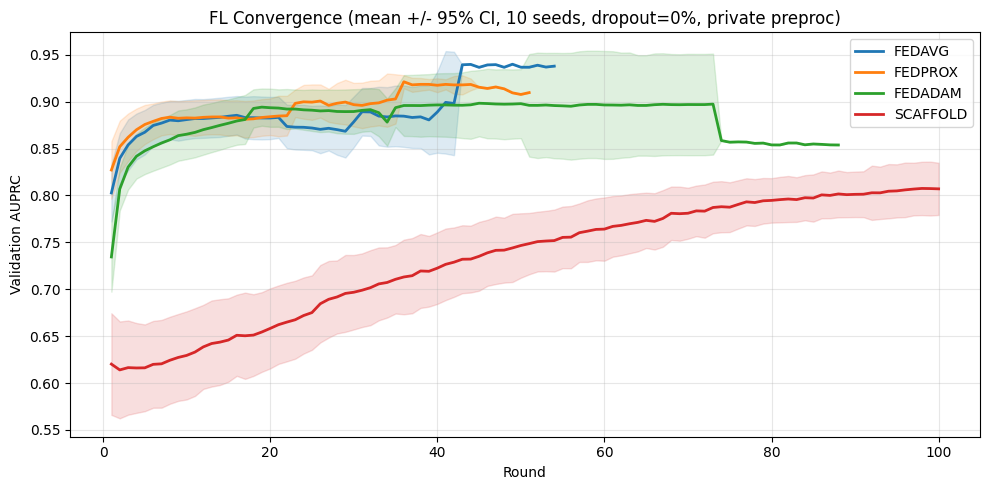

Saved: fl_convergence.png


In [36]:
fig, ax = plt.subplots(figsize=(10, 5))
for algo, color in zip(algorithms, plt.rcParams["axes.prop_cycle"].by_key()["color"]):
    hist_df = all_results[f"{algo}_d0"]["history_df"]
    pivot   = hist_df.pivot_table(index="round", columns="seed",
                                   values="val_auprc", aggfunc="first")
    arr  = pivot.values
    mean = np.nanmean(arr, axis=1)
    sd   = np.nanstd(arr, axis=1)
    n    = np.sum(~np.isnan(arr), axis=1)
    ci_h = 1.96 * sd / np.sqrt(np.maximum(n, 1))
    r_x  = pivot.index.values
    ax.plot(r_x, mean, color=color, linewidth=2, label=algo.upper())
    ax.fill_between(r_x, mean - ci_h, mean + ci_h, color=color, alpha=0.15)
ax.set_xlabel("Round"); ax.set_ylabel("Validation AUPRC")
ax.set_title("FL Convergence (mean +/- 95% CI, 10 seeds, dropout=0%, private preproc)")
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("fl_convergence.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: fl_convergence.png")


## 17. Communication Cost Analysis

For communication analysis, we report an explicit model-size based cost:

`model_size_bytes x rounds_to_converge x mean_active_clients`

Here `rounds_to_converge` uses the validation-best `best_round`; `rounds_run_mean` is
also retained to show the extra early-stopping overhead. We also report the bidirectional
variant and a protocol-adjusted estimate. SCAFFOLD has a larger payload because control
variates are transmitted alongside model parameters.


Model parameters: 3,905
State-dict tensor size: 0.0156 MB
Serialized checkpoint size: 0.0208 MB

Communication cost table (private dropout scenarios):
algorithm  dropout_pct preprocess_mode  model_params  model_size_mb  serialized_model_size_mb  rounds_to_converge_mean  rounds_run_mean  active_clients_mean  model_x_rounds_x_clients_mb  bidirectional_model_x_rounds_x_clients_mb  payload_multiplier  protocol_adjusted_comm_mb  logged_total_comm_mb_mean  final_auprc_mean  auprc_per_protocol_mb
   FEDAVG            0         private          3905         0.0156                    0.0208                  18.5000          33.5000               4.0000                       1.1577                                     2.3153              1.0000                     2.3153                     4.1926            0.8832                 0.3815
   FEDAVG           25         private          3905         0.0156                    0.0208                  25.8000          40.8000               3.0000     

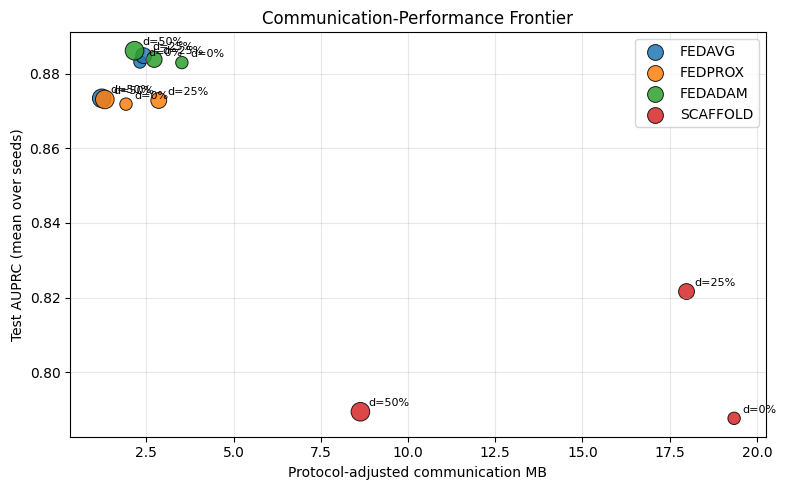

In [37]:
_sample = list(all_results["fedavg_d0"]["models_by_seed"].values())[0]
state_model_bytes = num_bytes(get_params(_sample))
serialized_model_bytes = model_size_bytes(_sample)
n_params = count_params(_sample)

print(f"Model parameters: {n_params:,}")
print(f"State-dict tensor size: {state_model_bytes / (1024 ** 2):.4f} MB")
print(f"Serialized checkpoint size: {serialized_model_bytes / (1024 ** 2):.4f} MB\n")


def build_communication_cost_table(all_results, algorithms, dropouts=(0, 25, 50)):
    rows = []
    for algo in algorithms:
        for d in dropouts:
            key = f"{algo}_d{d}"
            if key not in all_results:
                continue
            res = all_results[key]
            gdf = res["global_df"]
            hdf = res.get("history_df", pd.DataFrame())
            rounds_run_mean = float(gdf["rounds_run"].mean())
            if "best_round" in gdf.columns:
                best_rounds = pd.to_numeric(gdf["best_round"], errors="coerce").replace(-1, np.nan)
                rounds_mean = (float(best_rounds.mean()) if best_rounds.notna().any()
                               else rounds_run_mean)
            else:
                rounds_mean = rounds_run_mean
            active_mean = (float(hdf["n_active"].mean())
                           if len(hdf) and "n_active" in hdf.columns
                           else max(1.0, 4.0 * (1.0 - d / 100.0)))
            model_round_client_mb = (state_model_bytes * rounds_mean * active_mean) / (1024 ** 2)
            bidirectional_mb = 2.0 * model_round_client_mb
            payload_multiplier = 2.0 if algo.lower().startswith("scaffold") else 1.0
            protocol_adjusted_mb = bidirectional_mb * payload_multiplier
            logged_total = float(gdf["total_comm_mb"].mean()) if "total_comm_mb" in gdf else np.nan
            rows.append({
                "algorithm": algo.upper(),
                "dropout_pct": d,
                "preprocess_mode": res["preprocess_mode"],
                "model_params": int(n_params),
                "model_size_mb": state_model_bytes / (1024 ** 2),
                "serialized_model_size_mb": serialized_model_bytes / (1024 ** 2),
                "rounds_to_converge_mean": rounds_mean,
                "rounds_run_mean": rounds_run_mean,
                "active_clients_mean": active_mean,
                "model_x_rounds_x_clients_mb": model_round_client_mb,
                "bidirectional_model_x_rounds_x_clients_mb": bidirectional_mb,
                "payload_multiplier": payload_multiplier,
                "protocol_adjusted_comm_mb": protocol_adjusted_mb,
                "logged_total_comm_mb_mean": logged_total,
                "final_auprc_mean": float(gdf["auprc"].mean()),
                "auprc_per_protocol_mb": (float(gdf["auprc"].mean()) / protocol_adjusted_mb
                                           if protocol_adjusted_mb > 0 else np.nan),
            })
    return pd.DataFrame(rows)


comm_cost_df = build_communication_cost_table(all_results, algorithms)
comm_cost_df.to_csv("fl_communication_cost_by_cell.csv", index=False)
print("Communication cost table (private dropout scenarios):")
print(comm_cost_df.to_string(index=False, float_format="%.4f"))
print("Saved: fl_communication_cost_by_cell.csv")

# Backward-compatible frontier plot using protocol-adjusted communication estimate.
comm_df = comm_cost_df.rename(columns={
    "algorithm": "algo",
    "dropout_pct": "dropout",
    "protocol_adjusted_comm_mb": "total_comm_mb",
    "final_auprc_mean": "final_auprc",
    "auprc_per_protocol_mb": "auprc_per_mb",
    "rounds_to_converge_mean": "rounds_mean",
})

fig, ax = plt.subplots(figsize=(8, 5))
for algo, color in zip([a.upper() for a in algorithms],
                        plt.rcParams["axes.prop_cycle"].by_key()["color"]):
    sub = comm_df[comm_df["algo"] == algo]
    ax.scatter(sub["total_comm_mb"], sub["final_auprc"],
               s=80 + sub["dropout"] * 2, color=color, label=algo,
               edgecolor="black", linewidth=0.7, alpha=0.85)
    for _, r in sub.iterrows():
        ax.annotate(f"d={int(r['dropout'])}%",
                    (r["total_comm_mb"], r["final_auprc"]),
                    textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.set_xlabel("Protocol-adjusted communication MB")
ax.set_ylabel("Test AUPRC (mean over seeds)")
ax.set_title("Communication-Performance Frontier")
ax.grid(True, alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig("fl_comm_frontier.png", dpi=150, bbox_inches="tight")
plt.show()


## 18. Probabilistic Performance - Brier Score and Reliability Diagrams

We report Brier score and reliability diagrams for each algorithm at dropout = 0%
using the best-seed model (by val AUPRC). Brier is a proper scoring rule combining
calibration and refinement, so it is reported as overall probabilistic performance
rather than as a calibration estimate; the reliability diagram is the only
calibration-specific artifact here. Probabilistic performance before vs. after
personalization is reported in Section 22.

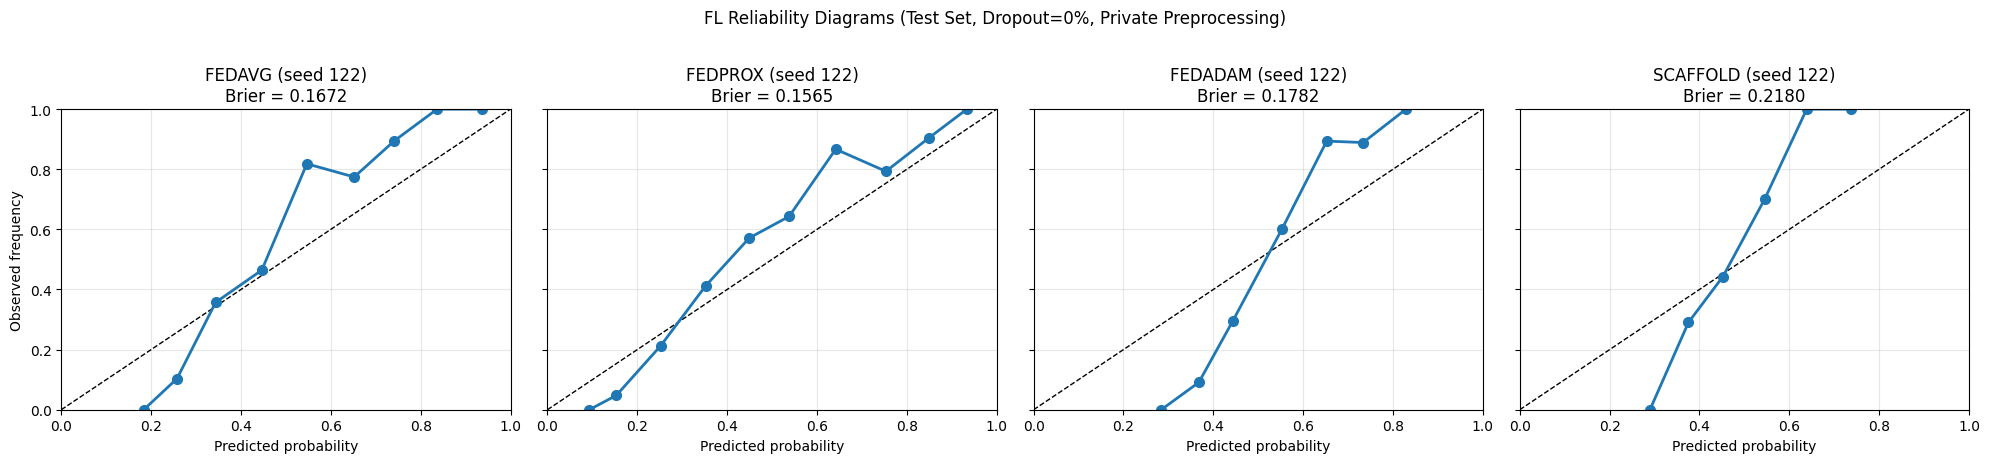

    algo  best_seed  global_brier
  fedavg        122      0.167239
 fedprox        122      0.156496
 fedadam        122      0.178231
scaffold        122      0.218039


In [38]:
def reliability_curve(y_true, y_prob, n_bins=10):
    y_true = np.asarray(y_true).astype(int).ravel()
    y_prob = np.asarray(y_prob, dtype=float).ravel()
    bins = np.linspace(0, 1, n_bins + 1)
    idx  = np.clip(np.digitize(y_prob, bins) - 1, 0, n_bins - 1)
    obs, pred = [], []
    for b in range(n_bins):
        mask = (idx == b)
        if mask.sum() == 0:
            obs.append(np.nan); pred.append(np.nan); continue
        obs.append(float(y_true[mask].mean()))
        pred.append(float(y_prob[mask].mean()))
    return np.array(obs), np.array(pred)


n_alg = len(algorithms)
fig, axes = plt.subplots(1, n_alg, figsize=(5 * n_alg, 4.5), sharey=True)
axes = np.atleast_1d(axes)
calib_summary = []
for ax, algo in zip(axes, algorithms):
    key      = f"{algo}_d0"
    gdf      = all_results[key]["global_df"]
    best_seed = int(gdf.sort_values("best_val_auprc", ascending=False).iloc[0]["seed"])
    y_te   = all_results[key]["out_by_seed"][best_seed]["y_test"]
    y_prob = all_results[key]["out_by_seed"][best_seed]["y_prob"]
    y_te = np.asarray(y_te).astype(int).ravel()
    y_prob = np.asarray(y_prob, dtype=float).ravel()
    brier  = brier_score_loss(y_te, y_prob)
    obs, pred = reliability_curve(y_te, y_prob, n_bins=10)
    ax.plot([0, 1], [0, 1], "k--", linewidth=1)
    valid = ~np.isnan(obs)
    ax.plot(pred[valid], obs[valid], "o-", linewidth=2, markersize=7)
    ax.set_title(f"{algo.upper()} (seed {best_seed})\nBrier = {brier:.4f}")
    ax.set_xlabel("Predicted probability")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.grid(True, alpha=0.3)
    calib_summary.append({"algo": algo, "best_seed": best_seed, "global_brier": brier})
axes[0].set_ylabel("Observed frequency")
plt.suptitle("FL Reliability Diagrams (Test Set, Dropout=0%, Private Preprocessing)",
             y=1.02)
plt.tight_layout()
plt.savefig("fl_reliability.png", dpi=150, bbox_inches="tight")
plt.show()
print(pd.DataFrame(calib_summary).to_string(index=False))


## 19. Personalized Federated Learning Framework - *Secondary Analysis*

A purely global FL model optimizes one weight vector for all clients even when optimal
weights differ across hospitals. We therefore evaluate a Personalized FL (PFL) framework
on top of the trained global model. This section is intentionally framed as a
**secondary fairness and probabilistic-performance analysis**, not as a guaranteed primary success claim.

### Framework components

1. **Three personalization modes:**
   * `head_only` - freeze the body, fine-tune only the final linear layer.
   * `partial` - freeze the first hidden block, fine-tune the second block and head.
   * `full` - fine-tune all weights.
2. **Per-client threshold optimization.** After fine-tuning, re-tune the decision
   threshold on each hospital's local validation set.
3. **Validation-only configuration screening.** Grid over mode, fine-tuning epochs, and
   learning rate using validation macro per-hospital AUPRC. The external test set is not
   used to select the PFL configuration.
4. **Small-data safeguards.** BatchNorm running statistics are frozen during local
   fine-tuning; local FT uses weight decay, gradient clipping, proximal regularization,
   and interpolation back toward the global model.
5. **Multi-seed evaluation.** The selected configuration is evaluated across all reporting
   seeds, with macro, worst-hospital, fairness, and calibration metrics.

### Comparator definition

"Before" uses the global model with a per-client optimized threshold. This gives the global
model the same threshold flexibility as the personalized model, so deltas mostly reflect
weight personalization rather than threshold tuning alone.

### Claim discipline

PFL claims are accepted only if they survive the **paired bootstrap** of Section
22.11, not the seed-level Holm-Bonferroni test. On this corpus the seed-only test
returned macro Brier -0.005 [-0.007, -0.003], p_Holm = 0.008, while the paired
bootstrap returned -0.006 [-0.033, +0.021], p = 0.622. The bootstrap result is the
one reported. A numerically consistent direction across three of four hospitals is
not sufficient; the paper reports the negative result.


In [39]:
def freeze_for_mode(model, mode):
    """Set requires_grad for personalization mode.

    head_only: freeze body entirely, train only the head Linear.
    partial: freeze first hidden block (indices 0-3 in model.body Sequential),
                train second block (indices 4-7) and the head.
    full: train all parameters (no freezing).
    """
    if mode not in {"head_only", "partial", "full"}:
        raise ValueError(f"Unknown personalization mode: {mode!r}")
    for p in model.parameters():
        p.requires_grad = True
    if mode == "head_only":
        for p in model.body.parameters():
            p.requires_grad = False
    elif mode == "partial":
        for idx, layer in enumerate(model.body):
            for p in layer.parameters():
                p.requires_grad = (idx >= 4)
    return model


def set_batchnorm_eval(model):
    """Keep BatchNorm running statistics fixed during local personalization."""
    for module in model.modules():
        if isinstance(module, nn.modules.batchnorm._BatchNorm):
            module.eval()
    return model


def interpolate_state_dict(base_state, tuned_state, alpha):
    """Blend tuned weights back toward the global checkpoint to reduce local drift."""
    alpha = float(np.clip(alpha, 0.0, 1.0))
    out = {}
    for k, tuned in tuned_state.items():
        base = base_state[k].detach().to(device=tuned.device)
        if torch.is_floating_point(tuned):
            base = base.to(dtype=tuned.dtype)
            out[k] = base + alpha * (tuned - base)
        else:
            out[k] = tuned.clone()
    return out


def personalize_client(global_state_dict, input_dim,
                        X_tr, y_tr, X_va, y_va, X_te=None, y_te=None,
                        mode="head_only", ft_epochs=5, lr=1e-4,
                        dropout=0.3, device=DEVICE, batch_size=BATCH_SIZE,
                        weight_decay=1e-4, grad_clip=1.0, prox_mu=1e-4,
                        interp_alpha=0.75, freeze_bn_stats=True,
                        evaluate_test=True):
    """Fine-tune global model weights on one client and evaluate.

    X_*, y_* are numpy arrays (as stored in prepare_federated_data client_data packs).

    Returns dict with:
      before: global model metrics at threshold=0.5
      before_topt: global model metrics with per-client val-optimized threshold
      after: fine-tuned model metrics with per-client val-optimized threshold
      thresh_before: global model val-optimized threshold
      thresh_after: fine-tuned model val-optimized threshold
      p_te_before: test probabilities from global model
      p_te_after: test probabilities from fine-tuned model
      y_te: test labels (int)
      val_*: validation metrics for leakage-free configuration screening
      n_train: number of local training samples
    """
 # Global model snapshot
    model_g = MLP(input_dim=input_dim, dropout=dropout).to(device)
    model_g.load_state_dict(global_state_dict)
    model_g.eval()

    va_loader = make_loader(X_va, y_va, shuffle=False, batch_size=batch_size)
    use_test = (evaluate_test and X_te is not None and y_te is not None and len(y_te) > 0)
    te_loader = (make_loader(X_te, y_te, shuffle=False, batch_size=batch_size)
                 if use_test else None)

    y_va_arr, p_va_g = evaluate_loader(model_g, va_loader, device)
    t_bef, _ = find_best_threshold(y_va_arr, p_va_g, metric="f1")
    metrics_before_val      = compute_metrics(y_va_arr, p_va_g, threshold=0.5)
    metrics_before_topt_val = compute_metrics(y_va_arr, p_va_g, threshold=t_bef)

    if use_test:
        y_te_arr, p_te_g = evaluate_loader(model_g, te_loader, device)
        metrics_before      = compute_metrics(y_te_arr, p_te_g, threshold=0.5)
        metrics_before_topt = compute_metrics(y_te_arr, p_te_g, threshold=t_bef)
    else:
        y_te_arr, p_te_g = y_va_arr, p_va_g
        metrics_before      = metrics_before_val
        metrics_before_topt = metrics_before_topt_val

 # Fine-tuning
    model_ft = MLP(input_dim=input_dim, dropout=dropout).to(device)
    model_ft.load_state_dict(global_state_dict)
    freeze_for_mode(model_ft, mode)

    pos_w     = torch.tensor([compute_pos_weight(y_tr)], device=device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_w)
    trainable_named = [(n, p) for n, p in model_ft.named_parameters() if p.requires_grad]
    trainable = [p for _, p in trainable_named]
    global_named = {n: p.detach().clone() for n, p in trainable_named}
    opt       = (torch.optim.Adam(trainable, lr=lr, weight_decay=weight_decay)
                 if trainable else None)

    tr_loader = make_loader(X_tr, y_tr, shuffle=True, batch_size=batch_size)

    best_val_auprc = -np.inf
    best_state     = copy.deepcopy(model_ft.state_dict())
    no_improve     = 0
    FT_PATIENCE    = 5

    for _ in range(ft_epochs):
        if opt is not None:
            model_ft.train()
            if freeze_bn_stats:
                set_batchnorm_eval(model_ft)
            for xb, yb in tr_loader:
                xb = xb.to(device).float(); yb = yb.to(device).float()
                opt.zero_grad()
                loss = criterion(model_ft(xb), yb)
                if prox_mu > 0:
                    prox = sum(torch.sum((p - global_named[n]) ** 2)
                               for n, p in trainable_named)
                    loss = loss + (prox_mu / 2.0) * prox
                loss.backward()
                if grad_clip is not None and grad_clip > 0:
                    nn.utils.clip_grad_norm_(trainable, grad_clip)
                opt.step()
        y_va_e, p_va_e = evaluate_loader(model_ft, va_loader, device)
        auprc_va = (average_precision_score(y_va_e, p_va_e)
                    if len(np.unique(y_va_e)) >= 2 else np.nan)
        if not np.isnan(auprc_va) and auprc_va > best_val_auprc:
            best_val_auprc = auprc_va
            best_state = copy.deepcopy(model_ft.state_dict())
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= FT_PATIENCE:
                break

    if interp_alpha < 1.0:
        best_state = interpolate_state_dict(global_state_dict, best_state, interp_alpha)
    model_ft.load_state_dict(best_state); model_ft.eval()
    y_va_ft, p_va_ft = evaluate_loader(model_ft, va_loader, device)
    t_aft, _ = find_best_threshold(y_va_ft, p_va_ft, metric="f1")
    metrics_after_val = compute_metrics(y_va_ft, p_va_ft, threshold=t_aft)

    if use_test:
        y_te_ft, p_te_ft = evaluate_loader(model_ft, te_loader, device)
        metrics_after = compute_metrics(y_te_ft, p_te_ft, threshold=t_aft)
    else:
        y_te_ft, p_te_ft = y_va_ft, p_va_ft
        metrics_after = metrics_after_val

    return {"before": metrics_before, "before_topt": metrics_before_topt,
            "val_before": metrics_before_val, "val_before_topt": metrics_before_topt_val,
            "val_after": metrics_after_val,
            "after": metrics_after, "thresh_before": t_bef, "thresh_after": t_aft,
            "p_te_before": p_te_g, "p_te_after": p_te_ft, "y_te": y_te_arr,
            "n_train": int(len(X_tr)), "best_val_auprc": best_val_auprc}


print("Personalization framework defined.")


Personalization framework defined.


## 20. Personalization Configuration Screening (Validation, Multi-Seed)

We screen a 3 x 3 x 2 grid of `(mode, ft_epochs, lr)` across a small validation-seed
panel. The selection metric is **macro per-hospital validation AUPRC**; the external
test split is not evaluated during screening. The winner is then frozen and evaluated
across all 10 reporting seeds in Section 21.


In [40]:
best_fl_strategy = max(algorithms,
    key=lambda a: all_results[f"{a}_d0"]["global_df"]["best_val_auprc"].mean())
print(f"Best global FL strategy by validation AUPRC (private, d=0%): {best_fl_strategy.upper()}")

PERS_MODES   = ["head_only", "partial", "full"]
PERS_FTEPOCH = [5, 10, 20]
PERS_LRS     = [1e-4, 5e-4]
SCREEN_SEEDS = (42, 52, 62)

# Local-FT safeguards for small client datasets.
PERS_WEIGHT_DECAY     = 1e-4
PERS_GRAD_CLIP        = 1.0
PERS_PROX_MU          = 1e-4
PERS_INTERP_ALPHA     = 0.75
PERS_FREEZE_BN_STATS  = True


def _load_screen_global_state(seed):
    cached_models = all_results[f"{best_fl_strategy}_d0"].get("models_by_seed", {})
    if seed in cached_models:
        return cached_models[seed].state_dict()

    ckpt_path = os.path.join(CHECKPOINT_DIR,
        f"{best_fl_strategy}_private_0pct_seed{seed}.pt")
    if os.path.exists(ckpt_path):
        ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
        return ckpt["model_state_dict"]

    cfg = all_results[f"{best_fl_strategy}_d0"]["best_config"]
    out = run_fl_single(df_tv_s, df_te_s, seed=seed, algorithm=best_fl_strategy,
                         dropout_rate=0.0, min_active=4, verbose=False,
                         preprocess_mode="private", **cfg)
    return out["model"].state_dict()


df_tv_s, df_te_s = create_fixed_external_test_split(df, seed=TEST_SEED)
screen_seed_packs = []
for screen_seed in SCREEN_SEEDS:
    prep_s = prepare_federated_data(df_tv_s, df_te_s, seed=screen_seed, mode="private")
    screen_seed_packs.append({
        "seed": screen_seed,
        "client_data": prep_s["client_data"],
        "hospitals": prep_s["hospitals"],
        "input_dim": prep_s["X_train"].shape[1],
        "global_state": _load_screen_global_state(screen_seed),
    })

screen_records = []
n_cfgs = len(PERS_MODES) * len(PERS_FTEPOCH) * len(PERS_LRS)
idx = 0
for mode in PERS_MODES:
    for ft_e in PERS_FTEPOCH:
        for lr_ in PERS_LRS:
            idx += 1
            val_auprc_vals, val_f1_vals = [], []
            for spack in screen_seed_packs:
                for hname in spack["hospitals"]:
                    pack = spack["client_data"].get(hname, {})
                    X_tr = pack.get("X_train"); y_tr = pack.get("y_train")
                    X_va = pack.get("X_val");   y_va = pack.get("y_val")
                    if X_va is None or len(y_va) == 0 or len(np.unique(y_va)) < 2:
                        continue
                    res = personalize_client(spack["global_state"], spack["input_dim"],
                        X_tr, y_tr, X_va, y_va,
                        mode=mode, ft_epochs=ft_e, lr=lr_, evaluate_test=False,
                        weight_decay=PERS_WEIGHT_DECAY, grad_clip=PERS_GRAD_CLIP,
                        prox_mu=PERS_PROX_MU, interp_alpha=PERS_INTERP_ALPHA,
                        freeze_bn_stats=PERS_FREEZE_BN_STATS)
                    val_auprc_vals.append(res["val_after"]["auprc"])
                    val_f1_vals.append(res["val_after"]["f1"])
            rec = {"mode": mode, "ft_epochs": ft_e, "lr": lr_,
                   "screen_seeds": ",".join(map(str, SCREEN_SEEDS)),
                   "weight_decay": PERS_WEIGHT_DECAY,
                   "grad_clip": PERS_GRAD_CLIP,
                   "prox_mu": PERS_PROX_MU,
                   "interp_alpha": PERS_INTERP_ALPHA,
                   "freeze_bn_stats": PERS_FREEZE_BN_STATS,
                   "macro_val_auprc": float(np.nanmean(val_auprc_vals)),
                   "worst_val_auprc": float(np.nanmin(val_auprc_vals)),
                   "macro_val_f1":    float(np.nanmean(val_f1_vals))}
            screen_records.append(rec)
            print(f"  [{idx:2d}/{n_cfgs}] {mode:<10s} ft={ft_e:2d} lr={lr_:.0e}  "
                  f"macro_val_auprc={rec['macro_val_auprc']:.4f}  "
                  f"worst_val={rec['worst_val_auprc']:.4f}")

screen_df = (pd.DataFrame(screen_records)
.sort_values(["macro_val_auprc", "worst_val_auprc"], ascending=False)
.reset_index(drop=True))
print("\nScreening summary (sorted by validation macro AUPRC):")
print(screen_df.to_string(index=False, float_format="%.4f"))

best_row      = screen_df.iloc[0]
PERS_MODE     = best_row["mode"]
PERS_FTEPOCHS = int(best_row["ft_epochs"])
PERS_LR       = float(best_row["lr"])
print(f"\nSelected: mode={PERS_MODE}, ft_epochs={PERS_FTEPOCHS}, lr={PERS_LR}, "
      f"wd={PERS_WEIGHT_DECAY}, prox_mu={PERS_PROX_MU}, "
      f"interp_alpha={PERS_INTERP_ALPHA}, freeze_bn_stats={PERS_FREEZE_BN_STATS}")


Best global FL strategy by validation AUPRC (private, d=0%): FEDPROX
  [ 1/18] head_only  ft= 5 lr=1e-04  macro_val_auprc=0.9027  worst_val=0.7682
  [ 2/18] head_only  ft= 5 lr=5e-04  macro_val_auprc=0.9027  worst_val=0.7682
  [ 3/18] head_only  ft=10 lr=1e-04  macro_val_auprc=0.9027  worst_val=0.7682
  [ 4/18] head_only  ft=10 lr=5e-04  macro_val_auprc=0.9033  worst_val=0.7682
  [ 5/18] head_only  ft=20 lr=1e-04  macro_val_auprc=0.9027  worst_val=0.7682
  [ 6/18] head_only  ft=20 lr=5e-04  macro_val_auprc=0.9027  worst_val=0.7682
  [ 7/18] partial    ft= 5 lr=1e-04  macro_val_auprc=0.9027  worst_val=0.7682
  [ 8/18] partial    ft= 5 lr=5e-04  macro_val_auprc=0.9038  worst_val=0.7682
  [ 9/18] partial    ft=10 lr=1e-04  macro_val_auprc=0.9019  worst_val=0.7682
  [10/18] partial    ft=10 lr=5e-04  macro_val_auprc=0.9078  worst_val=0.7682
  [11/18] partial    ft=20 lr=1e-04  macro_val_auprc=0.9033  worst_val=0.7682
  [12/18] partial    ft=20 lr=5e-04  macro_val_auprc=0.9051  worst_val=0.

## 21. Multi-Seed Personalization - Selected Configuration

Run `(mode*, ft_epochs*, lr*)` for all 10 seeds. Per (seed, hospital) we record:

* `before_*`  - global model at threshold 0.5
* `beforeT_*` - global model with local threshold-opt on this hospital's val set
* `after_*`   - personalized model with local threshold-opt

Deltas = `after - beforeT` to isolate the weight-personalization effect.

In [41]:
df_tv_f, df_te_f = create_fixed_external_test_split(df, seed=TEST_SEED)
pers_records = []

pfl_preds = {s: {"before": {}, "after": {}} for s in SEEDS}

for seed in SEEDS:
    ckpt_p = os.path.join(CHECKPOINT_DIR,
        f"{best_fl_strategy}_private_0pct_seed{seed}.pt")
    if not os.path.exists(ckpt_p):
        print(f"  [skip] missing: {ckpt_p}"); continue
    ckpt = torch.load(ckpt_p, map_location=DEVICE, weights_only=False)
    gstate = ckpt["model_state_dict"]

    prep = prepare_federated_data(df_tv_f, df_te_f, seed=seed, mode="private")
    cd   = prep["client_data"]
    hosps_seed = prep["hospitals"]
    in_dim_seed = prep["X_train"].shape[1]

    for hname in hosps_seed:
        pack = cd.get(hname, {})
        X_tr = pack.get("X_train"); y_tr = pack.get("y_train")
        X_va = pack.get("X_val");   y_va = pack.get("y_val")
        X_te = pack.get("X_test");  y_te = pack.get("y_test")
        if X_te is None or len(y_te) == 0 or len(np.unique(y_te)) < 2:
            continue
        res = personalize_client(gstate, in_dim_seed,
            X_tr, y_tr, X_va, y_va, X_te, y_te,
            mode=PERS_MODE, ft_epochs=PERS_FTEPOCHS, lr=PERS_LR,
            weight_decay=PERS_WEIGHT_DECAY, grad_clip=PERS_GRAD_CLIP,
            prox_mu=PERS_PROX_MU, interp_alpha=PERS_INTERP_ALPHA,
            freeze_bn_stats=PERS_FREEZE_BN_STATS)
        rec = {"seed": seed, "hospital": hname, "mode": PERS_MODE,
               "weight_decay": PERS_WEIGHT_DECAY, "grad_clip": PERS_GRAD_CLIP,
               "prox_mu": PERS_PROX_MU, "interp_alpha": PERS_INTERP_ALPHA,
               "freeze_bn_stats": PERS_FREEZE_BN_STATS,
               "n_train": res["n_train"], "n_test": int(len(y_te)),
               "prevalence": float(np.mean(y_te)),
               "thresh_before": res["thresh_before"],
               "thresh_after":  res["thresh_after"]}
        for k, v in res["before"].items():
            rec[f"before_{k}"] = v
        for k, v in res["before_topt"].items():
            rec[f"beforeT_{k}"] = v
        for k, v in res["after"].items():
            rec[f"after_{k}"] = v
        rec["delta_auprc"] = res["after"]["auprc"] - res["before_topt"]["auprc"]
        rec["delta_auroc"] = res["after"]["auroc"] - res["before_topt"]["auroc"]
        rec["delta_f1"]    = res["after"]["f1"]    - res["before_topt"]["f1"]
        rec["delta_brier"] = res["after"]["brier"] - res["before_topt"]["brier"]
        pers_records.append(rec)
        pfl_preds[seed]["before"][hname] = (
            np.asarray(res["y_te"]).astype(int),
            np.asarray(res["p_te_before"], dtype=float),
            float(res["thresh_before"]))
        pfl_preds[seed]["after"][hname] = (
            np.asarray(res["y_te"]).astype(int),
            np.asarray(res["p_te_after"], dtype=float),
            float(res["thresh_after"]))

# Register the global-FL and personalized predictions as a matched pair, so the
# PFL claim can be tested with the SAME bootstrap machinery as every other
# comparison. Reporting a seed-only p-value here while bootstrapping everything
# else would be methodologically indefensible.
for seed in SEEDS:
    for tag, algo in [("before", "GlobalFL"), ("after", "PFL")]:
        packs = pfl_preds[seed][tag]
        if packs:
            register_predictions(
                "pfl", algo, seed, packs,
                float(np.mean([t for (_, _, t) in packs.values()])))

pers_df = pd.DataFrame(pers_records)
print(f"Personalization records: {len(pers_df)}  (seeds x hospitals)")
print(pers_df[["seed","hospital","n_train",
               "beforeT_auprc","after_auprc",
               "delta_auprc","thresh_after"]].head(12)
.to_string(index=False, float_format="%.4f"))


Personalization records: 40  (seeds x hospitals)
 seed      hospital  n_train  beforeT_auprc  after_auprc  delta_auprc  thresh_after
   42   Switzerland       88         0.8776       0.8776       0.0000        0.1000
   42       Hungary      211         0.7964       0.7990       0.0025        0.5300
   42 VA Long Beach      144         0.8621       0.8645       0.0024        0.3000
   42     Cleveland      219         0.9478       0.9478       0.0000        0.5600
   52   Switzerland       88         0.9655       0.9655       0.0000        0.3200
   52       Hungary      211         0.8135       0.8118      -0.0017        0.2000
   52 VA Long Beach      144         0.8864       0.8895       0.0031        0.4000
   52     Cleveland      219         0.9541       0.9541       0.0000        0.4100
   62   Switzerland       88         0.8759       0.8741      -0.0018        0.1000
   62       Hungary      211         0.8050       0.8102       0.0052        0.4100
   62 VA Long Beach      14

## 22. Personalization Results

In [42]:
# 22.1 Per-seed summary
per_seed_pfl = (pers_df.groupby("seed").agg(
    macro_auprc_before=("beforeT_auprc", "mean"),
    macro_auprc_after =("after_auprc",   "mean"),
    macro_f1_before   =("beforeT_f1",    "mean"),
    macro_f1_after    =("after_f1",      "mean"),
    worst_auprc_before=("beforeT_auprc", "min"),
    worst_auprc_after =("after_auprc",   "min"),
    brier_before      =("beforeT_brier", "mean"),
    brier_after       =("after_brier",   "mean"),
).reset_index())
per_seed_pfl["delta_macro_auprc"] = (per_seed_pfl["macro_auprc_after"]
                                      - per_seed_pfl["macro_auprc_before"])
per_seed_pfl["delta_worst_auprc"] = (per_seed_pfl["worst_auprc_after"]
                                      - per_seed_pfl["worst_auprc_before"])
print("=" * 90)
print("22.1  PER-SEED PFL SUMMARY")
print("=" * 90)
print(per_seed_pfl.to_string(index=False, float_format="%.4f"))


22.1  PER-SEED PFL SUMMARY
 seed  macro_auprc_before  macro_auprc_after  macro_f1_before  macro_f1_after  worst_auprc_before  worst_auprc_after  brier_before  brier_after  delta_macro_auprc  delta_worst_auprc
   42              0.8710             0.8722           0.8288          0.8288              0.7964             0.7990        0.1658       0.1622             0.0012             0.0025
   52              0.9049             0.9052           0.8353          0.8384              0.8135             0.8118        0.1547       0.1504             0.0003            -0.0017
   62              0.8747             0.8758           0.8344          0.8344              0.8050             0.8102        0.1641       0.1556             0.0011             0.0052
   72              0.8897             0.8917           0.8400          0.8400              0.7793             0.7830        0.1587       0.1556             0.0020             0.0037
   82              0.8755             0.8698           0.8264  

In [43]:
# 22.2 Macro paired Wilcoxon
def _paired(a, b, label):
    try:
        _, p = wilcoxon(a, b, zero_method="wilcox")
    except Exception:
        p = 1.0
    mu_a, lo_a, hi_a = ci_95(a); mu_b, lo_b, hi_b = ci_95(b)
    return {"metric": label,
            "before_mean": mu_b, "before_lo": lo_b, "before_hi": hi_b,
            "after_mean":  mu_a, "after_lo":  lo_a, "after_hi":  hi_a,
            "delta": mu_a - mu_b, "p_raw": p, "cohen_d": cohens_d_paired(a, b)}

macro_pfl_tests = [
    _paired(per_seed_pfl["macro_auprc_after"].values,
            per_seed_pfl["macro_auprc_before"].values, "macro_auprc"),
    _paired(per_seed_pfl["macro_f1_after"].values,
            per_seed_pfl["macro_f1_before"].values,    "macro_f1"),
    _paired(per_seed_pfl["worst_auprc_after"].values,
            per_seed_pfl["worst_auprc_before"].values, "worst_auprc"),
    _paired(per_seed_pfl["brier_after"].values,
            per_seed_pfl["brier_before"].values,       "macro_brier"),
]
p_adj = holm_bonferroni([r["p_raw"] for r in macro_pfl_tests])
for r, pa in zip(macro_pfl_tests, p_adj):
    r["p_holm"] = pa; r["sig"] = pa < ALPHA
macro_pfl_df = pd.DataFrame(macro_pfl_tests)

print("=" * 108)
print("22.2  MACRO/WORST - Paired Wilcoxon vs Global+Threshold-Opt")
print("=" * 108)
print(f"{'Metric':<13s} {'Before':>24s} {'After':>24s} {'Delta':>9s} "
      f"{'p_raw':>8s} {'p_holm':>8s} {'cohen_d':>9s}  sig")
print("-" * 108)
for r in macro_pfl_tests:
    sig = "*" if r["sig"] else " "
    print(f"{r['metric']:<13s} "
          f"{r['before_mean']:.4f}[{r['before_lo']:.3f},{r['before_hi']:.3f}]"
          f"  {r['after_mean']:.4f}[{r['after_lo']:.3f},{r['after_hi']:.3f}]"
          f"  {r['delta']:+8.4f}  {r['p_raw']:.4f}  {r['p_holm']:.4f} "
          f" {r['cohen_d']:+8.3f}   {sig}")


22.2  MACRO/WORST - Paired Wilcoxon vs Global+Threshold-Opt
Metric                          Before                    After     Delta    p_raw   p_holm   cohen_d  sig
------------------------------------------------------------------------------------------------------------
macro_auprc   0.8810[0.871,0.891]  0.8810[0.870,0.892]   -0.0000  0.7695  0.9844    -0.003    
macro_f1      0.8309[0.827,0.835]  0.8320[0.829,0.835]   +0.0010  0.2188  0.6562    +0.514    
worst_auprc   0.8013[0.788,0.815]  0.8025[0.788,0.817]   +0.0012  0.4922  0.9844    +0.256    
macro_brier   0.1657[0.160,0.172]  0.1607[0.155,0.167]   -0.0050  0.0020  0.0078    -1.781   *


In [44]:
# 22.3 Per-hospital before-vs-after
hosp_pfl_rows = []
for mlab, bc, ac in [("auprc","beforeT_auprc","after_auprc"),
                      ("auroc","beforeT_auroc","after_auroc"),
                      ("f1",   "beforeT_f1",  "after_f1"),
                      ("brier","beforeT_brier","after_brier")]:
    raw_p, rows = [], []
    for hname in pers_df["hospital"].unique():
        sub = pers_df[pers_df["hospital"] == hname]
        if len(sub) < 2:
            continue
        a = sub[ac].values; b = sub[bc].values
        try:
            _, p = wilcoxon(a, b, zero_method="wilcox")
        except Exception:
            p = 1.0
        raw_p.append(p)
        rows.append({"hospital": hname, "metric": mlab,
                      "before_mean": float(np.mean(b)),
                      "after_mean":  float(np.mean(a)),
                      "delta": float(np.mean(a) - np.mean(b)),
                      "p_raw": p, "cohen_d": cohens_d_paired(a, b)})
    p_adj = holm_bonferroni(raw_p)
    for r, pa in zip(rows, p_adj):
        r["p_holm"] = pa; r["sig"] = pa < ALPHA
    hosp_pfl_rows.extend(rows)
hosp_pfl_df = pd.DataFrame(hosp_pfl_rows)

print("=" * 112)
print("22.3  PER-HOSPITAL BEFORE-vs-AFTER  (Holm-Bonferroni within each metric)")
print("=" * 112)
print(f"{'Hospital':<14s} {'Metric':<7s} {'Before':>9s} {'After':>9s} "
      f"{'Delta':>9s} {'p_raw':>8s} {'p_holm':>8s} {'cohen_d':>9s}  sig")
print("-" * 112)
for _, r in hosp_pfl_df.iterrows():
    sig = "*" if r["sig"] else " "
    print(f"{r['hospital']:<14s} {r['metric']:<7s} "
          f"{r['before_mean']:9.4f} {r['after_mean']:9.4f} "
          f"{r['delta']:+9.4f} {r['p_raw']:8.4f} {r['p_holm']:8.4f} "
          f"{r['cohen_d']:+9.3f}   {sig}")


22.3  PER-HOSPITAL BEFORE-vs-AFTER  (Holm-Bonferroni within each metric)
Hospital       Metric     Before     After     Delta    p_raw   p_holm   cohen_d  sig
----------------------------------------------------------------------------------------------------------------
Switzerland    auprc      0.9146    0.9145   -0.0002   1.0000   1.0000    -0.316    
Hungary        auprc      0.8017    0.8025   +0.0008   0.6953   1.0000    +0.189    
VA Long Beach  auprc      0.8662    0.8674   +0.0012   0.3223   1.0000    +0.250    
Cleveland      auprc      0.9416    0.9398   -0.0018   0.8438   1.0000    -0.311    
Switzerland    auroc      0.5543    0.5522   -0.0022   1.0000   1.0000    -0.316    
Hungary        auroc      0.8288    0.8317   +0.0028   0.0645   0.2578    +0.604    
VA Long Beach  auroc      0.6717    0.6753   +0.0037   0.2109   0.6328    +0.381    
Cleveland      auroc      0.9574    0.9567   -0.0006   0.6250   1.0000    -0.326    
Switzerland    f1         0.9392    0.9372   -0.

In [45]:
# 22.4 Worst-hospital improvement
w_b = per_seed_pfl["worst_auprc_before"].values
w_a = per_seed_pfl["worst_auprc_after"].values
try:
    _, p_w = wilcoxon(w_a, w_b, zero_method="wilcox")
except Exception:
    p_w = 1.0
d_w = cohens_d_paired(w_a, w_b)
mu_b, lo_b, hi_b = ci_95(w_b); mu_a, lo_a, hi_a = ci_95(w_a)
print("=" * 80); print("22.4  WORST-HOSPITAL AUPRC - Personalization Effect"); print("=" * 80)
print(f"Before (global+topt): {mu_b:.4f}  [{lo_b:.4f}, {hi_b:.4f}]")
print(f"After  (personalized): {mu_a:.4f}  [{lo_a:.4f}, {hi_a:.4f}]")
print(f"Delta: {mu_a - mu_b:+.4f}")
print(f"Wilcoxon p: {p_w:.4f}")
print(f"Cohen's d (paired): {d_w:+.3f}")
print(f"Significant (a=.05): {p_w < ALPHA}")


22.4  WORST-HOSPITAL AUPRC - Personalization Effect
Before (global+topt): 0.8013  [0.7879, 0.8147]
After  (personalized): 0.8025  [0.7877, 0.8172]
Delta: +0.0012
Wilcoxon p: 0.4922
Cohen's d (paired): +0.256
Significant (a=.05): False


In [46]:
# 22.5 Fairness before vs after
def _fairness_per_seed(df_in, bc, ac):
    rows_b, rows_a = [], []
    for _, sub in df_in.groupby("seed"):
        vb = sub[bc].values; va = sub[ac].values
        def _s(v): return {"macro": float(np.mean(v)), "worst": float(np.min(v)),
                            "gap": float(np.max(v)-np.min(v)),
                            "jfi": jain_fairness_index(v)}
        rows_b.append(_s(vb)); rows_a.append(_s(va))
    return pd.DataFrame(rows_b), pd.DataFrame(rows_a)

fb, fa = _fairness_per_seed(pers_df, "beforeT_auprc", "after_auprc")
fair_rows, fair_p = [], []
for col in ["macro","worst","gap","jfi"]:
    a = fa[col].values; b = fb[col].values
    try:
        _, p = wilcoxon(a, b, zero_method="wilcox")
    except Exception:
        p = 1.0
    mu_a, lo_a, hi_a = ci_95(a); mu_b, lo_b, hi_b = ci_95(b)
    fair_p.append(p)
    fair_rows.append({"stat": col,
                       "before_mean": mu_b, "before_lo": lo_b, "before_hi": hi_b,
                       "after_mean": mu_a,  "after_lo":  lo_a, "after_hi":  hi_a,
                       "delta": mu_a - mu_b, "p_raw": p})
p_adj = holm_bonferroni(fair_p)
for r, pa in zip(fair_rows, p_adj):
    r["p_holm"] = pa
fairness_pfl_df = pd.DataFrame(fair_rows)

print("=" * 100); print("22.5  FAIRNESS (AUPRC) BEFORE vs AFTER PERSONALIZATION"); print("=" * 100)
print(f"{'Stat':<8s} {'Before':>24s} {'After':>24s} {'Delta':>9s} "
      f"{'p_raw':>8s} {'p_holm':>8s}  sig")
print("-" * 100)
for r in fair_rows:
    sig = "*" if r["p_holm"] < ALPHA else " "
    print(f"{r['stat']:<8s} "
          f"{r['before_mean']:.4f}[{r['before_lo']:.3f},{r['before_hi']:.3f}]"
          f"  {r['after_mean']:.4f}[{r['after_lo']:.3f},{r['after_hi']:.3f}]"
          f"  {r['delta']:+8.4f}  {r['p_raw']:.4f}  {r['p_holm']:.4f}   {sig}")


22.5  FAIRNESS (AUPRC) BEFORE vs AFTER PERSONALIZATION
Stat                       Before                    After     Delta    p_raw   p_holm  sig
----------------------------------------------------------------------------------------------------
macro    0.8810[0.871,0.891]  0.8810[0.870,0.892]   -0.0000  0.7695  1.0000    
worst    0.8013[0.788,0.815]  0.8025[0.788,0.817]   +0.0012  0.4922  1.0000    
gap      0.1466[0.137,0.156]  0.1452[0.136,0.154]   -0.0014  0.4922  1.0000    
jfi      0.9958[0.995,0.997]  0.9959[0.995,0.997]   +0.0001  0.3223  1.0000    


In [47]:
# 22.6 Calibration before vs after
cal_rows, cal_p = [], []
for hname in pers_df["hospital"].unique():
    sub = pers_df[pers_df["hospital"] == hname]
    if len(sub) < 2: continue
    b = sub["beforeT_brier"].values; a = sub["after_brier"].values
    try:
        _, p = wilcoxon(a, b, zero_method="wilcox")
    except Exception:
        p = 1.0
    cal_p.append(p)
    cal_rows.append({"hospital": hname,
                      "brier_before": float(np.mean(b)),
                      "brier_after":  float(np.mean(a)),
                      "delta":        float(np.mean(a) - np.mean(b)),
                      "p_raw": p, "cohen_d": cohens_d_paired(a, b)})
p_adj = holm_bonferroni(cal_p)
for r, pa in zip(cal_rows, p_adj):
    r["p_holm"] = pa; r["better"] = (pa < ALPHA) and (r["delta"] < 0)
calib_pfl_df = pd.DataFrame(cal_rows)
print("=" * 88); print("22.6  CALIBRATION (Brier) BEFORE vs AFTER  (lower = better)"); print("=" * 88)
print(f"{'Hospital':<14s} {'Before':>12s} {'After':>12s} {'Delta':>9s} "
      f"{'p_raw':>8s} {'p_holm':>8s}  better?")
print("-" * 88)
for _, r in calib_pfl_df.iterrows():
    flag = "yes" if r["better"] else "   "
    print(f"{r['hospital']:<14s} {r['brier_before']:12.4f} {r['brier_after']:12.4f} "
          f"{r['delta']:+9.4f} {r['p_raw']:8.4f} {r['p_holm']:8.4f}   {flag}")


22.6  CALIBRATION (Brier) BEFORE vs AFTER  (lower = better)
Hospital             Before        After     Delta    p_raw   p_holm  better?
----------------------------------------------------------------------------------------
Switzerland          0.2301       0.2162   -0.0138   0.0020   0.0078   yes
Hungary              0.1561       0.1511   -0.0050   0.0039   0.0078   yes
VA Long Beach        0.1880       0.1904   +0.0024   0.0371   0.0371      
Cleveland            0.0885       0.0850   -0.0035   0.0020   0.0078   yes


In [48]:
# 22.7 Hospital benefit ranking
benefit_rank = (pers_df.groupby("hospital").agg(
    mean_delta_auprc=("delta_auprc",  "mean"),
    std_delta_auprc =("delta_auprc",  "std"),
    n_train_mean    =("n_train",      "mean"),
    after_auprc_mean=("after_auprc",  "mean"),
    before_auprc_mean=("beforeT_auprc","mean"),
).sort_values("mean_delta_auprc", ascending=False).reset_index())
print("=" * 100)
print("22.7  HOSPITAL BENEFIT RANKING - delta_auprc (personalized - global+topt)")
print("=" * 100)
print(benefit_rank.to_string(index=False, float_format="%.4f"))
print()
print("  Interpretation:")
print("  - Positive delta = personalization improves this hospital's AUPRC.")
print("  - Negative delta = fine-tuning may have hurt this client (check Table 22.3).")
print("  - Small n_train hospitals carry overfitting risk in local fine-tuning.")


22.7  HOSPITAL BENEFIT RANKING - delta_auprc (personalized - global+topt)
     hospital  mean_delta_auprc  std_delta_auprc  n_train_mean  after_auprc_mean  before_auprc_mean
VA Long Beach            0.0012           0.0048      144.0000            0.8674             0.8662
      Hungary            0.0008           0.0042      211.0000            0.8025             0.8017
  Switzerland           -0.0002           0.0006       88.0000            0.9145             0.9146
    Cleveland           -0.0018           0.0059      219.0000            0.9398             0.9416

  Interpretation:
  - Positive delta = personalization improves this hospital's AUPRC.
  - Negative delta = fine-tuning may have hurt this client (check Table 22.3).
  - Small n_train hospitals carry overfitting risk in local fine-tuning.


### 22.9 Switzerland Failure Mode And Site-Specific Harm

Personalization must be checked for hospital-specific harm, not only average benefit.
Switzerland is the most fragile site in this dataset: it has the smallest sample size,
extreme positive prevalence, and severe missingness in clinically important fields such as
`ca`. If Switzerland shows lower AUPRC or worse Brier score after personalization, that is
not noise to hide; it is evidence that local fine-tuning can overfit small, highly shifted
clients.

In the paper, Switzerland is reported explicitly as a cautionary case. Under the
paired bootstrap, personalization produces no resolvable change in either
direction (macro Brier -0.006 [-0.033, +0.021], p = 0.622; macro AUPRC +0.001
[-0.049, +0.046], p = 1.000), so neither benefit nor site-specific harm can be
established here. The site remains the structural weak point of this corpus:
n = 25 test patients at 93.5% prevalence, 12% of bootstrap replicates single-class
and yielding an undefined AUPRC, and a worst-site nAUPRC interval so wide it
carries almost no information.


In [49]:
# 22.8 Master PFL comparison table
pfl_master_rows = []
for r in macro_pfl_tests:
    pfl_master_rows.append({"category": "macro_metric", "metric": r["metric"],
        "global_fl_topt": r["before_mean"], "global_ci_lo": r["before_lo"],
        "global_ci_hi": r["before_hi"],
        "personalized_fl": r["after_mean"], "personalized_ci_lo": r["after_lo"],
        "personalized_ci_hi": r["after_hi"],
        "delta": r["delta"], "p_holm": r["p_holm"], "sig": r["sig"]})
for r in fair_rows:
    pfl_master_rows.append({"category": "fairness", "metric": f"{r['stat']}_auprc",
        "global_fl_topt": r["before_mean"], "global_ci_lo": r["before_lo"],
        "global_ci_hi": r["before_hi"],
        "personalized_fl": r["after_mean"], "personalized_ci_lo": r["after_lo"],
        "personalized_ci_hi": r["after_hi"],
        "delta": r["delta"], "p_holm": r["p_holm"], "sig": r["p_holm"] < ALPHA})
pfl_master_df = pd.DataFrame(pfl_master_rows)
print("=" * 124)
print("GLOBAL FL (+ threshold-opt) vs PERSONALIZED FL - Master PFL Table")
print("=" * 124)
print(pfl_master_df.to_string(index=False, float_format="%.4f"))

primary = pfl_master_df[(pfl_master_df["category"] == "fairness") &
                        (pfl_master_df["metric"] == "worst_auprc")]
if len(primary):
    p = float(primary.iloc[0]["p_holm"])
    delta = float(primary.iloc[0]["delta"])
    if p >= ALPHA:
        print(f"\nNOTE: worst-hospital AUPRC improved numerically ({delta:+.4f}) "
              f"but is not significant after Holm correction (p_holm={p:.4f}).")
        print("      Treat PFL as exploratory for worst-hospital AUPRC, not a primary success claim.")

pfl_master_df.to_csv("fl_pfl_master.csv", index=False)
print("\nSaved: fl_pfl_master.csv")


GLOBAL FL (+ threshold-opt) vs PERSONALIZED FL - Master PFL Table
    category      metric  global_fl_topt  global_ci_lo  global_ci_hi  personalized_fl  personalized_ci_lo  personalized_ci_hi   delta  p_holm   sig
macro_metric macro_auprc          0.8810        0.8713        0.8907           0.8810              0.8704              0.8916 -0.0000  0.9844 False
macro_metric    macro_f1          0.8309        0.8271        0.8347           0.8320              0.8287              0.8352  0.0010  0.6562 False
macro_metric worst_auprc          0.8013        0.7879        0.8147           0.8025              0.7877              0.8172  0.0012  0.9844 False
macro_metric macro_brier          0.1657        0.1598        0.1715           0.1607              0.1548              0.1666 -0.0050  0.0078  True
    fairness macro_auprc          0.8810        0.8713        0.8907           0.8810              0.8704              0.8916 -0.0000  1.0000 False
    fairness worst_auprc          0.8013      

## 22.10 FedRep-Style Personalized FL Baseline

In [50]:
def module_state(model, module_name):
    module = getattr(model, module_name)
    return {k: v.detach().cpu().clone() for k, v in module.state_dict().items()}


def set_module_state(model, module_name, state):
    getattr(model, module_name).load_state_dict(state, strict=True)


def train_fedrep_client(body_state, head_state, input_dim, pack, device,
                        lr=LR, local_epochs=1, batch_size=BATCH_SIZE):
    model = MLP(input_dim).to(device)
    set_module_state(model, "body", body_state)
    if head_state is not None:
        set_module_state(model, "head", head_state)

    pos_w = torch.tensor([pack["pos_weight"]], dtype=torch.float32, device=device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_w)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    tr_loader = make_loader(pack["X_train"], pack["y_train"],
                            shuffle=True, batch_size=batch_size)
    losses = []
    for _ in range(local_epochs):
        model.train()
        batch_losses = []
        for xb, yb in tr_loader:
            xb = xb.to(device).float()
            yb = yb.to(device).float().view(-1)
            optimizer.zero_grad()
            loss = criterion(model(xb).view(-1), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            batch_losses.append(float(loss.item()))
        losses.append(np.mean(batch_losses) if batch_losses else np.nan)

    return module_state(model, "body"), module_state(model, "head"), {
        "train_loss": float(np.nanmean(losses))
    }


def eval_fedrep_client(body_state, head_state, input_dim, pack, split="val"):
    model = MLP(input_dim).to(DEVICE)
    set_module_state(model, "body", body_state)
    set_module_state(model, "head", head_state)
    X = pack[f"X_{split}"]
    y = pack[f"y_{split}"]
    y_t, p = evaluate_loader(model, make_loader(X, y, shuffle=False), DEVICE)
    return y_t, p


def run_fedrep_single(df_trainval, df_test, seed=42, rounds=60,
                      local_epochs=1, lr=LR, patience=10,
                      preprocess_mode="private"):
    set_seed(seed)
    prepared = prepare_federated_data(df_trainval, df_test, seed=seed,
                                      mode=preprocess_mode)
    input_dim = prepared["X_train"].shape[1]
    clients = prepared["client_data"]
    hospitals_ = prepared["hospitals"]

    init_model = MLP(input_dim)
    body_state = module_state(init_model, "body")
    head_states = {h: module_state(init_model, "head") for h in hospitals_}

    best_body = copy.deepcopy(body_state)
    best_heads = copy.deepcopy(head_states)
    best_val_auprc = -np.inf
    no_improve = 0
    history = []
    t_start = time.perf_counter()

    for rnd in range(1, rounds + 1):
        body_updates, weights, losses = [], [], []
        for hosp in hospitals_:
            pack = clients[hosp]
            new_body, new_head, log = train_fedrep_client(
                body_state, head_states[hosp], input_dim, pack,
                DEVICE, lr=lr, local_epochs=local_epochs)
            body_updates.append(new_body)
            weights.append(pack["n_train"])
            head_states[hosp] = new_head
            losses.append(log["train_loss"])

        body_state = weighted_avg(body_updates, weights)

        y_val_all, p_val_all = [], []
        for hosp in hospitals_:
            pack = clients[hosp]
            if len(pack["y_val"]) == 0:
                continue
            y_h, p_h = eval_fedrep_client(body_state, head_states[hosp],
                                          input_dim, pack, split="val")
            y_val_all.append(y_h); p_val_all.append(p_h)
        y_val_all = np.concatenate(y_val_all)
        p_val_all = np.concatenate(p_val_all)
        val_auprc = (average_precision_score(y_val_all, p_val_all)
                     if len(np.unique(y_val_all)) >= 2 else -np.inf)
        history.append({"round": rnd, "val_auprc": val_auprc,
                        "mean_local_loss": float(np.nanmean(losses))})

        if val_auprc > best_val_auprc:
            best_val_auprc = val_auprc
            best_body = copy.deepcopy(body_state)
            best_heads = copy.deepcopy(head_states)
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                break

    test_y_all, test_p_all = [], []
    per_hospital = []
    for hosp in hospitals_:
        pack = clients[hosp]
        if len(pack["X_test"]) < 5:
            continue
        y_v, p_v = eval_fedrep_client(best_body, best_heads[hosp],
                                      input_dim, pack, split="val")
        thr, _ = find_best_threshold(y_v, p_v)
        y_t, p_t = eval_fedrep_client(best_body, best_heads[hosp],
                                      input_dim, pack, split="test")
        hm = compute_metrics(y_t, p_t, threshold=thr)
        hm.update({"hospital": hosp, "n_test": len(y_t), "seed": seed,
                   "algorithm": "fedrep", "preprocess_mode": preprocess_mode,
                   "threshold": thr})
        per_hospital.append(hm)
        test_y_all.append(y_t); test_p_all.append(p_t)

    y_all = np.concatenate(test_y_all)
    p_all = np.concatenate(test_p_all)
    global_m = compute_metrics(y_all, p_all, threshold=0.5)
    global_m.update({"algorithm": "fedrep", "seed": seed,
                     "best_val_auprc": best_val_auprc,
                     "rounds_run": history[-1]["round"] if history else 0,
                     "train_time_s": time.perf_counter() - t_start,
                     "preprocess_mode": preprocess_mode})

    return {"global": global_m, "per_hospital": per_hospital,
            "history": pd.DataFrame(history)}


FEDREP_ROUNDS = 60
FEDREP_LOCAL_EPOCHS = 1
FEDREP_PATIENCE = 10

df_tv_rep, df_te_rep = create_fixed_external_test_split(df, seed=TEST_SEED)
fedrep_global_rows, fedrep_hospital_rows, fedrep_histories = [], [], []
print("Running FedRep-style PFL baseline across seeds...")
for seed in SEEDS:
    print(f"  FEDREP seed={seed}", flush=True)
    out = run_fedrep_single(df_tv_rep, df_te_rep, seed=seed,
                            rounds=FEDREP_ROUNDS,
                            local_epochs=FEDREP_LOCAL_EPOCHS,
                            patience=FEDREP_PATIENCE,
                            preprocess_mode="private")
    fedrep_global_rows.append(out["global"])
    fedrep_hospital_rows.extend(out["per_hospital"])
    h = out["history"].copy(); h["seed"] = seed
    fedrep_histories.append(h)

fedrep_global_df = pd.DataFrame(fedrep_global_rows)
fedrep_per_hospital_df = pd.DataFrame(fedrep_hospital_rows)
fedrep_history_df = pd.concat(fedrep_histories, ignore_index=True)

fedrep_macro_rows = []
for seed, sub in fedrep_per_hospital_df.groupby("seed"):
    fedrep_macro_rows.append({
        "seed": seed,
        "macro_auroc": sub["auroc"].mean(),
        "macro_auprc": sub["auprc"].mean(),
        "macro_f1": sub["f1"].mean(),
        "macro_brier": sub["brier"].mean(),
    })
fedrep_macro_df = pd.DataFrame(fedrep_macro_rows)
fedrep_fair_long, fedrep_fair_summary = fairness_block(
    fedrep_per_hospital_df, metric="auprc")

fedrep_master_rows = []
for metric in ["auroc", "auprc", "f1", "brier"]:
    mu, lo, hi = ci_95(fedrep_global_df[metric].values)
    fedrep_master_rows.append({"section": "pfl_algorithm",
        "algorithm": "FEDREP", "metric": metric,
        "mean": mu, "ci_lo": lo, "ci_hi": hi})
for metric in ["macro_auroc", "macro_auprc", "macro_f1", "macro_brier"]:
    mu, lo, hi = ci_95(fedrep_macro_df[metric].values)
    fedrep_master_rows.append({"section": "pfl_algorithm",
        "algorithm": "FEDREP", "metric": metric,
        "mean": mu, "ci_lo": lo, "ci_hi": hi})
for metric, s in fedrep_fair_summary.items():
    fedrep_master_rows.append({"section": "pfl_algorithm",
        "algorithm": "FEDREP", "metric": metric,
        "mean": s["mean"], "ci_lo": s["ci_lo"], "ci_hi": s["ci_hi"]})
fedrep_master_df = pd.DataFrame(fedrep_master_rows)

fedrep_global_df.to_csv("fl_fedrep_by_seed.csv", index=False)
fedrep_per_hospital_df.to_csv("fl_fedrep_per_hospital.csv", index=False)
fedrep_history_df.to_csv("fl_fedrep_history.csv", index=False)
fedrep_master_df.to_csv("fl_fedrep_master.csv", index=False)
print("FEDREP summary:")
print(fedrep_master_df.to_string(index=False, float_format="%.4f"))
print("Saved: fl_fedrep_by_seed.csv, fl_fedrep_per_hospital.csv, "
      "fl_fedrep_history.csv, fl_fedrep_master.csv")


Running FedRep-style PFL baseline across seeds...
  FEDREP seed=42
  FEDREP seed=52
  FEDREP seed=62
  FEDREP seed=72
  FEDREP seed=82
  FEDREP seed=92
  FEDREP seed=102
  FEDREP seed=112
  FEDREP seed=122
  FEDREP seed=132
FEDREP summary:
      section algorithm      metric   mean  ci_lo  ci_hi
pfl_algorithm    FEDREP       auroc 0.8868 0.8817 0.8919
pfl_algorithm    FEDREP       auprc 0.8981 0.8885 0.9077
pfl_algorithm    FEDREP          f1 0.8128 0.8050 0.8207
pfl_algorithm    FEDREP       brier 0.1393 0.1349 0.1437
pfl_algorithm    FEDREP macro_auroc 0.7691 0.7546 0.7836
pfl_algorithm    FEDREP macro_auprc 0.8921 0.8841 0.9000
pfl_algorithm    FEDREP    macro_f1 0.8354 0.8250 0.8457
pfl_algorithm    FEDREP macro_brier 0.1492 0.1432 0.1553
pfl_algorithm    FEDREP macro_auprc 0.8921 0.8841 0.9000
pfl_algorithm    FEDREP worst_auprc 0.8051 0.7945 0.8157
pfl_algorithm    FEDREP  best_auprc 0.9586 0.9521 0.9651
pfl_algorithm    FEDREP   gap_auprc 0.1535 0.1425 0.1645
pfl_algorithm    FE

## 22.11 Bootstrap Audit of the PFL and LOHO Claims

Two claims previously rested on seed-only intervals, and both were the only
positive findings remaining after the paired bootstrap eliminated every
model-vs-model difference:

1. **PFL improves macro Brier** (seed-only: delta = -0.005, p_Holm = 0.008)
2. **FL-LOHO probabilistic performance on unseen sites**

Applying the bootstrap to every comparison *except* the two that happen to
support us would be indefensible, so both are re-tested here on the same footing.

Outcome of this audit:

- **PFL does not survive.** The paired bootstrap gives -0.006 [-0.033, +0.021]
  (p = 0.622); the interval is 13.5x wider than the seed-only one and contains
  zero. The point estimate is unchanged, but this corpus cannot resolve an effect
  of that size. The paper reports the negative result, not the seed-only p-value.
- **FL-LOHO does not approach centralized LOHO on Brier.** Macro Brier under
  FL-LOHO is 0.258 [0.216, 0.307] against 0.171 for centralized LOHO on the same
  held-out design, with a per-site range of 0.255 (0.143-0.398) versus 0.021
  (0.158-0.179). Discrimination is what stays stable (macro AUPRC 0.870
  [0.831, 0.903]), not probabilistic performance.

The FL-vs-centralized LOHO contrast is reported descriptively: only FedProx was
evaluated in this setting, the FL interval is a patient-level bootstrap while the
centralized figure is a point estimate over seeds, and no paired test was run.

In [ ]:
# ---- 1. PFL vs global FL, paired bootstrap on macro Brier -------------------
audit_rows = []
if ("pfl", "PFL") in PRED_STORE and ("pfl", "GlobalFL") in PRED_STORE:
    print("PFL vs global FL - paired bootstrap (personalized minus global)")
    print("=" * 84)
    for metric, scope in [("brier", "macro"), ("brier", "worst"),
                          ("auprc", "macro"), ("auprc", "worst")]:
        r = bootstrap_paired_difference("pfl", "PFL", "pfl", "GlobalFL",
                                        metric=metric, scope=scope)
        audit_rows.append(r)
        # For Brier, lower is better: a NEGATIVE diff means PFL helps.
        better = "PFL better" if (r["mean_diff"] < 0) == (metric == "brier") \
                 else "global better"
        verdict = "SURVIVES" if r["excludes_zero"] else "not distinguishable"
        print(f"  {scope:6s} {metric:6s}  diff={r['mean_diff']:+.4f}  "
              f"95% CI [{r['ci_lo']:+.4f}, {r['ci_hi']:+.4f}]  "
              f"p={r['p_two_sided_boot']:.3f}  {better:14s} {verdict}")

    # Seed-only comparison, for the paper's methods section
    _b = pers_df.groupby("seed")["beforeT_brier"].mean()
    _a = pers_df.groupby("seed")["after_brier"].mean()
    mu_s, lo_s, hi_s = ci_95((_a - _b).values)
    _bt = [r for r in audit_rows if r["metric"] == "brier"
           and r["scope"] == "macro"][0]
    print(f"\n  seed-only  delta macro Brier: {mu_s:+.4f} [{lo_s:+.4f}, {hi_s:+.4f}]"
          f"  width={hi_s - lo_s:.4f}")
    print(f"  bootstrap  delta macro Brier: {_bt['mean_diff']:+.4f} "
          f"[{_bt['ci_lo']:+.4f}, {_bt['ci_hi']:+.4f}]"
          f"  width={_bt['ci_hi'] - _bt['ci_lo']:.4f}  "
          f"(ratio {(_bt['ci_hi'] - _bt['ci_lo']) / max(hi_s - lo_s, 1e-9):.1f}x)")
else:
    print("[skip] PFL predictions not registered - run Section 21 first.")

pfl_audit_df = pd.DataFrame(audit_rows)
pfl_audit_df.to_csv("fl_pfl_bootstrap_audit.csv", index=False)

# ---- 2. FL-LOHO, patient bootstrap across held-out hospitals ----------------
loho_key = [k for k in PRED_STORE if k[0] == "fl_loho"]
if loho_key:
    sec, alg = loho_key[0]
    loho_boot = bootstrap_ci_table(sec, alg)
    loho_boot.to_csv("fl_loho_bootstrap_ci.csv", index=False)

    print("\n\nFL-LOHO patient bootstrap - unseen-site generalisation")
    print("=" * 84)
    print(f"{'scope':22s}{'metric':18s}{'mean':>9s}{'ci_lo':>10s}"
          f"{'ci_hi':>10s}{'width':>9s}")
    print("-" * 84)
    for scope in ["macro", "worst"]:
        for m in ["auprc", "normalized_auprc", "brier"]:
            r = loho_boot[(loho_boot["scope"] == scope) &
                          (loho_boot["metric"] == m)]
            if r.empty:
                continue
            r = r.iloc[0]
            print(f"{scope:22s}{m:18s}{r['mean']:9.4f}{r['ci_lo']:10.4f}"
                  f"{r['ci_hi']:10.4f}{r['ci_width']:9.4f}")

    print("\nPer-held-out-hospital (bootstrap 95% CI)")
    print("-" * 84)
    print(f"{'held-out site':16s}{'AUPRC':>26s}{'Brier':>26s}")
    for h in sorted(hospitals):
        a = loho_boot[(loho_boot["scope"] == "hospital") &
                      (loho_boot["hospital"] == h) &
                      (loho_boot["metric"] == "auprc")]
        b = loho_boot[(loho_boot["scope"] == "hospital") &
                      (loho_boot["hospital"] == h) &
                      (loho_boot["metric"] == "brier")]
        if a.empty:
            continue
        a, b = a.iloc[0], b.iloc[0]
        print(f"{h:16s}"
              f"{a['mean']:.3f} [{a['ci_lo']:.3f},{a['ci_hi']:.3f}]".rjust(26) +
              f"{b['mean']:.3f} [{b['ci_lo']:.3f},{b['ci_hi']:.3f}]".rjust(26))
    print("\nSaved: fl_pfl_bootstrap_audit.csv, fl_loho_bootstrap_ci.csv")
else:
    print("\n[skip] LOHO predictions not registered - run Section 15.6 first.")

PFL vs global FL - paired bootstrap (personalized minus global)
  macro  brier   diff=-0.0057  95% CI [-0.0327, +0.0213]  p=0.622  PFL better     not distinguishable
  worst  brier   diff=-0.0093  95% CI [-0.0772, +0.0535]  p=0.732  PFL better     not distinguishable
  macro  auprc   diff=+0.0006  95% CI [-0.0486, +0.0464]  p=1.000  PFL better     not distinguishable
  worst  auprc   diff=+0.0030  95% CI [-0.0890, +0.0926]  p=0.944  PFL better     not distinguishable

  seed-only  delta macro Brier: -0.0050 [-0.0070, -0.0030]  width=0.0040
  bootstrap  delta macro Brier: -0.0057 [-0.0327, +0.0213]  width=0.0540  (ratio 13.5x)


FL-LOHO patient bootstrap - unseen-site generalisation
scope                 metric                 mean     ci_lo     ci_hi    width
------------------------------------------------------------------------------------
macro                 auprc                0.8705    0.8314    0.9027   0.0713
macro                 normalized_auprc     0.6000    0.4244    0.7

## 22.12 Between-Site Variability

Uncertainty on this corpus enters through two channels: which patients fall in the
test split, and which hospitals are in the federation. The patient-level bootstrap
addresses only the first.

With four sites, resampling hospitals with replacement would produce intervals so
wide as to be uninformative, and many replicates would simply repeat the same
hospital. The LOHO protocol measures the second channel directly and without that
pathology: each hospital in turn is a genuinely unseen site, and the spread across
those four held-out sites is the between-site variability.

This spread is **descriptive**. With only four sites it should not be read as a
reliably estimated between-site variance component, nor compared directly against
the patient-level confidence-interval width, and it should not be generalized to
federations involving tens or hundreds of clients.

In [52]:
# Between-site variability, read directly off the LOHO runs (no new experiments).
site_rows = []
for h, sub_ in fl_loho_df.groupby("held_out"):
    site_rows.append({
        "held_out": h, "n_unseen": int(sub_["n_unseen_test"].iloc[0]),
        "prevalence": float(df[df[HOSPITAL_COL] == h][TARGET_COL].mean()),
        "auprc": float(sub_["auprc"].mean()),
        "nauprc": float(sub_["normalized_auprc"].mean()),
        "brier": float(sub_["brier"].mean())})
site_df = pd.DataFrame(site_rows).sort_values("auprc").reset_index(drop=True)

print("Performance on each hospital when it is an UNSEEN site (FL-LOHO)")
print("=" * 78)
print(site_df.round(4).to_string(index=False))

print("\nBetween-site spread")
print("-" * 78)
for m, label in [("auprc", "AUPRC"), ("nauprc", "nAUPRC"), ("brier", "Brier")]:
    v = site_df[m].values
    print(f"  {label:8s} min={v.min():.4f}  max={v.max():.4f}  "
          f"spread={v.max() - v.min():.4f}  sd={v.std(ddof=1):.4f}  "
          f"CV={v.std(ddof=1) / abs(v.mean()):.1%}")

print("\nInterpretation: the spread across held-out sites is the between-site")
print("variability. Compare it against the patient-bootstrap width above - if the")
print("site-to-site spread is the larger of the two, then WHICH hospital you deploy")
print("to matters more than how many patients you evaluate on, and no single-corpus")
print("benchmark can settle the FL-vs-local question.")
site_df.to_csv("fl_between_site_variability.csv", index=False)
print("\nSaved: fl_between_site_variability.csv")

Performance on each hospital when it is an UNSEEN site (FL-LOHO)
     held_out  n_unseen  prevalence  auprc  nauprc  brier
    Cleveland       304      0.4572 0.8186  0.6659 0.1764
      Hungary       293      0.3618 0.8198  0.7176 0.1430
VA Long Beach       200      0.7450 0.8699  0.4899 0.3134
  Switzerland       123      0.9350 0.9674  0.4989 0.4013

Between-site spread
------------------------------------------------------------------------------
  AUPRC    min=0.8186  max=0.9674  spread=0.1488  sd=0.0699  CV=8.0%
  nAUPRC   min=0.4899  max=0.7176  spread=0.2277  sd=0.1159  CV=19.5%
  Brier    min=0.1430  max=0.4013  spread=0.2583  sd=0.1204  CV=46.6%

Interpretation: the spread across held-out sites is the between-site
variability. Compare it against the patient-bootstrap width above - if the
site-to-site spread is the larger of the two, then WHICH hospital you deploy
to matters more than how many patients you evaluate on, and no single-corpus
benchmark can settle the FL-vs-local 

## 22.13 Paper Figures

Results figures for the paper, exported at 300 dpi in IEEE single-column width
(3.5in) as both PDF (vector) and PNG.

**Fig. 2** is the paper's central comparison result in one image: twelve
model-vs-model paired-bootstrap comparisons across macro and worst-hospital
AUPRC, every confidence interval crossing zero.

**Fig. 3** is the leave-one-hospital-out contrast: discrimination holds on unseen
sites while Brier degrades sharply.

  saved figures/fig2_paired_bootstrap_forest.pdf / .png


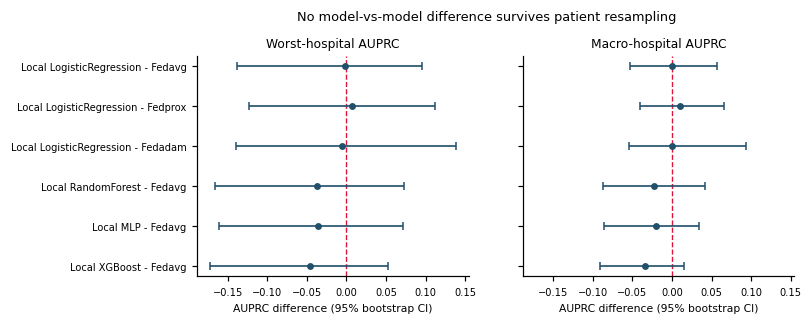

  saved figures/fig3_per_hospital_auprc_bootstrap.pdf / .png


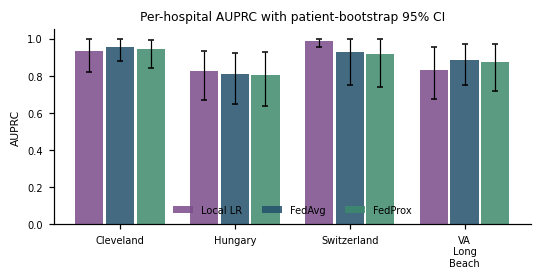

  saved figures/fig4_ci_width_seed_vs_bootstrap.pdf / .png


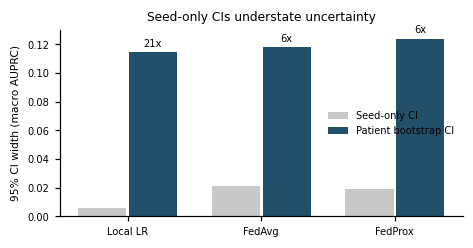

  saved figures/fig5_between_site_loho.pdf / .png


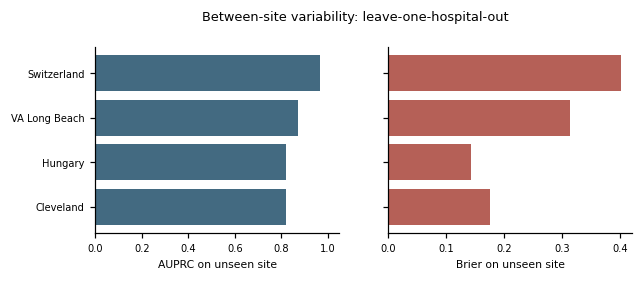


All figures written to ./figures/


In [53]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter

FIGDIR = "figures"
os.makedirs(FIGDIR, exist_ok=True)
IEEE_W, DPI = 3.5, 300
plt.rcParams.update({"font.size": 7, "axes.titlesize": 8, "axes.labelsize": 7,
                     "xtick.labelsize": 6.5, "ytick.labelsize": 6.5,
                     "legend.fontsize": 6.5, "figure.dpi": 110,
                     "savefig.bbox": "tight", "axes.spines.top": False,
                     "axes.spines.right": False})


def save(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(os.path.join(FIGDIR, f"{name}.{ext}"), dpi=DPI)
    print(f"  saved {FIGDIR}/{name}.pdf / .png")


# ---- Fig 2: forest plot of paired-bootstrap differences ---------------------
if "pair_df" in globals() and not pair_df.empty:
    pf = pair_df.copy()
    pf["label"] = (pf["model_a"].str.split("/").str[-1]
                     .str.replace("Local", "Local ", regex=False) + " - " +
                   pf["model_b"].str.split("/").str[-1].str.title())
    fig, axes = plt.subplots(1, 2, figsize=(IEEE_W * 2, 2.6), sharex=True)
    for ax, scope in zip(axes, ["worst", "macro"]):
        s = pf[pf["scope"] == scope].reset_index(drop=True)
        y = np.arange(len(s))
        ax.axvline(0, color="crimson", lw=0.9, ls="--", zorder=1)
        ax.errorbar(s["mean_diff"], y,
                    xerr=[s["mean_diff"] - s["ci_lo"], s["ci_hi"] - s["mean_diff"]],
                    fmt="o", ms=3.5, lw=1.1, capsize=2.5, color="#22506b", zorder=3)
        ax.set_yticks(y); ax.set_yticklabels(s["label"])
        ax.set_xlabel("AUPRC difference (95% bootstrap CI)")
        ax.set_title(f"{scope.capitalize()}-hospital AUPRC")
        ax.invert_yaxis()
    axes[1].tick_params(labelleft=False)
    fig.suptitle("No model-vs-model difference survives patient resampling", y=1.04)
    save(fig, "fig2_paired_bootstrap_forest"); plt.show()

# ---- Fig 3: per-hospital AUPRC, Local LR vs FL, bootstrap CI ----------------
COMPARE = [("local_only", "LocalLogisticRegression", "Local LR", "#7a4b8a"),
           ("federated_d0_private", "FEDAVG", "FedAvg", "#22506b"),
           ("federated_d0_private", "FEDPROX", "FedProx", "#3d8a6b")]
avail = [c for c in COMPARE if (c[0], c[1]) in PRED_STORE]
if avail:
    hs = sorted(hospitals)
    fig, ax = plt.subplots(figsize=(IEEE_W * 1.6, 2.3))
    w = 0.8 / len(avail)
    for k, (sec, alg, lab, col) in enumerate(avail):
        t = boot_fl_df[(boot_fl_df["section"] == sec) &
                       (boot_fl_df["algorithm"] == alg) &
                       (boot_fl_df["scope"] == "hospital") &
                       (boot_fl_df["metric"] == "auprc")].set_index("hospital")
        m = np.array([t.loc[h, "mean"] for h in hs])
        lo = np.array([t.loc[h, "mean"] - t.loc[h, "ci_lo"] for h in hs])
        hi = np.array([t.loc[h, "ci_hi"] - t.loc[h, "mean"] for h in hs])
        x = np.arange(len(hs)) + (k - (len(avail) - 1) / 2) * w
        ax.bar(x, m, w * 0.92, label=lab, color=col, alpha=0.85)
        ax.errorbar(x, m, yerr=[lo, hi], fmt="none", ecolor="black",
                    lw=0.8, capsize=1.8)
    ax.set_xticks(np.arange(len(hs)))
    ax.set_xticklabels([h.replace(" ", "\n") for h in hs])
    ax.set_ylabel("AUPRC"); ax.set_ylim(0, 1.05)
    ax.legend(frameon=False, ncol=len(avail), loc="lower center")
    ax.set_title("Per-hospital AUPRC with patient-bootstrap 95% CI")
    save(fig, "fig3_per_hospital_auprc_bootstrap"); plt.show()

# ---- Fig 4: seed-only vs bootstrap CI width --------------------------------
rows = []
for sec, alg, lab, _ in COMPARE:
    if (sec, alg) not in PRED_STORE:
        continue
    seed_macro = [np.nanmean([_metric_subset(*PRED_STORE[(sec, alg)][s]
                                             ["per_hospital"][h])["auprc"]
                              for h in PRED_STORE[(sec, alg)][s]["per_hospital"]])
                  for s in PRED_STORE[(sec, alg)]]
    _, lo_s, hi_s = ci_95(np.asarray(seed_macro, dtype=float))
    b = boot_fl_df[(boot_fl_df["section"] == sec) & (boot_fl_df["algorithm"] == alg) &
                   (boot_fl_df["scope"] == "macro") &
                   (boot_fl_df["metric"] == "auprc")].iloc[0]
    rows.append({"model": lab, "seed_only": hi_s - lo_s,
                 "bootstrap": b["ci_width"]})
if rows:
    w_df = pd.DataFrame(rows)
    fig, ax = plt.subplots(figsize=(IEEE_W * 1.35, 2.2))
    x = np.arange(len(w_df))
    ax.bar(x - 0.19, w_df["seed_only"], 0.36, label="Seed-only CI",
           color="#c8c8c8")
    ax.bar(x + 0.19, w_df["bootstrap"], 0.36, label="Patient bootstrap CI",
           color="#22506b")
    for xi, (a, b_) in enumerate(zip(w_df["seed_only"], w_df["bootstrap"])):
        ax.text(xi + 0.19, b_ + 0.004, f"{b_ / max(a, 1e-9):.0f}x",
                ha="center", fontsize=6.5)
    ax.set_xticks(x); ax.set_xticklabels(w_df["model"])
    ax.set_ylabel("95% CI width (macro AUPRC)")
    ax.legend(frameon=False)
    ax.set_title("Seed-only CIs understate uncertainty")
    save(fig, "fig4_ci_width_seed_vs_bootstrap"); plt.show()

# ---- Fig 5: between-site variability (LOHO) --------------------------------
if "site_df" in globals():
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(IEEE_W * 1.8, 2.2))
    o = site_df.sort_values("auprc")
    a1.barh(o["held_out"], o["auprc"], color="#22506b", alpha=0.85)
    a1.set_xlabel("AUPRC on unseen site"); a1.set_xlim(0, 1.05)
    a1.xaxis.set_major_formatter(FormatStrFormatter("%.1f"))
    a2.barh(o["held_out"], o["brier"], color="#a8443a", alpha=0.85)
    a2.set_xlabel("Brier on unseen site"); a2.tick_params(labelleft=False)
    fig.suptitle("Between-site variability: leave-one-hospital-out", y=1.03)
    save(fig, "fig5_between_site_loho"); plt.show()

print(f"\nAll figures written to ./{FIGDIR}/")

## 23. SHAP Feature Importance

Q1 - Global feature importance (FL model, mean |SHAP|):
                 feature  mean_abs_shap
                 oldpeak       0.093153
              exang_True       0.071517
                  thalch       0.044977
      cp_atypical angina       0.042496
                      ca       0.035564
             thal_normal       0.029845
          cp_non-anginal       0.026677
                sex_Male       0.026559
  thal_reversable defect       0.014561
                    chol       0.014517
                fbs_True       0.012685
            chol_missing       0.011426
                     age       0.010214
                trestbps       0.008303
restecg_st-t abnormality       0.008047


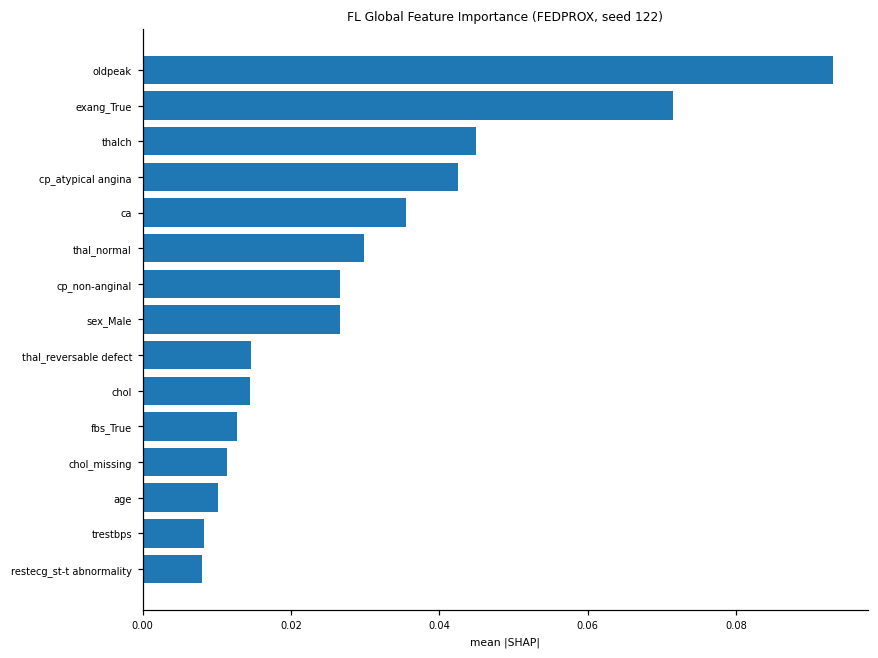

Saved: fl_shap_global.png

Train-only Logistic Regression coefficient ranking (FL, top 10):
 lr_rank            feature  coefficient  abs_coefficient direction
       1 cp_atypical angina      -1.8350           1.8350  negative
       2       chol_missing       1.0692           1.0692  positive
       3     cp_non-anginal      -1.0358           1.0358  negative
       4         exang_True       0.9912           0.9912  positive
       5           sex_Male       0.8572           0.8572  positive
       6                 ca       0.5421           0.5421  positive
       7            oldpeak       0.4409           0.4409  positive
       8        thal_normal      -0.3128           0.3128  negative
       9     restecg_normal      -0.2853           0.2853  negative
      10  cp_typical angina      -0.2506           0.2506  negative

LR coefficient rank vs SHAP rank (FL, top 10 by LR):
 lr_rank            feature  coefficient direction  shap_rank  mean_abs_shap  in_lr_top5  in_shap_top5
   

In [54]:
def lr_feature_coefficient_table(X_train, y_train, feature_cols, seed=42):
    """Fit train-only LR-L1 and return signed coefficient ranking."""
    clf = LogisticRegression(
        penalty="l1", solver="liblinear", class_weight="balanced",
        C=0.25, max_iter=2000, random_state=seed)
    selector_model = "logreg_l1"
    y_train = np.asarray(y_train).astype(int).ravel()
    try:
        clf.fit(X_train, y_train)
        coef = clf.coef_.ravel().astype(float)
    except Exception:
        coef = np.zeros(len(feature_cols), dtype=float)

    if not np.isfinite(coef).any() or np.nanmax(np.abs(coef)) <= 0:
        clf = LogisticRegression(
            penalty="l2", solver="liblinear", class_weight="balanced",
            C=1.0, max_iter=2000, random_state=seed)
        clf.fit(X_train, y_train)
        coef = clf.coef_.ravel().astype(float)
        selector_model = "logreg_l2_fallback"

    lr_df = pd.DataFrame({
        "feature": feature_cols,
        "coefficient": coef,
        "abs_coefficient": np.abs(coef),
        "direction": np.where(coef > 0, "positive",
                              np.where(coef < 0, "negative", "zero")),
        "selector_model": selector_model,
    }).sort_values("abs_coefficient", ascending=False).reset_index(drop=True)
    lr_df["lr_rank"] = np.arange(1, len(lr_df) + 1)
    return lr_df


# Best seed for best_fl_strategy at d=0% (private)
gdf_shap = all_results[f"{best_fl_strategy}_d0"]["global_df"]
shap_seed = int(gdf_shap.sort_values("best_val_auprc", ascending=False)
.iloc[0]["seed"])
out_shap  = all_results[f"{best_fl_strategy}_d0"]["out_by_seed"][shap_seed]
model_shap = all_results[f"{best_fl_strategy}_d0"]["models_by_seed"][shap_seed]
model_shap.eval()

feature_cols = out_shap["feature_cols"]
X_te_np = out_shap["X_test"]
df_te_h = out_shap["df_test"]   # original test DataFrame with HOSPITAL_COL
X_bg    = torch.tensor(X_te_np[:100].astype("float32"), dtype=torch.float32)

def model_predict(x):
    """SHAP-compatible numpy predict function."""
    with torch.no_grad():
        t  = torch.tensor(x.astype("float32"), dtype=torch.float32).to(DEVICE)
        lp = model_shap(t).squeeze(-1).cpu().numpy()
    return 1.0 / (1.0 + np.exp(-lp))

explainer = shap.Explainer(model_predict, X_bg.numpy(),
                             feature_names=feature_cols)
shap_vals  = explainer(X_te_np.astype("float32"))

# Q1 - global mean |SHAP|
mean_abs_shap = np.abs(shap_vals.values).mean(axis=0)
global_shap_df = pd.DataFrame({
    "feature": feature_cols, "mean_abs_shap": mean_abs_shap
}).sort_values("mean_abs_shap", ascending=False)
print("Q1 - Global feature importance (FL model, mean |SHAP|):")
print(global_shap_df.head(15).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 6))
top15 = global_shap_df.head(15)
ax.barh(top15["feature"][::-1], top15["mean_abs_shap"][::-1])
ax.set_xlabel("mean |SHAP|")
ax.set_title(f"FL Global Feature Importance ({best_fl_strategy.upper()}, seed {shap_seed})")
plt.tight_layout()
plt.savefig("fl_shap_global.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: fl_shap_global.png")
global_shap_df = global_shap_df.reset_index(drop=True)
global_shap_df["shap_rank"] = np.arange(1, len(global_shap_df) + 1)
global_shap_df.to_csv("fl_shap_global_importance.csv", index=False)

X_lr_train = np.vstack([
    pack["X_train"] for pack in out_shap["client_data"].values()
    if len(pack["X_train"]) > 0
])
y_lr_train = np.concatenate([
    np.asarray(pack["y_train"]).astype(int).ravel()
    for pack in out_shap["client_data"].values()
    if len(pack["y_train"]) > 0
])

fl_lr_feature_coefficients_df = lr_feature_coefficient_table(
    X_lr_train, y_lr_train, feature_cols, seed=shap_seed)
fl_lr_feature_coefficients_df.to_csv(
    "fl_lr_feature_coefficients.csv", index=False)

fl_lr_vs_shap_feature_comparison_df = (
    fl_lr_feature_coefficients_df
    .merge(global_shap_df[["feature", "mean_abs_shap", "shap_rank"]],
           on="feature", how="outer")
    .sort_values("lr_rank")
    .reset_index(drop=True)
)
fl_lr_vs_shap_feature_comparison_df["in_lr_top5"] = (
    fl_lr_vs_shap_feature_comparison_df["lr_rank"] <= 5)
fl_lr_vs_shap_feature_comparison_df["in_shap_top5"] = (
    fl_lr_vs_shap_feature_comparison_df["shap_rank"] <= 5)
fl_lr_vs_shap_feature_comparison_df["rank_gap_lr_minus_shap"] = (
    fl_lr_vs_shap_feature_comparison_df["lr_rank"]
    - fl_lr_vs_shap_feature_comparison_df["shap_rank"])
fl_lr_vs_shap_feature_comparison_df.to_csv(
    "fl_lr_vs_shap_feature_comparison.csv", index=False)

print("\nTrain-only Logistic Regression coefficient ranking (FL, top 10):")
print(fl_lr_feature_coefficients_df[
    ["lr_rank", "feature", "coefficient", "abs_coefficient", "direction"]
].head(10).to_string(index=False, float_format="%.4f"))
print("\nLR coefficient rank vs SHAP rank (FL, top 10 by LR):")
print(fl_lr_vs_shap_feature_comparison_df[
    ["lr_rank", "feature", "coefficient", "direction",
     "shap_rank", "mean_abs_shap", "in_lr_top5", "in_shap_top5"]
].head(10).to_string(index=False, float_format="%.4f"))
print("Saved: fl_shap_global_importance.csv, fl_lr_feature_coefficients.csv, "
      "fl_lr_vs_shap_feature_comparison.csv")


In [55]:
# Q2 - per-hospital SHAP rank correlation
hospitals_shap = df_te_h[HOSPITAL_COL].unique().tolist()
hosp_rankings  = {}
for hname in hospitals_shap:
    mask  = (df_te_h[HOSPITAL_COL].values == hname)
    n_hop = int(mask.sum())
    if n_hop == 0:
        continue
    idx   = np.where(mask)[0]
    vals  = np.abs(shap_vals.values[idx]).mean(axis=0)
    ranks = pd.Series(vals, index=feature_cols).rank(ascending=False)
    hosp_rankings[hname] = ranks

print("\nQ2 - Pairwise Spearman rank correlation of mean |SHAP| across hospitals")
hosp_list   = sorted(hosp_rankings.keys())
spearman_mat = np.zeros((len(hosp_list), len(hosp_list)))
for i, h1 in enumerate(hosp_list):
    for j, h2 in enumerate(hosp_list):
        r, _ = spearmanr(hosp_rankings[h1], hosp_rankings[h2])
        spearman_mat[i, j] = r

spearman_df = pd.DataFrame(spearman_mat, index=hosp_list, columns=hosp_list)
print(spearman_df.round(3).to_string())
off_diag    = spearman_mat[np.triu_indices_from(spearman_mat, k=1)]
print(f"\nMean pairwise Spearman r: {off_diag.mean():.4f}")
print(f"Min  pairwise Spearman r: {off_diag.min():.4f}")
print("High r => stable, generalizable feature importance across hospitals.")
print("Low  r => FL global model uses different features for different hospitals;")
print("         personalization may recapture hospital-specific important features.")



Q2 - Pairwise Spearman rank correlation of mean |SHAP| across hospitals
               Cleveland  Hungary  Switzerland  VA Long Beach
Cleveland          1.000    0.896        0.905          0.784
Hungary            0.896    1.000        0.919          0.832
Switzerland        0.905    0.919        1.000          0.798
VA Long Beach      0.784    0.832        0.798          1.000

Mean pairwise Spearman r: 0.8558
Min  pairwise Spearman r: 0.7843
High r => stable, generalizable feature importance across hospitals.
Low  r => FL global model uses different features for different hospitals;
         personalization may recapture hospital-specific important features.


## 24. IEEE Master Summary Table - FL Experiments

One table, mirroring Table Section 15 in the CL notebook, covering every metric dimension the paper needs to report for the FL experiments. Local-only per-hospital baselines are promoted into this master table because they answer the reviewer-critical question of whether federation improves over independently trained hospital models. Saved to `fl_master_summary.csv`.


In [56]:
master_rows = []
GLOBAL_METRICS = ["auroc", "auprc", "auprc_lift", "normalized_auprc",
                  "f1", "recall", "specificity", "balanced_accuracy",
                  "mcc", "brier"]
FAIRNESS_METRICS = ["auprc", "auprc_lift", "normalized_auprc", "auroc",
                    "balanced_accuracy", "specificity", "mcc"]

# 24.1 Global FL (private, all dropouts)
for algo in algorithms:
    for d in [0, 25, 50]:
        key = f"{algo}_d{d}"
        if key not in all_results:
            continue
        gdf = all_results[key]["global_df"]
        for metric in GLOBAL_METRICS:
            if metric not in gdf.columns:
                continue
            mu, lo, hi = ci_95(gdf[metric].dropna().values)
            master_rows.append({
                "section": "global_fl",
                "algorithm": algo.upper(), "dropout_pct": d,
                "preprocess_mode": all_results[key]["preprocess_mode"],
                "metric": metric,
                "mean": mu, "ci_lo": lo, "ci_hi": hi,
            })

# 24.2 Macro per-hospital (private, all dropouts)
macro_from_fl = macro_per_hospital_summary(all_results)
for algo in algorithms:
    for d in [0, 25, 50]:
        sub = macro_from_fl[(macro_from_fl["algorithm"] == algo) &
                             (macro_from_fl["dropout_pct"] == d)]
        for metric in [c for c in sub.columns if c.startswith("macro_")]:
            mu, lo, hi = ci_95(sub[metric].dropna().values)
            master_rows.append({
                "section": "macro_per_hospital",
                "algorithm": algo.upper(), "dropout_pct": d,
                "preprocess_mode": all_results[f"{algo}_d{d}"]["preprocess_mode"],
                "metric": metric,
                "mean": mu, "ci_lo": lo, "ci_hi": hi,
            })

# 24.3 Fairness (raw + prevalence-adjusted + threshold metrics)
for algo in algorithms:
    for d in [0, 25, 50]:
        key = f"{algo}_d{d}"
        if key not in all_results:
            continue
        ph = all_results[key]["per_hospital_df"]
        for fair_metric in FAIRNESS_METRICS:
            _, fair_summary = fairness_block(ph, metric=fair_metric)
            for scalar, s in fair_summary.items():
                master_rows.append({
                    "section": "fairness",
                    "algorithm": algo.upper(), "dropout_pct": d,
                    "preprocess_mode": all_results[key]["preprocess_mode"],
                    "metric": scalar,
                    "mean": s["mean"], "ci_lo": s["ci_lo"], "ci_hi": s["ci_hi"],
                })

# 24.4 Shared vs Private preprocessing (dropout=0%)
for algo in algorithms:
    for mode in ["shared", "private"]:
        key = f"{algo}_d0_shared" if mode == "shared" else f"{algo}_d0"
        if key not in all_results:
            continue
        gdf = all_results[key]["global_df"]
        for metric in GLOBAL_METRICS:
            if metric not in gdf.columns:
                continue
            mu, lo, hi = ci_95(gdf[metric].dropna().values)
            master_rows.append({
                "section": "preproc_comparison",
                "algorithm": algo.upper(), "dropout_pct": 0,
                "preprocess_mode": mode,
                "metric": metric,
                "mean": mu, "ci_lo": lo, "ci_hi": hi,
            })

# 24.5 Local-only per-hospital baselines
if "local_only_master_df" in globals():
    for _, r in local_only_master_df.iterrows():
        master_rows.append({
            "section": r.get("section", "local_only"),
            "algorithm": str(r.get("algorithm", "LOCAL_ONLY")).upper(),
            "dropout_pct": 0,
            "preprocess_mode": r.get("preprocess_mode", "private"),
            "metric": r["metric"],
            "mean": r["mean"], "ci_lo": r["ci_lo"], "ci_hi": r["ci_hi"],
        })

# 24.6 Personalization (global+topt vs personalized)
for r in pfl_master_df.to_dict("records"):
    master_rows.append({
        "section": "personalization",
        "algorithm": best_fl_strategy.upper(), "dropout_pct": 0,
        "preprocess_mode": "private",
        "metric": r["metric"],
        "mean":   r["personalized_fl"],
        "ci_lo":  r.get("personalized_ci_lo", np.nan),
        "ci_hi":  r.get("personalized_ci_hi", np.nan),
    })
    master_rows.append({
        "section": "personalization_baseline",
        "algorithm": best_fl_strategy.upper(), "dropout_pct": 0,
        "preprocess_mode": "private",
        "metric": r["metric"],
        "mean":   r["global_fl_topt"],
        "ci_lo":  r.get("global_ci_lo", np.nan),
        "ci_hi":  r.get("global_ci_hi", np.nan),
    })

# 24.7 Optional reviewer-facing additions
for optional_df_name in [
    "fedxgb_master_df", "fl_loho_master_df",
    "fl_small_data_sensitivity_summary_df",
    "fl_norm_ablation_master_df", "dp_fedavg_master_df", "fedrep_master_df",
    "scaffold_adam_master_df"
]:
    if optional_df_name not in globals():
        continue
    opt_df = globals()[optional_df_name]
    for _, r in opt_df.iterrows():
        master_rows.append({
            "section": r.get("section", optional_df_name),
            "algorithm": str(r.get("algorithm", optional_df_name)).upper(),
            "dropout_pct": 0,
            "preprocess_mode": r.get("preprocess_mode", "private"),
            "metric": r["metric"],
            "mean": r["mean"], "ci_lo": r["ci_lo"], "ci_hi": r["ci_hi"],
        })

fl_master_df = pd.DataFrame(master_rows)
fl_master_df.to_csv("fl_master_summary.csv", index=False)
print(f"Master summary saved: fl_master_summary.csv  ({len(fl_master_df)} rows)")
print()
print(fl_master_df.groupby("section")["metric"].count().to_string())


Master summary saved: fl_master_summary.csv  (1397 rows)

section
dp_fedavg                                36
fairness                                588
fl_loho_unseen_hospital                  14
fl_small_data_sensitivity_summary_df     20
global_fl                               120
local_only                               36
local_only_fairness                     196
macro_per_hospital                       60
normalization_ablation                   27
normalization_ablation_fairness         147
personalization                           8
personalization_baseline                  8
pfl_algorithm                            15
preproc_comparison                       80
scaffold_optimizer_diagnostic            27
tree_fl_baseline                         15


## 24.1 Repeated External Test Splits - *Split Luck*

The bootstrap resamples patients but never leaves the test partition drawn at
`TEST_SEED = 42`. It cannot tell us whether that split was lucky. Here the full FL
protocol - including per-cell hyperparameter retuning - is rerun on several
independently drawn external test splits, and we report the spread across them.

This is the expensive one. Set `RUN_MULTI_SPLIT = False` to skip.

In [57]:
if RUN_MULTI_SPLIT:
    print(f"Repeated-split FL: {len(TEST_SEEDS)} splits x "
          f"{len(MULTI_SPLIT_ALGOS)} algorithms x "
          f"{len(MULTI_SPLIT_SEEDS)} seeds", flush=True)
    fl_split_rows = []
    for ts in TEST_SEEDS:
        for algo in MULTI_SPLIT_ALGOS:
            print(f"\n  test_seed={ts} | {algo.upper()}", flush=True)
            res = run_algorithm_repeated(
                df, algo, dropout_rate=0.0, min_active=2,
                seeds=MULTI_SPLIT_SEEDS,
                checkpoint_dir=CHECKPOINT_DIR_PRIV,
                preprocess_mode="private", verbose=False,
                test_seed=ts, register_preds=False)
            ph = res["per_hospital_df"]
            for seed in MULTI_SPLIT_SEEDS:
                g = res["global_df"]
                g = g[g["seed"] == seed].iloc[0]
                hs = ph[ph["seed"] == seed]["auprc"].values
                fl_split_rows.append({
                    "test_seed": ts, "algorithm": algo.upper(), "seed": seed,
                    "auprc": float(g["auprc"]), "auroc": float(g["auroc"]),
                    "brier": float(g["brier"]),
                    "macro_auprc": float(np.nanmean(hs)),
                    "worst_auprc": float(np.nanmin(hs))})

    fl_split_df = pd.DataFrame(fl_split_rows)
    fl_split_df.to_csv("fl_multi_split_by_run.csv", index=False)

    print("\n\nBetween-split variability, per algorithm")
    print("=" * 84)
    fl_split_summary = []
    for algo, sub_ in fl_split_df.groupby("algorithm"):
        per_split = sub_.groupby("test_seed").mean(numeric_only=True)
        print(f"\n  {algo}")
        for m in ["auprc", "macro_auprc", "worst_auprc", "brier"]:
            v = per_split[m].values
            fl_split_summary.append({
                "algorithm": algo, "metric": m, "mean": float(v.mean()),
                "sd_across_splits": float(v.std(ddof=1)),
                "min": float(v.min()), "max": float(v.max()),
                "range": float(v.max() - v.min())})
            print(f"    {m:12s}: {v.mean():.4f}  sd={v.std(ddof=1):.4f}  "
                  f"range=[{v.min():.4f}, {v.max():.4f}]")
    fl_split_summary_df = pd.DataFrame(fl_split_summary)
    fl_split_summary_df.to_csv("fl_multi_split_summary.csv", index=False)
    print("\nSaved: fl_multi_split_by_run.csv, fl_multi_split_summary.csv")
else:
    print("RUN_MULTI_SPLIT = False - skipped.")

Repeated-split FL: 5 splits x 3 algorithms x 3 seeds

  test_seed=42 | FEDAVG

Tune FEDAVG | dropout=0% | preproc=private

  test_seed=42 | FEDPROX

Tune FEDPROX | dropout=0% | preproc=private

  test_seed=42 | FEDADAM

Tune FEDADAM | dropout=0% | preproc=private

  test_seed=202 | FEDAVG

Tune FEDAVG | dropout=0% | preproc=private

  test_seed=202 | FEDPROX

Tune FEDPROX | dropout=0% | preproc=private

  test_seed=202 | FEDADAM

Tune FEDADAM | dropout=0% | preproc=private

  test_seed=303 | FEDAVG

Tune FEDAVG | dropout=0% | preproc=private

  test_seed=303 | FEDPROX

Tune FEDPROX | dropout=0% | preproc=private

  test_seed=303 | FEDADAM

Tune FEDADAM | dropout=0% | preproc=private

  test_seed=404 | FEDAVG

Tune FEDAVG | dropout=0% | preproc=private

  test_seed=404 | FEDPROX

Tune FEDPROX | dropout=0% | preproc=private

  test_seed=404 | FEDADAM

Tune FEDADAM | dropout=0% | preproc=private

  test_seed=505 | FEDAVG

Tune FEDAVG | dropout=0% | preproc=private

  test_seed=505 | FEDPR

## 25. Reading The Master Table - Paper Contribution Summary

The `fl_master_summary.csv` file is the authoritative source for the FL numbers in the
paper.

**global_fl** - Comparison of FedAvg / FedProx / FedAdam across client dropout
settings. Use AUPRC and AUROC as headline discrimination metrics, but interpret them with
macro and worst-hospital results.

**macro_per_hospital** - A fairness-aware counterpart to global performance. If macro
performance diverges from global performance, the model is concentrating utility in some
hospitals more than others.

**fairness (not reported in the paper)** - Worst-hospital, gap, coefficient of variation, and Jain's Fairness Index on
AUPRC. These are primary FL deployment metrics, because a clinically useful FL system must
not only optimize the pooled population.

**preproc_comparison (not reported in the paper)** - Shared preprocessing is an optimistic benchmark that leaks
population statistics. Local preprocessing better respects data locality, but it is not a
formal privacy guarantee.

**personalization** - PFL is a secondary analysis. Claims require survival of the
paired bootstrap in Section 22.11, not the seed-level Holm-corrected test. On this
corpus no PFL comparison is resolvable (macro Brier p = 0.622; macro AUPRC
p = 1.000), and that negative result is what the paper reports.

**local_only** - Independent per-hospital baselines, including Local-MLP, logistic regression, random forest, and XGBoost. This is a primary comparator: FL should be discussed against these rows before claiming that federation adds value over training local models only.

**local_only_fairness** - Worst-hospital and cross-hospital disparity metrics for the local-only baselines. Use this section to answer whether FL improves macro or worst-hospital behavior, not only pooled global performance.

**tree_fl_baseline (not reported in the paper)** - Local XGBoost-per-hospital ensemble. This is a tree-based
federated comparator, but not a claim of native FedTree/Federated-XGBoost training.

**dp_fedavg (not reported in the paper)** - DP-FedAvg utility/privacy sweep. Use the epsilon values as an experiment
diagnostic and discuss that SecAgg and a production threat model remain out of scope.

**pfl_algorithm (not reported in the paper)** - FedRep-style training-time personalization. Compare this against the
post-hoc fine-tuning PFL table before making any PFL claim.

**normalization_ablation (not reported in the paper)** - BatchNorm / LayerNorm / no-normalization sensitivity analysis. BatchNorm running statistics are client-distribution dependent in non-IID FL; these rows document that limitation and provide LayerNorm/no-norm comparators.
